# Riesgo de evento adverso en el primer año después de un trasplante de médula ósea

Proyecto final de la materia de Aprendizaje Automatico. Especialización en Inteligencia Artificial, Universidad Pedagógica y Tecnológica de Colombia.

Estudiante: Oscar David Perilla Dominguez

Codigo: 202624578


Objetivo: estimar, con la información disponible antes del trasplante, la probabilidad de que un paciente tenga un evento adverso en los primeros 12 meses, y explicar de qué depende esa estimación.

## Índice

1. Problema y contexto
2. Datos y diccionario de variables
3. Calidad y limpieza de los datos
    - 3.1 Valores nulos por variable
    - 3.2 Limpieza: de df_raw a df_clean
4. Variable objetivo y partición de los datos
5. Análisis exploratorio
    - 5.1 Edad del paciente y del donante
    - 5.2 Variables clínicas principales
    - 5.3 Compatibilidad HLA
    - 5.4 Quién tiene datos vacíos
    - 5.5 Datos vacíos y seguimiento en el tiempo
    - 5.6 Conclusiones del análisis exploratorio
6. Preparación de datos: Pipeline, representación de las variables, imputación y reducción de dimensión
7. Balanceo de clases: prueba con SMOTE
8. Comparación de modelos
9. Ajuste de hiperparámetros con GridSearchCV
10. Evaluación final en df_test
    - 10.1 Matriz de confusión y curvas
    - 10.2 Riesgo por deciles
    - 10.3 Desempeño por subgrupo
    - 10.4 Errores del modelo
11. Análisis a 6, 12 y 18 meses
12. Explicabilidad
    - 12.1 Cómo leer las contribuciones: log-odds y probabilidad
    - 12.2 Importancia por permutación
    - 12.3 SHAP: efecto de cada variable
    - 12.4 Explicación de pacientes individuales
13. Exportación del modelo y registro en MLflow
14. Conclusiones, condiciones de validez y próximos pasos

# 0. Entorno y reproducibilidad

El notebook fue ejecutado en local, dentro del entorno virtual del proyecto que crea uv, y desde la raíz del proyecto:


Para temas de replicabilidad, debera ejecutar los siguientes comandos
```
uv sync
uv run python -m jupyterlab
```

Para ejecutarlo completo y guardar todas las salidas en el mismo archivo:

```
uv run python -m nbconvert --to notebook --execute --inplace Proyecto_Final_ML_Riesgo_Post_Trasplante_Enviar.ipynb
```

Dónde queda cada resultado:

- MLflow registra dentro del proyecto, en la carpeta mlruns/, los experimentos, la comparación de modelos, cada combinación de la búsqueda de hiperparámetros, las métricas, las gráficas y los modelos. Para verlos: `uv run python -m mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` y abrir http://127.0.0.1:5000.
- Las figuras se guardan en imagenes/ (las usa el reporte) y los artefactos del modelo en despliegue/artefactos/ (los usa la aplicación).

In [1]:
import json
import logging
import os
import platform
import random
import time
import warnings
from datetime import datetime
from pathlib import Path

os.environ["PYTHONHASHSEED"] = "42"
os.environ["MLFLOW_DISABLE_TELEMETRY"] = "true"
os.environ["DO_NOT_TRACK"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost
import shap
import imblearn
import mlflow
import mlflow.data
from mlflow.tracking import MlflowClient
from scipy import stats

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, balanced_accuracy_score, log_loss,
                             classification_report, confusion_matrix, roc_curve, precision_recall_curve,
                             recall_score, precision_score, brier_score_loss)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImblearn

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
AZUL, ROJO, GRIS, VERDE, OCRE = "#2F5D8A", "#B5443B", "#8C8C8C", "#3E7C5A", "#C08A2B"
VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__, "joblib": joblib.__version__, "xgboost": xgboost.__version__,
             "imbalanced-learn": imblearn.__version__, "mlflow": mlflow.__version__,
             "shap": shap.__version__}
print(" | ".join(f"{k} {v}" for k, v in VERSIONES.items()))

python 3.12.10 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | joblib 1.6.0 | xgboost 3.4.1 | imbalanced-learn 0.14.2 | mlflow 3.18.0 | shap 0.54.1


In [2]:
%matplotlib inline

In [3]:
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
# Un hilo por modelo y todos los núcleos en paralelo con n_jobs -1
HILOS_POR_MODELO = 1

# Carpetas del proyecto
RAIZ = Path.cwd()
CARPETA_DATOS = RAIZ / "data"
CARPETA_IMAGENES = RAIZ / "imagenes"
CARPETA_ARTEFACTOS = RAIZ / "despliegue" / "artefactos"
CARPETA_MLRUNS = RAIZ / "mlruns"
assert (CARPETA_DATOS / "train.csv").exists(), "Ejecuta el notebook desde la raíz del proyecto, donde está la carpeta data/"
for carpeta in (CARPETA_IMAGENES, CARPETA_ARTEFACTOS, CARPETA_MLRUNS):
    carpeta.mkdir(parents=True, exist_ok=True)

# MLflow guarda todo dentro de mlruns
logging.getLogger("mlflow").setLevel(logging.ERROR)
mlflow.set_tracking_uri(f"sqlite:///{(CARPETA_MLRUNS / 'mlflow.db').as_posix()}")
EXPERIMENTO = "riesgo_post_trasplante"
if mlflow.get_experiment_by_name(EXPERIMENTO) is None:
    mlflow.create_experiment(EXPERIMENTO, artifact_location=(CARPETA_MLRUNS / "artifacts").as_uri())
mlflow.set_experiment(EXPERIMENTO)
cliente_mlflow = MlflowClient()
ID_EJECUCION = datetime.now().strftime("%Y%m%d-%H%M%S")


def iniciar_run(nombre, **kwargs):
    # Run marcado con el id de esta ejecución
    return mlflow.start_run(run_name=nombre, tags={"ejecucion": ID_EJECUCION}, **kwargs)


def registrar_variante(nombre, parametros, metricas):
    # Run anidado para una variante de un experimento
    with iniciar_run(nombre, nested=True):
        mlflow.log_params(parametros)
        mlflow.log_metrics(metricas)


def registrar_metricas(run_id, metricas):
    # Métricas extra en un run existente
    with mlflow.start_run(run_id=run_id):
        mlflow.log_metrics({k: float(v) for k, v in metricas.items()})


def registrar_tabla(run_id, tabla, nombre):
    # Tabla en CSV dentro de un run
    cliente_mlflow.log_text(run_id, tabla.to_csv(), f"tablas/{nombre}.csv")


def guardar_figura(nombre, run_id=None):
    # Figura en imagenes y opcionalmente en MLflow
    ruta = CARPETA_IMAGENES / f"{nombre}.png"
    plt.savefig(ruta, dpi=110, bbox_inches="tight")
    if run_id is not None:
        cliente_mlflow.log_artifact(run_id, str(ruta), "figuras")


print(f"Ejecución {ID_EJECUCION} | experimento de MLflow: {EXPERIMENTO} | núcleos del equipo: {os.cpu_count()}")

Ejecución 20261107-073216 | experimento de MLflow: riesgo_post_trasplante | núcleos del equipo: 20


# 1. Problema y contexto

El trasplante alogénico de células hematopoyéticas (HCT, conocido como trasplante de médula ósea) reemplaza la médula enferma de un paciente con células sanas de un donante. Puede curar leucemias y otras enfermedades graves de la sangre, pero en el primer año muchos pacientes tienen un evento adverso.

Qué es el evento en este proyecto: el diccionario de la competencia llama a la variable resultado efs, supervivencia libre de eventos. Un paciente con efs igual a 1 perdió esa condición, es decir, tuvo un evento grave después del trasplante (en trasplante este indicador agrupa sucesos como la recaída de la enfermedad, la falla del injerto o la muerte). efs_time dice cuántos meses pasaron hasta ese evento o hasta el último control. En todo el notebook, "evento" o "evento en 12 meses" se refiere a esto.

Cómo se mide el éxito: la métrica principal es el AUC-ROC. Responde a esta pregunta: si se toma al azar un paciente que tuvo el evento y otro que no, ¿con qué frecuencia el modelo le asigna más riesgo al primero? Un AUC de 0.5 es lanzar una moneda y 1.0 es acertar siempre. Se complementa con el recall (cuántos eventos reales detecta el modelo), la precision (cuántas alertas son correctas) y la calibración (si un riesgo de 30% significa de verdad 3 de cada 10 pacientes).


**Nota: Es importante mencionar que a partir de ahora, se reconoce a un evento como la clasificación de si este paciente ha tenido algun tema relacionado con la recaida de la enfermedad, la muerte o alguna afectación de este estilo, en el dataset de Kaggle esto es reconocido como efs, una categoria de 1 es que ha sucedido dicho evento, y un 0 es que la persona no ha tenido ninguna afectación.**

# 2. Datos y diccionario de variables

Los datos son los de la competencia CIBMTR, Equity in post-HCT Survival Predictions, de Kaggle: 28,800 pacientes con 57 variables registradas antes del trasplante, un identificador y dos columnas de resultado. Son datos sintéticos: el CIBMTR los generó a partir de su registro real para proteger la privacidad de los pacientes, así que reproducen sus patrones pero no corresponden a personas reales. Los archivos train.csv y data_dictionary.csv se guardan en la carpeta data/ del proyecto.

Los nombres originales son abreviaturas en inglés difíciles de leer (por ejemplo hla_match_drb1_low o tce_imm_match). Se renombraron en español a partir de la descripción de cada variable en el diccionario oficial de la competencia, publicado en https://www.kaggle.com/competitions/equity-post-HCT-survival-predictions/data. Los valores de cada variable se dejan como vienen en la fuente.

Para realizar una revisión exahustiva del proyecto y el codigo que este contiene, puede revisar el repositorio de GitHub: https://github.com/ng0-k1/proyecto_hct_especializacion

In [4]:
df_raw = pd.read_csv(CARPETA_DATOS / "train.csv", encoding="utf-8")
df_diccionario = pd.read_csv(CARPETA_DATOS / "data_dictionary.csv", encoding="utf-8")
with iniciar_run("datos_y_analisis_exploratorio") as run:
    RUN_DATOS = run.info.run_id
    mlflow.log_params({"archivo_datos": "data/train.csv", "pacientes": df_raw.shape[0], "columnas": df_raw.shape[1], "semilla": SEMILLA})
print(f"Pacientes: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
df_raw.head(3)

Pacientes: 28,800 | Columnas: 60


,ID,dri_score,psych_disturb,cyto_score,diabetes,hla_match_c_high,hla_high_res_8,tbi_status,arrhythmia,hla_low_res_6,...,tce_div_match,donor_related,melphalan_dose,hla_low_res_8,cardiac,hla_match_drb1_high,pulm_moderate,hla_low_res_10,efs,efs_time
0,0,N/A - non-malignant indication,No,NaN,No,NaN,NaN,No TBI,No,6.0,...,NaN,Unrelated,"N/A, Mel not given",8.0,No,2.0,No,10.0,0.0,42.356
1,1,Intermediate,No,Intermediate,No,2.0,8.0,"TBI +- Other, >cGy",No,6.0,...,Permissive mismatched,Related,"N/A, Mel not given",8.0,No,2.0,Yes,10.0,1.0,4.672
2,2,N/A - non-malignant indication,No,NaN,No,2.0,8.0,No TBI,No,6.0,...,Permissive mismatched,Related,"N/A, Mel not given",8.0,No,2.0,No,10.0,0.0,19.793


In [5]:
# Nombres en español tomados del diccionario oficial
NOMBRES = {
    "ID": "id", "efs": "evento", "efs_time": "meses_hasta_evento",
    "dri_score": "indice_riesgo_enfermedad", "psych_disturb": "trastorno_psiquiatrico", "cyto_score": "puntaje_citogenetico",
    "diabetes": "diabetes", "hla_match_c_high": "hla_c_alta_res", "hla_high_res_8": "hla_alta_res_8",
    "tbi_status": "irradiacion_corporal_total", "arrhythmia": "arritmia", "hla_low_res_6": "hla_baja_res_6",
    "graft_type": "tipo_injerto", "vent_hist": "antecedente_ventilacion", "renal_issue": "enfermedad_renal",
    "pulm_severe": "enfermedad_pulmonar_severa", "prim_disease_hct": "enfermedad_principal", "hla_high_res_6": "hla_alta_res_6",
    "cmv_status": "serologia_cmv", "hla_high_res_10": "hla_alta_res_10", "hla_match_dqb1_high": "hla_dqb1_alta_res",
    "tce_imm_match": "epitopos_t_inmunogenicidad", "hla_nmdp_6": "hla_nmdp_6", "hla_match_c_low": "hla_c_baja_res",
    "rituximab": "rituximab", "hla_match_drb1_low": "hla_drb1_baja_res", "hla_match_dqb1_low": "hla_dqb1_baja_res",
    "prod_type": "tipo_producto", "cyto_score_detail": "citogenetica_detalle", "conditioning_intensity": "intensidad_acondicionamiento",
    "ethnicity": "etnicidad", "year_hct": "anio_trasplante", "obesity": "obesidad", "mrd_hct": "enfermedad_minima_residual",
    "in_vivo_tcd": "deplecion_celulas_t", "tce_match": "epitopos_t_compatibilidad", "hla_match_a_high": "hla_a_alta_res",
    "hepatic_severe": "enfermedad_hepatica_severa", "donor_age": "edad_donante", "prior_tumor": "tumor_previo",
    "hla_match_b_low": "hla_b_baja_res", "peptic_ulcer": "ulcera_peptica", "age_at_hct": "edad_paciente",
    "hla_match_a_low": "hla_a_baja_res", "gvhd_proph": "profilaxis_injerto_huesped", "rheum_issue": "enfermedad_reumatologica",
    "sex_match": "sexo_donante_receptor", "hla_match_b_high": "hla_b_alta_res", "race_group": "grupo_racial",
    "comorbidity_score": "indice_comorbilidad_sorror", "karnofsky_score": "escala_karnofsky", "hepatic_mild": "enfermedad_hepatica_leve",
    "tce_div_match": "epitopos_t_diversidad", "donor_related": "donante_emparentado", "melphalan_dose": "dosis_melfalan",
    "hla_low_res_8": "hla_baja_res_8", "cardiac": "enfermedad_cardiaca", "hla_match_drb1_high": "hla_drb1_alta_res",
    "pulm_moderate": "enfermedad_pulmonar_moderada", "hla_low_res_10": "hla_baja_res_10",
}
descripcion_oficial = dict(zip(df_diccionario["variable"], df_diccionario["description"]))
tabla_diccionario = pd.DataFrame({
    "nombre_original": list(NOMBRES),
    "nombre_nuevo": list(NOMBRES.values()),
    "descripcion_oficial": [descripcion_oficial.get(c, "Identificador del paciente") for c in NOMBRES],
    "nulos_pct": [round(df_raw[c].isna().mean() * 100, 1) for c in NOMBRES],
})
pd.set_option("display.max_rows", 70)
pd.set_option("display.max_colwidth", 80)
tabla_diccionario

,nombre_original,nombre_nuevo,descripcion_oficial,nulos_pct
0,ID,id,Identificador del paciente,0.0
1,efs,evento,Event-free survival,0.0
2,efs_time,meses_hasta_evento,"Time to event-free survival, months",0.0
3,dri_score,indice_riesgo_enfermedad,Refined disease risk index,0.5
4,psych_disturb,trastorno_psiquiatrico,Psychiatric disturbance,7.2
5,cyto_score,puntaje_citogenetico,Cytogenetic score,28.0
6,diabetes,diabetes,Diabetes,7.4
7,hla_match_c_high,hla_c_alta_res,Recipient / 1st donor allele level (high resolution) matching at HLA-C,16.0
8,hla_high_res_8,hla_alta_res_8,"Recipient / 1st donor allele-level (high resolution) matching at HLA-A,-B,-C...",20.2
9,tbi_status,irradiacion_corporal_total,TBI,0.0


Análisis: las 60 columnas de df_raw quedan con un nombre en español y su descripción oficial al lado. La columna nulos_pct ya anticipa el principal problema de calidad: varias variables, sobre todo las genéticas, tienen entre 10% y 66% de pacientes sin el dato.

La enfermedad principal viene como un código. Su significado se tomó del manual de formularios del CIBMTR, en https://www.manula.com/manuals/cibmtr/formsnet3-training-guide/1/en/topic/disease-codes. El dataset usa HD para el linfoma de Hodgkin, que en el manual aparece como HL. Los nombres se usan solo como etiquetas de las gráficas.

In [6]:
# Nombre de cada código de enfermedad según el manual del CIBMTR
NOMBRES_ENFERMEDAD = {
    "AML": "Leucemia mieloide aguda", "ALL": "Leucemia linfoblástica aguda", "MDS": "Síndrome mielodisplásico",
    "IPA": "Anomalías plaquetarias hereditarias", "MPN": "Enfermedad mieloproliferativa",
    "IEA": "Anomalías hereditarias de los eritrocitos", "NHL": "Linfoma no Hodgkin", "IIS": "Trastornos del sistema inmune",
    "PCD": "Mieloma o trastorno de células plasmáticas", "SAA": "Anemia aplásica", "AI": "Enfermedad autoinmune",
    "HIS": "Enfermedad histiocítica", "IMD": "Trastornos hereditarios del metabolismo", "HD": "Linfoma de Hodgkin",
    "CML": "Leucemia mieloide crónica", "Other leukemia": "Otra leucemia", "Other acute leukemia": "Otra leucemia aguda",
    "Solid tumor": "Tumor sólido",
}
etiqueta_enfermedad = lambda codigo: f"{codigo}: {NOMBRES_ENFERMEDAD.get(codigo, codigo)}"
df_raw["prim_disease_hct"].value_counts().rename(index=etiqueta_enfermedad).rename("pacientes").to_frame()

,pacientes
prim_disease_hct,
ALL: Leucemia linfoblástica aguda,8102
AML: Leucemia mieloide aguda,7135
MDS: Síndrome mielodisplásico,3046
IPA: Anomalías plaquetarias hereditarias,1719
MPN: Enfermedad mieloproliferativa,1656
IEA: Anomalías hereditarias de los eritrocitos,1449
NHL: Linfoma no Hodgkin,1319
IIS: Trastornos del sistema inmune,1024
PCD: Mieloma o trastorno de células plasmáticas,869


Análisis: las leucemias agudas (ALL y AML) y el síndrome mielodisplásico suman más de la mitad de los pacientes. El resto son enfermedades menos frecuentes, varias de ellas hereditarias o no malignas, que se comportan muy distinto en el riesgo, como se verá en el análisis exploratorio.

# 3. Calidad y limpieza de los datos

## 3.1 Valores nulos por variable

Filas duplicadas: 0 | IDs repetidos: 0
Variables categóricas: 35 | numéricas: 25


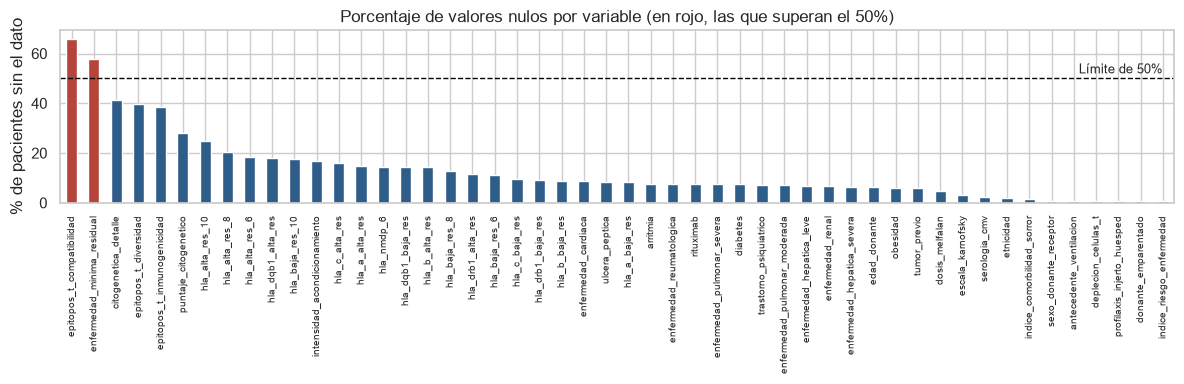

In [7]:
# Duplicados tipos y porcentaje de nulos por variable
print("Filas duplicadas:", df_raw.duplicated().sum(), "| IDs repetidos:", df_raw["ID"].duplicated().sum())
print("Variables categóricas:", df_raw.select_dtypes(exclude="number").shape[1], "| numéricas:", df_raw.select_dtypes("number").shape[1])
nulos_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(12, 4))
nulos_pct[nulos_pct > 0].rename(index=NOMBRES).plot(kind="bar", ax=ax, color=[ROJO if v > 50 else AZUL for v in nulos_pct[nulos_pct > 0]])
ax.axhline(50, color="black", linestyle="--", linewidth=1)
ax.text(len(nulos_pct[nulos_pct > 0]) - 1, 52, "Límite de 50%", ha="right", fontsize=9)
ax.set_ylabel("% de pacientes sin el dato")
ax.set_title("Porcentaje de valores nulos por variable (en rojo, las que superan el 50%)")
ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
guardar_figura("nulos_variables", RUN_DATOS)

Análisis: no hay filas ni pacientes duplicados. Dos variables superan el 50% de nulos y se eliminan: epitopos_t_compatibilidad (66.0%) y enfermedad_minima_residual (57.6%). Les siguen citogenetica_detalle (41.4%), epitopos_t_diversidad y epitopos_t_inmunogenicidad (cerca de 39%) y las 17 variables HLA (entre 8% y 25%). Todas estas son variables genéticas, es decir, resultados de pruebas de laboratorio sobre la enfermedad o sobre qué tan compatibles son el paciente y el donante. Entre las clínicas, la que más nulos tiene es la intensidad del acondicionamiento (16.6%).

## 3.2 Limpieza: de df_raw a df_clean

df_raw es el archivo tal como viene. df_clean es el resultado de reglas fijas que se aplican fila por fila, no usan la variable objetivo ni aprenden nada de otros pacientes, así que se pueden aplicar antes de partir los datos sin pasar información entre conjuntos.

- Se eliminan las variables con más de 50% de nulos.
- Variables genéticas. Son 21: las 17 de compatibilidad HLA, puntaje_citogenetico, citogenetica_detalle, epitopos_t_diversidad y epitopos_t_inmunogenicidad. Si el dato no está, lo más probable es que la prueba no se hizo o no correspondía al caso, así que llenarlo con un promedio inventaría un resultado genético. Las 17 HLA son conteos de coincidencias entre paciente y donante, así que quedan como números enteros y el dato faltante se marca con -1. Las otras cuatro son categorías y el dato faltante se marca como No aplica.
- Edades y escalas como números enteros. La edad del paciente y la del donante vienen con decimales; se pasan a años cumplidos, como se registra una edad en la práctica. El índice de Sorror y la escala de Karnofsky son escalas de puntos enteros y se guardan como enteros.
- Se crean cinco variables nuevas: la diferencia de edad entre donante y paciente (en años enteros y sin signo, porque mide qué tan lejos están las dos edades; la dirección ya la dan las dos edades), si el paciente es pediátrico, el número de comorbilidades, si recibió irradiación corporal total y el índice de riesgo de la enfermedad agrupado en seis grupos (Bajo, Intermedio, Alto, Muy alto, No aplica y Pendiente).

Los nulos que quedan en las demás variables se llenan más adelante dentro del Pipeline, para que ese paso aprenda solo de df_train.

In [8]:
COLUMNAS_ELIMINADAS = [NOMBRES[c] for c in df_raw.columns if df_raw[c].isna().mean() > 0.5]
COLUMNAS_HLA = sorted(c for c in NOMBRES.values() if c.startswith("hla_"))
VARIABLES_GENETICAS = sorted(v for v in [c for c in NOMBRES.values() if c.startswith("epitopos_t_")]
                             + ["puntaje_citogenetico", "citogenetica_detalle"] if v not in COLUMNAS_ELIMINADAS)
COLUMNAS_ENTERAS = ["edad_paciente", "edad_donante", "indice_comorbilidad_sorror", "escala_karnofsky"]
COMORBILIDADES = ["trastorno_psiquiatrico", "diabetes", "arritmia", "enfermedad_renal", "enfermedad_pulmonar_severa",
                  "enfermedad_pulmonar_moderada", "enfermedad_hepatica_severa", "enfermedad_hepatica_leve", "obesidad",
                  "tumor_previo", "ulcera_peptica", "enfermedad_reumatologica", "enfermedad_cardiaca"]
GRUPO_RIESGO = {
    "Low": "Bajo", "Intermediate": "Intermedio", "Intermediate - TED AML case <missing cytogenetics": "Intermedio",
    "High": "Alto", "High - TED AML case <missing cytogenetics": "Alto", "Very high": "Muy alto",
    "N/A - non-malignant indication": "No aplica", "N/A - pediatric": "No aplica", "N/A - disease not classifiable": "No aplica",
    "TBD cytogenetics": "Pendiente", "Missing disease status": "Pendiente",
}


def limpiar_datos(df, columnas_eliminadas):
    df = df.rename(columns=NOMBRES).drop(columns=columnas_eliminadas, errors="ignore")
    # Genéticas de texto sin dato como No aplica
    for c in VARIABLES_GENETICAS:
        df[c] = df[c].astype(object).where(df[c].notna(), "No aplica").astype(str)
    # HLA como conteo entero con -1 cuando no hay dato
    for c in COLUMNAS_HLA:
        df[c] = pd.to_numeric(df[c], errors="coerce").fillna(-1).astype(int)
    # Edades en años cumplidos y escalas como enteros
    df[["edad_paciente", "edad_donante"]] = np.floor(df[["edad_paciente", "edad_donante"]].astype(float))
    for c in COLUMNAS_ENTERAS:
        df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
    # Variables nuevas
    df["dif_edad_donante"] = (df["edad_donante"] - df["edad_paciente"]).abs()
    df["es_pediatrico"] = (df["edad_paciente"] < 18).astype("Int64")
    df["n_comorbilidades"] = (df[COMORBILIDADES] == "Yes").sum(axis=1)
    irradiacion = df["irradiacion_corporal_total"]
    df["recibio_irradiacion"] = (irradiacion != "No TBI").astype("Int64").where(irradiacion.notna())
    df["grupo_riesgo_enfermedad"] = df["indice_riesgo_enfermedad"].map(GRUPO_RIESGO).fillna(df["indice_riesgo_enfermedad"])
    return df.drop(columns=["indice_riesgo_enfermedad"])


df_clean = limpiar_datos(df_raw, COLUMNAS_ELIMINADAS)
print("Variables eliminadas por superar 50% de nulos:", COLUMNAS_ELIMINADAS)
print(f"Variables genéticas: {len(COLUMNAS_HLA)} HLA con -1 si no hay dato y {len(VARIABLES_GENETICAS)} de texto con No aplica")
print("Variables nuevas: dif_edad_donante, es_pediatrico, n_comorbilidades, recibio_irradiacion, grupo_riesgo_enfermedad")
nulos_restantes = (df_clean.isna().mean() * 100).round(1)
print(f"Columnas: {df_raw.shape[1]} en df_raw y {df_clean.shape[1]} en df_clean | variables que aún tienen nulos: {(nulos_restantes > 0).sum()}")
columnas_numericas = COLUMNAS_ENTERAS + ["dif_edad_donante", "es_pediatrico", "n_comorbilidades", "recibio_irradiacion"]
display(pd.DataFrame({"tipo": df_clean[columnas_numericas].dtypes.astype(str), "mínimo": df_clean[columnas_numericas].min(),
                      "máximo": df_clean[columnas_numericas].max(), "% nulos": nulos_restantes[columnas_numericas]}))
sin_dato = pd.concat([(df_clean[COLUMNAS_HLA] == -1).mean(), (df_clean[VARIABLES_GENETICAS] == "No aplica").mean()])
sin_dato.mul(100).round(1).sort_values(ascending=False).rename("% sin dato (-1 en HLA, No aplica en las demás)").to_frame()

Variables eliminadas por superar 50% de nulos: ['enfermedad_minima_residual', 'epitopos_t_compatibilidad']
Variables genéticas: 17 HLA con -1 si no hay dato y 4 de texto con No aplica
Variables nuevas: dif_edad_donante, es_pediatrico, n_comorbilidades, recibio_irradiacion, grupo_riesgo_enfermedad
Columnas: 60 en df_raw y 62 en df_clean | variables que aún tienen nulos: 28


,tipo,mínimo,máximo,% nulos
edad_paciente,Int64,0,73,0.0
edad_donante,Int64,18,84,6.3
indice_comorbilidad_sorror,Int64,0,10,1.7
escala_karnofsky,Int64,40,100,3.0
dif_edad_donante,Int64,0,80,6.3
es_pediatrico,Int64,0,1,0.0
n_comorbilidades,int64,0,8,0.0
recibio_irradiacion,Int64,0,1,0.0


,"% sin dato (-1 en HLA, No aplica en las demás)"
citogenetica_detalle,41.4
epitopos_t_diversidad,39.6
epitopos_t_inmunogenicidad,38.7
puntaje_citogenetico,28.0
hla_alta_res_10,24.9
hla_alta_res_8,20.2
hla_alta_res_6,18.3
hla_dqb1_alta_res,18.1
hla_baja_res_10,17.6
hla_c_alta_res,16.0


Análisis: df_clean conserva 62 columnas (60 originales, menos 2 eliminadas, más 5 nuevas, menos el índice de riesgo original, que queda reemplazado por su versión agrupada). Las variables numéricas quedan como números enteros: la edad del paciente va de 0 a 73 años cumplidos, la del donante de 18 a 84, la diferencia de edad de 0 a 80 años y ya no tiene valores negativos ni decimales, Sorror va de 0 a 10 y Karnofsky de 40 a 100. Las 17 variables HLA ya no tienen nulos: entre 8.3% y 24.9% de los pacientes quedan con -1 según la variable. Las otras cuatro genéticas quedan con No aplica entre 28.0% y 41.4%. Quedan 28 variables con nulos, casi todas con menos de 10%, que se imputan dentro del Pipeline.

# 4. Variable objetivo y partición de los datos

La pregunta original es de supervivencia: cuántos meses pasan hasta el evento, una variable continua parecida a una regresión. Ese planteamiento tiene un problema: a muchos pacientes se les dejó de observar sin haber tenido el evento (censura), así que no se conoce su tiempo real. Se convierte en una clasificación con una pregunta concreta: ¿el paciente tendrá un evento en los primeros 12 meses, sí o no?

Tres razones lo justifican. La decisión clínica es binaria (seguimiento intensivo o habitual). Casi todos los eventos ocurren en el primer año, como muestra la curva que se revisa en la siguiente celda. Y la censura se resuelve de forma limpia: solo se excluyen los pacientes sin evento que salieron del seguimiento antes de cumplir el año.

Pacientes con evento: 15,532 | mediana de meses hasta el evento: 5.8 | eventos dentro de 12 meses: 96.8%


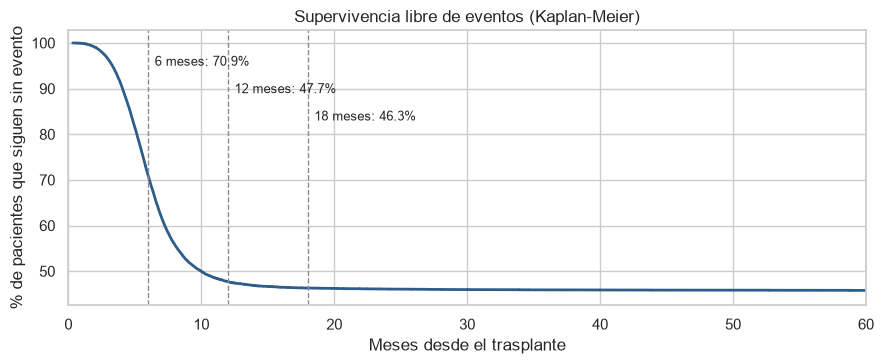

In [9]:
# Curva de Kaplan Meier que tiene en cuenta la censura
def kaplan_meier(tiempo, evento):
    t, e = np.asarray(tiempo), np.asarray(evento)
    tiempos = np.unique(t[e == 1])
    en_riesgo = np.array([(t >= ti).sum() for ti in tiempos])
    eventos = np.array([((t == ti) & (e == 1)).sum() for ti in tiempos])
    return tiempos, np.cumprod(1 - eventos / en_riesgo)

tiempos, superv = kaplan_meier(df_clean["meses_hasta_evento"], df_clean["evento"])
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.step(tiempos, superv * 100, where="post", color=AZUL, linewidth=2)
for i, h in enumerate((6, 12, 18)):
    ax.axvline(h, color=GRIS, linestyle="--", linewidth=1)
    ax.text(h + 0.5, 95 - 6 * i, f"{h} meses: {superv[tiempos <= h][-1]:.1%}", fontsize=9)
ax.set_xlim(0, 60)
ax.set_xlabel("Meses desde el trasplante")
ax.set_ylabel("% de pacientes que siguen sin evento")
ax.set_title("Supervivencia libre de eventos (Kaplan-Meier)")
plt.tight_layout()
guardar_figura("kaplan_meier", RUN_DATOS)
con_evento = df_clean.loc[df_clean["evento"] == 1, "meses_hasta_evento"]
print(f"Pacientes con evento: {len(con_evento):,} | mediana de meses hasta el evento: {con_evento.median():.1f} | eventos dentro de 12 meses: {(con_evento <= 12).mean():.1%}")

Análisis: la curva cae rápido durante el primer año. A los 6 meses sigue sin evento el 70.9% de los pacientes, a los 12 meses el 47.7% y a los 18 meses el 46.3%, es decir, entre el mes 12 y el 18 casi no pasa nada. De los 15,532 pacientes que tuvieron el evento, el 96.8% lo tuvo dentro de los primeros 12 meses, con una mediana de 5.8 meses. Esto respalda usar 12 meses como horizonte.

In [10]:
# Evento en 12 meses sin los pacientes censurados antes de ese plazo
HORIZONTE = 12
def construir_objetivo(df, h):
    utiles = ~((df["evento"] == 0) & (df["meses_hasta_evento"] < h))
    df_salida = df[utiles].copy()
    df_salida["evento_12m"] = ((df_salida["evento"] == 1) & (df_salida["meses_hasta_evento"] <= h)).astype(int)
    return df_salida

df_model = construir_objetivo(df_clean, HORIZONTE)
COLUMNAS_PROTEGIDAS = ["grupo_racial", "etnicidad"]
COLUMNAS_NO_PREDICTORAS = ["id", "evento", "meses_hasta_evento", "evento_12m", "anio_trasplante"] + COLUMNAS_PROTEGIDAS
COLUMNAS_ENTRADA = [c for c in df_model.columns if c not in COLUMNAS_NO_PREDICTORAS]
print(f"df_model: {len(df_model):,} pacientes ({len(df_clean) - len(df_model)} excluidos por censura antes de 12 meses)")
print(f"Con evento en 12 meses: {df_model['evento_12m'].mean():.1%} | sin evento: {1 - df_model['evento_12m'].mean():.1%}")
print("Predictores:", len(COLUMNAS_ENTRADA))

df_model: 28,562 pacientes (238 excluidos por censura antes de 12 meses)
Con evento en 12 meses: 52.6% | sin evento: 47.4%
Predictores: 56


Análisis: solo 238 pacientes (0.8%) se excluyen por haber salido del seguimiento antes del año sin evento. df_model queda con 28,562 pacientes y 56 predictores (las 57 variables del registro menos las 2 eliminadas por nulos, más las 5 nuevas, menos el índice de riesgo original, el año del trasplante, el grupo racial y la etnicidad). El 52.6% de los pacientes tiene un evento en 12 meses y el 47.4% no: las clases están casi balanceadas.

Partición de df_model en df_train (70%), df_val (15%) y df_test (15%), antes de cualquier paso que aprenda de los datos. El test.csv de la competencia no se usa porque solo trae 3 pacientes y no incluye el resultado; Kaggle guarda las respuestas en privado. El grupo racial, la etnicidad y el año del trasplante no se usan como predictores. El año no describe al paciente: la sección 5.5 muestra que su relación con el riesgo coincide con los años de registros incompletos, y un modelo que se usará con pacientes nuevos no debe apoyarse en la fecha. Se conserva solo para los análisis por periodo.

Por qué 70/15/15 con 28,562 pacientes:

- df_test (15%, unos 4,285 pacientes) es lo bastante grande para medir el AUC final con un margen de error pequeño; el intervalo de confianza de la sección 10 lo cuantifica.
- df_val (15%) hace falta porque varias decisiones se toman fuera de la validación cruzada: la forma de imputar, el uso de PCA y de SMOTE, la comprobación del modelo elegido y el umbral de alerta. Así df_test no se usa para ninguna decisión.
- df_train (70%, unos 20,000 pacientes) queda para la comparación de modelos y la búsqueda de hiperparámetros con validación cruzada.

La partición es estratificada por la variable objetivo (y por grupo racial), para que los tres conjuntos tengan la misma proporción de pacientes con evento y la misma mezcla de pacientes.

In [11]:
estrato = df_model["evento_12m"].astype(str) + "_" + df_model["grupo_racial"]
df_temp, df_test = train_test_split(df_model, test_size=0.15, stratify=estrato, random_state=SEMILLA)
df_train, df_val = train_test_split(df_temp, test_size=0.15 / 0.85, stratify=estrato.loc[df_temp.index], random_state=SEMILLA)
X_train, X_val, X_test = df_train[COLUMNAS_ENTRADA], df_val[COLUMNAS_ENTRADA], df_test[COLUMNAS_ENTRADA]
y_train, y_val, y_test = df_train["evento_12m"], df_val["evento_12m"], df_test["evento_12m"]

# Comprobación de fuga con la regla de nulos calculada solo en df_train
eliminadas_train = sorted(NOMBRES[c] for c in df_raw.columns if df_raw.loc[df_train.index, c].isna().mean() > 0.5)
print("Variables con más de 50% de nulos calculadas solo con df_train:", eliminadas_train,
      "| iguales a las eliminadas:", eliminadas_train == sorted(COLUMNAS_ELIMINADAS))

with mlflow.start_run(run_id=RUN_DATOS):
    mlflow.log_params({"horizonte_meses": HORIZONTE, "pacientes_modelo": len(df_model), "predictores": len(COLUMNAS_ENTRADA),
                       "pacientes_train": len(df_train), "pacientes_val": len(df_val), "pacientes_test": len(df_test),
                       "columnas_eliminadas": ", ".join(COLUMNAS_ELIMINADAS)})
    for nombre_conjunto, df_conjunto in [("df_train", df_train), ("df_val", df_val), ("df_test", df_test)]:
        mlflow.log_input(mlflow.data.from_pandas(df_conjunto, name=nombre_conjunto, targets="evento_12m"), context=nombre_conjunto)

pd.DataFrame({"pacientes": [len(df_train), len(df_val), len(df_test)],
              "% con evento en 12 meses": [round(y.mean() * 100, 2) for y in (y_train, y_val, y_test)],
              "% sin evento": [round((1 - y.mean()) * 100, 2) for y in (y_train, y_val, y_test)]},
             index=["df_train", "df_val", "df_test"])

Variables con más de 50% de nulos calculadas solo con df_train: ['enfermedad_minima_residual', 'epitopos_t_compatibilidad'] | iguales a las eliminadas: True


,pacientes,% con evento en 12 meses,% sin evento
df_train,19992,52.62,47.38
df_val,4285,52.65,47.35
df_test,4285,52.65,47.35


Análisis: los tres conjuntos tienen la misma proporción de eventos (52.6% con evento y 47.4% sin evento) gracias a la estratificación. La comprobación de fuga da el resultado esperado: calculada solo con df_train, la regla de más de 50% de nulos elimina las mismas dos variables (enfermedad_minima_residual y epitopos_t_compatibilidad), así que haberla calculado con todos los pacientes no le pasa información de df_val ni de df_test al modelo. df_test (4,285 pacientes) no se vuelve a tocar hasta la sección 10.

# 5. Análisis exploratorio

**Nota Aclaratoria:** Todo el análisis usa solo df_train.

## 5.1 Edad del paciente y del donante

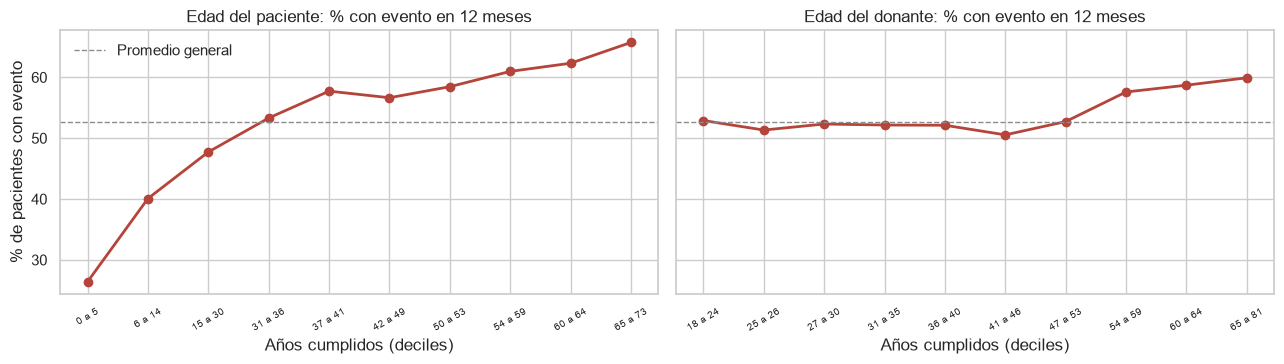

In [12]:
# Porcentaje con evento por deciles de edad del paciente y del donante
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col, titulo in zip(axes, ["edad_paciente", "edad_donante"], ["Edad del paciente", "Edad del donante"]):
    decil = pd.qcut(df_train[col].astype(float), 10, duplicates="drop")
    tasa = y_train.groupby(decil.values, observed=True).mean()
    ax.plot(range(len(tasa)), tasa.values * 100, marker="o", color=ROJO, linewidth=2)
    ax.set_xticks(range(len(tasa)))
    ax.set_xticklabels([f"{np.floor(iv.left) + 1:.0f} a {iv.right:.0f}" for iv in tasa.index], fontsize=7, rotation=30)
    ax.axhline(y_train.mean() * 100, color=GRIS, linestyle="--", linewidth=1, label="Promedio general")
    ax.set_title(f"{titulo}: % con evento en 12 meses")
    ax.set_xlabel("Años cumplidos (deciles)")
axes[0].set_ylabel("% de pacientes con evento")
axes[0].legend(frameon=False)
plt.tight_layout()
guardar_figura("edad", RUN_DATOS)

Análisis: la edad del paciente es uno de los factores más claros. En los niños de 0 a 5 años solo el 26% tiene un evento en el primer año, en el rango de 31 a 36 años ya está en el promedio (53%) y en los mayores de 65 llega a 66%. La edad del donante pesa mucho menos: la curva se mantiene alrededor del promedio hasta los 53 años y sube a entre 57% y 60% con donantes de 54 años o más. Por eso se creó la diferencia de edad entre donante y paciente; se usa sin signo porque lo que mide es la distancia entre las dos edades, y la dirección ya la dan la edad de cada uno.

## 5.2 Variables clínicas principales

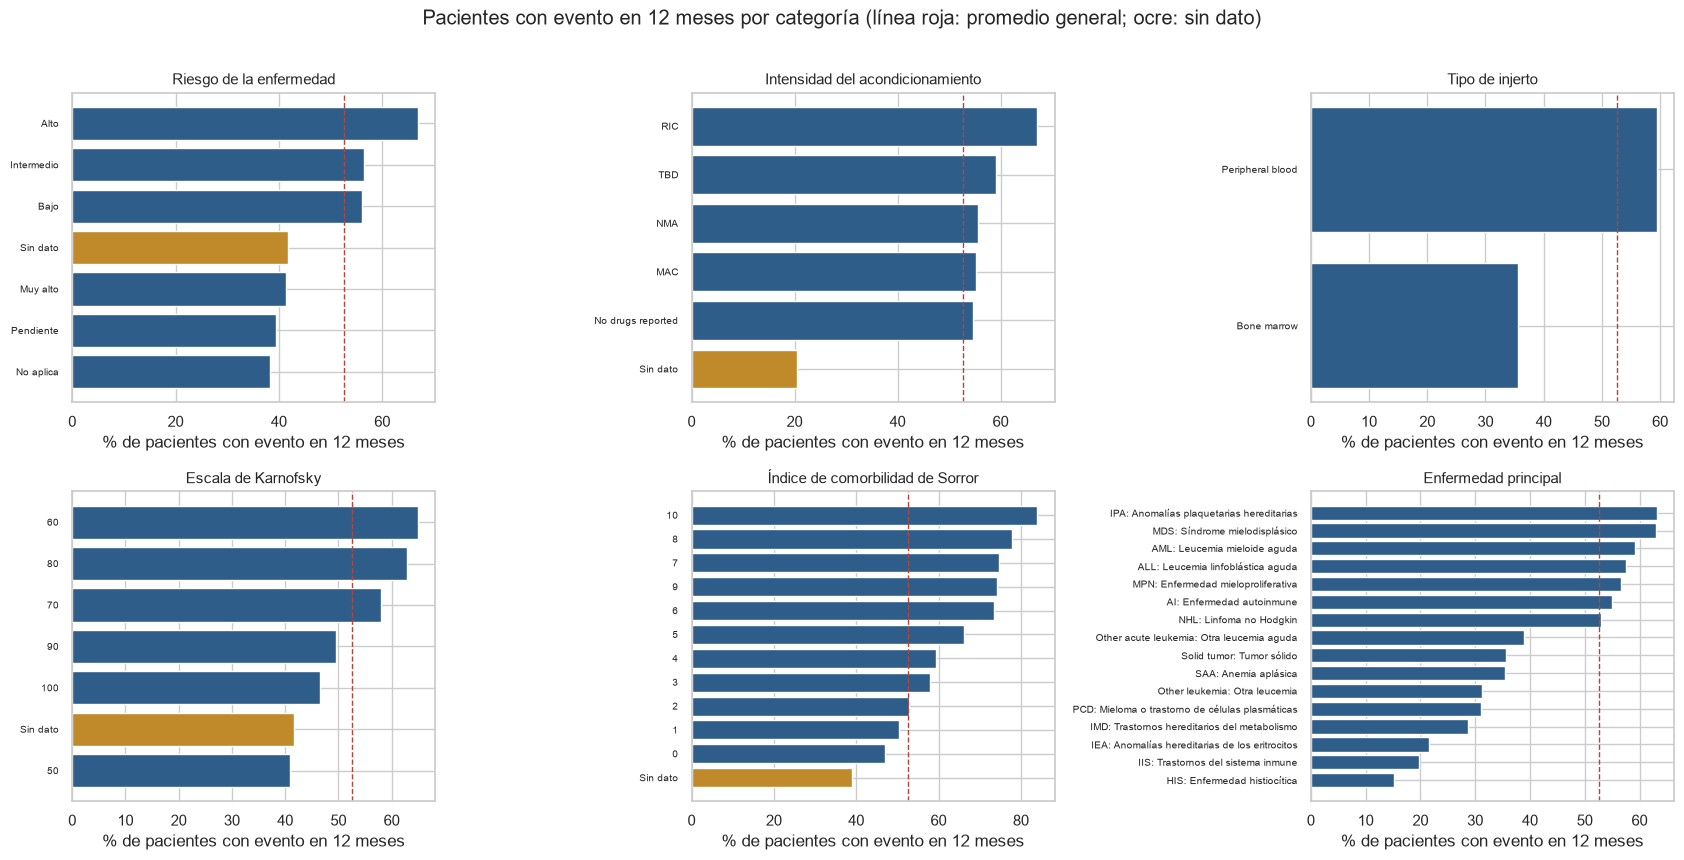

In [13]:
# Porcentaje con evento por categoría en seis variables clínicas
paneles = {"grupo_riesgo_enfermedad": "Riesgo de la enfermedad", "intensidad_acondicionamiento": "Intensidad del acondicionamiento",
           "tipo_injerto": "Tipo de injerto", "escala_karnofsky": "Escala de Karnofsky",
           "indice_comorbilidad_sorror": "Índice de comorbilidad de Sorror", "enfermedad_principal": "Enfermedad principal"}
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for ax, (col, titulo) in zip(axes.ravel(), paneles.items()):
    serie = df_train[col].astype(object).where(df_train[col].notna(), "Sin dato").astype(str)
    if col == "enfermedad_principal":
        serie = serie.map(etiqueta_enfermedad)
    resumen = y_train.groupby(serie.values).agg(["mean", "size"])
    resumen = resumen[resumen["size"] >= 50].sort_values("mean")
    ax.barh(resumen.index, resumen["mean"] * 100, color=[OCRE if i == "Sin dato" else AZUL for i in resumen.index])
    ax.axvline(y_train.mean() * 100, color=ROJO, linestyle="--", linewidth=1)
    ax.set_title(titulo, fontsize=11)
    ax.set_xlabel("% de pacientes con evento en 12 meses")
    ax.tick_params(axis="y", labelsize=7)
plt.suptitle("Pacientes con evento en 12 meses por categoría (línea roja: promedio general; ocre: sin dato)", y=1.01)
plt.tight_layout()
guardar_figura("variables_clinicas", RUN_DATOS)

Análisis: la mayoría de las variables separan bien el riesgo y en la dirección esperada. Un índice de riesgo alto lleva al 66% con evento, el acondicionamiento de intensidad reducida (RIC) al 67% frente a 55% del intenso (MAC), la sangre periférica al 60% frente a 35% de la médula ósea, y el índice de Sorror sube de forma casi continua de 47% con 0 puntos a 84% con 10. Hay dos excepciones: la categoría Muy alto del índice de riesgo queda por debajo del promedio (41%), y en la escala de Karnofsky el valor 50 tiene menos eventos que 60 u 80, así que esa escala no sigue un orden perfecto.

Lo más llamativo son las barras ocre: los pacientes sin dato quedan por debajo del promedio en las cuatro variables donde aparecen, y en la intensidad del acondicionamiento y el índice de Sorror tienen menos riesgo que cualquier categoría real. Sin dato de intensidad, solo el 20% tiene evento. Eso no puede ser un efecto clínico del dato vacío, así que se investiga en las secciones 5.4 y 5.5.

Escalas numéricas: ¿número o grupos? El índice de Sorror, la escala de Karnofsky y el número de comorbilidades son escalas de puntos enteros. Se pueden usar como número o agrupar en rangos. Los grupos que se revisan son los que se usan en la práctica clínica:

- Índice de Sorror (HCT-CI): 0 puntos (riesgo bajo), 1 a 2 (intermedio) y 3 o más (alto), la clasificación original del índice.
- Escala de Karnofsky: 90 a 100 (actividad normal), 70 a 80 (se vale por sí mismo con limitaciones) y 60 o menos (necesita ayuda).
- Número de comorbilidades: 0, 1, 2 y 3 o más.

Agrupar conviene si los grupos separan mejor el riesgo que los valores individuales, por ejemplo cuando los valores no siguen un orden claro. La gráfica muestra el porcentaje con evento de cada valor (barras) y de cada grupo (líneas rojas). La decisión final se toma en la sección 6, midiendo si el modelo separa mejor a los pacientes con la variable agrupada.

pacientes  % con evento
variable                   grupo                              
indice_comorbilidad_sorror 0                7483          46.9
                           1 a 2            7441          51.7
                           3 o más          4749          64.0
escala_karnofsky           60 o menos        940          63.3
                           70 a 80          6074          59.2
                           90 a 100        12359          49.1
n_comorbilidades           0                8996          46.7
                           1                5985          53.4
                           2                3194          60.4
                           3 o más          1817          65.9

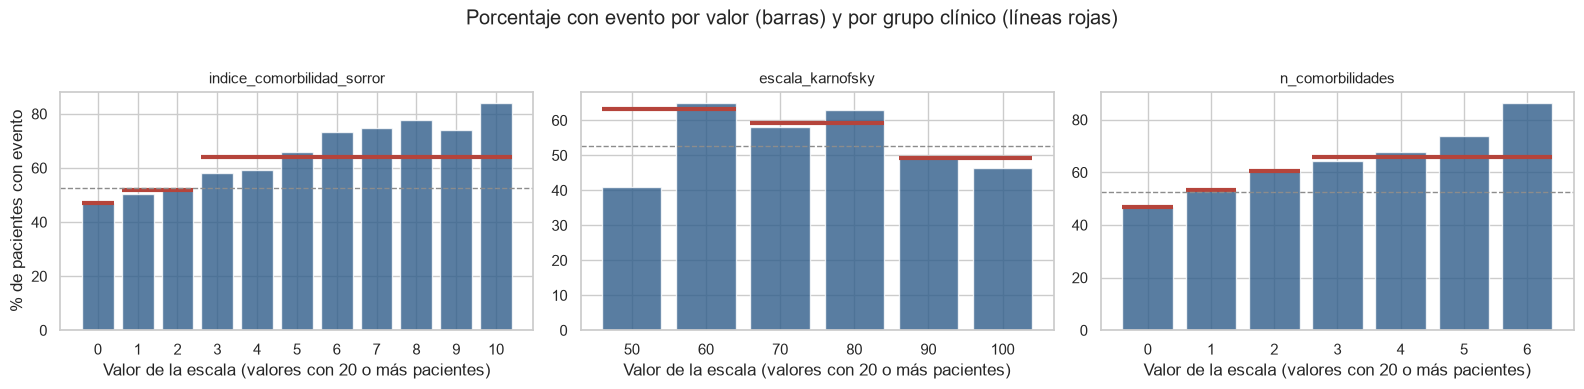

In [14]:
# Grupos clínicos de cada escala
GRUPOS_ESCALAS = {
    "indice_comorbilidad_sorror": ([-np.inf, 0, 2, np.inf], ["0", "1 a 2", "3 o más"]),
    "escala_karnofsky": ([-np.inf, 60, 80, np.inf], ["60 o menos", "70 a 80", "90 a 100"]),
    "n_comorbilidades": ([-np.inf, 0, 1, 2, np.inf], ["0", "1", "2", "3 o más"]),
}

# Porcentaje con evento por valor y por grupo
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
filas = []
for ax, (col, (cortes, etiquetas)) in zip(axes, GRUPOS_ESCALAS.items()):
    valor = df_train[col].astype(float)
    grupo = pd.cut(valor, cortes, labels=etiquetas)
    por_valor = y_train.groupby(valor).agg(["mean", "size"])
    por_valor = por_valor[por_valor["size"] >= 20]
    ax.bar(range(len(por_valor)), por_valor["mean"] * 100, color=AZUL, alpha=0.8)
    ax.set_xticks(range(len(por_valor)))
    ax.set_xticklabels(por_valor.index.astype(int))
    grupo_de_valor = pd.cut(pd.Series(por_valor.index), cortes, labels=etiquetas)
    for etiqueta in etiquetas:
        posiciones = np.where(grupo_de_valor == etiqueta)[0]
        tasa_grupo = y_train[grupo == etiqueta].mean()
        ax.hlines(tasa_grupo * 100, posiciones.min() - 0.4, posiciones.max() + 0.4, color=ROJO, linewidth=3)
        filas.append({"variable": col, "grupo": etiqueta, "pacientes": int((grupo == etiqueta).sum()), "% con evento": tasa_grupo * 100})
    ax.axhline(y_train.mean() * 100, color=GRIS, linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Valor de la escala (valores con 20 o más pacientes)")
axes[0].set_ylabel("% de pacientes con evento")
plt.suptitle("Porcentaje con evento por valor (barras) y por grupo clínico (líneas rojas)", y=1.02)
plt.tight_layout()
guardar_figura("escalas", RUN_DATOS)
pd.DataFrame(filas).set_index(["variable", "grupo"]).round(1)

Análisis: en el índice de Sorror y en el número de comorbilidades el porcentaje con evento sube casi valor a valor (Sorror de 47% con 0 puntos a 84% con 10; comorbilidades de 47% sin ninguna a 74% con 5), así que el número ya ordena el riesgo. Agruparlos junta valores muy distintos: el grupo de Sorror de 3 o más puntos promedia 64%, pero dentro de él hay pacientes con 58% (3 puntos) y con 84% (10 puntos). La escala de Karnofsky es diferente: sus valores no siguen un orden (60 tiene 65% con evento, 70 tiene 58%, 80 tiene 63% y 50 solo 41%), mientras que los tres grupos clínicos sí quedan ordenados: 63% con 60 o menos, 59% con 70 a 80 y 49% con 90 a 100. A simple vista, agrupar ayudaría en Karnofsky y no en las otras dos; la sección 6 lo comprueba con el modelo.

## 5.3 Compatibilidad HLA

HLA son marcadores genéticos que las defensas del cuerpo usan para reconocer qué es propio y qué es ajeno. Entre más se parezcan los del donante y los del paciente, menor es el riesgo de rechazo. El dataset trae 17 variables que cuentan cuántas coincidencias hay entre paciente y donante, medidas con dos niveles de detalle (baja y alta resolución). Cada una tiene su propio máximo: 2 cuando mide un solo gen y 6, 8 o 10 cuando suma varios.

Después de la limpieza son números enteros con -1 cuando la prueba no se hizo. Ese -1 no es un nivel de compatibilidad sino la falta del dato, así que también se revisa una versión agrupada por el porcentaje de coincidencias sobre el máximo de cada variable, con el -1 como una categoría aparte:

- Sin dato: -1.
- Baja: menos del 40% de coincidencias (de 0 a 3 sobre 10, de 0 a 3 sobre 8, de 0 a 2 sobre 6, 0 sobre 2).
- Media: del 40% al 79% (de 4 a 7 sobre 10, de 4 a 6 sobre 8, de 3 a 4 sobre 6, 1 sobre 2).
- Alta: 80% o más (de 8 a 10 sobre 10, de 7 a 8 sobre 8, de 5 a 6 sobre 6, 2 sobre 2).

Correlación media entre pares de variables HLA: 0.763 | mínima: 0.494
Pacientes con hla_alta_res_8 en -1: 20.1% | % con evento: 51.7% frente a 52.9% con el dato


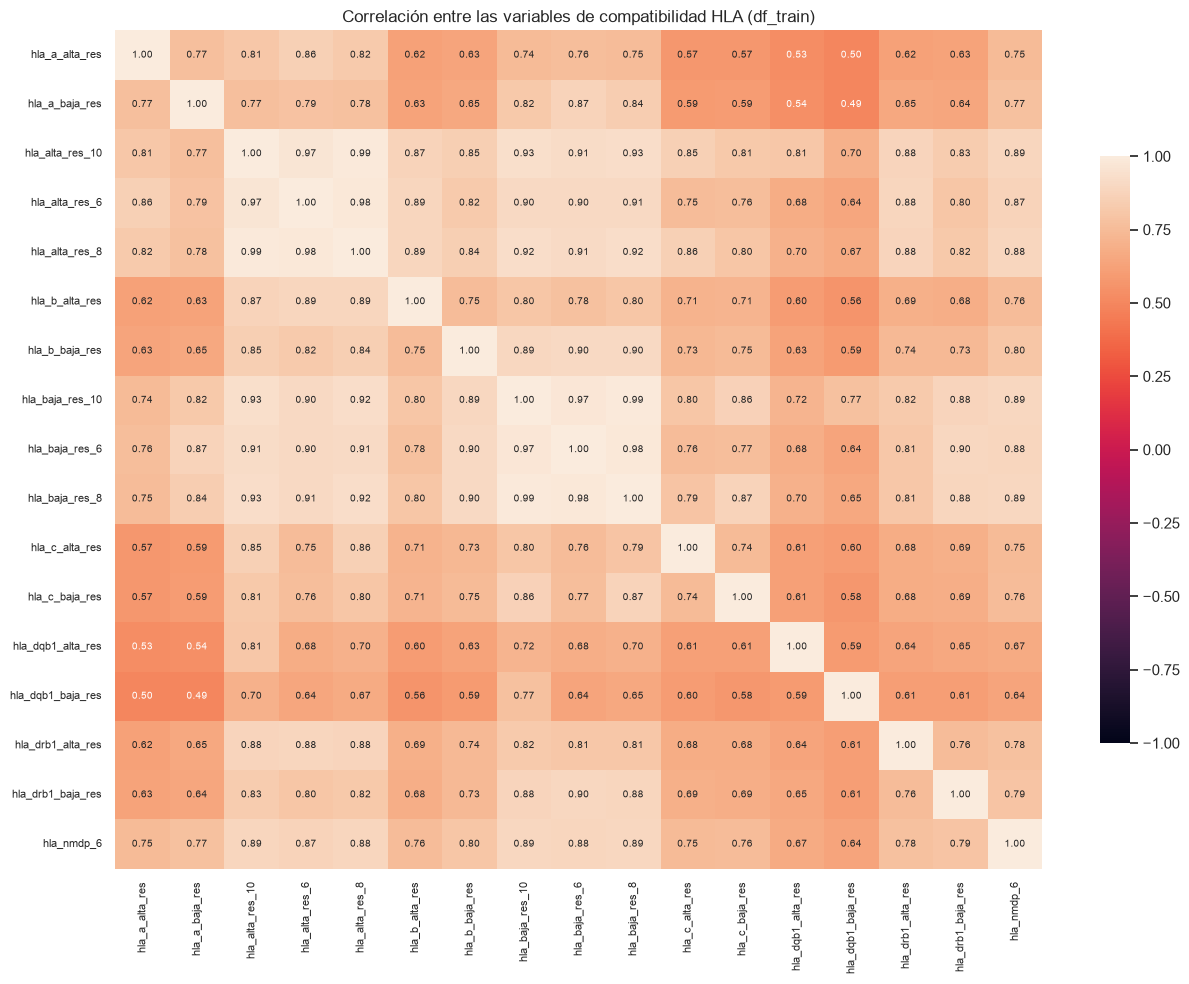

In [15]:
# Correlación entre las variables HLA con sus valores reales sin el -1
hla_valores = df_train[COLUMNAS_HLA].replace(-1, np.nan)
corr_hla = hla_valores.corr()
fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr_hla, annot=True, fmt=".2f", annot_kws={"size": 7}, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.tick_params(labelsize=8)
ax.set_title("Correlación entre las variables de compatibilidad HLA (df_train)")
plt.tight_layout()
guardar_figura("hla_correlacion", RUN_DATOS)
triu = corr_hla.where(np.triu(np.ones(corr_hla.shape, dtype=bool), k=1)).stack()
print(f"Correlación media entre pares de variables HLA: {triu.mean():.3f} | mínima: {triu.min():.3f}")
sin_hla = df_train["hla_alta_res_8"] == -1
print(f"Pacientes con hla_alta_res_8 en -1: {sin_hla.mean():.1%} | % con evento: {y_train[sin_hla].mean():.1%} "
      f"frente a {y_train[~sin_hla].mean():.1%} con el dato")

Análisis: las variables HLA son casi copias unas de otras, con una correlación media de 0.763 entre pares y ninguna por debajo de 0.49. Las que resumen varios genes (por ejemplo hla_alta_res_8 y hla_alta_res_10) llegan a 0.99. Tener 17 versiones de la misma información infla el número de columnas sin aportar mucho, lo que justifica buscar una forma más compacta de representar el bloque. El 20.1% de los pacientes tiene -1 en hla_alta_res_8 (la prueba no se hizo) y su porcentaje con evento (51.7%) es casi igual al de quienes sí tienen el dato (52.9%).

In [16]:
# Niveles de compatibilidad HLA según el porcentaje de coincidencias
MAXIMO_HLA = {c: 2 if c.endswith("_res") else int(c.rsplit("_", 1)[1]) for c in COLUMNAS_HLA}
NIVELES_HLA = ["Sin dato", "Baja", "Media", "Alta"]


def nivel_hla(valores, maximo):
    fraccion = valores / maximo
    return pd.Series(np.select([valores < 0, fraccion >= 0.8, fraccion >= 0.4], ["Sin dato", "Alta", "Media"], "Baja"),
                     index=valores.index)


# Pacientes y porcentaje con evento en cada nivel
niveles = {c: nivel_hla(df_train[c], MAXIMO_HLA[c]) for c in COLUMNAS_HLA}
tabla_hla = pd.DataFrame({c: y_train.groupby(n).mean().mul(100).reindex(NIVELES_HLA) for c, n in niveles.items()}).T
tabla_hla.columns = [f"% con evento: {n}" for n in NIVELES_HLA]
tabla_hla.insert(0, "máximo", pd.Series(MAXIMO_HLA))
for n in ["Baja", "Media", "Alta"]:
    tabla_hla[f"pacientes: {n}"] = [int((niveles[c] == n).sum()) for c in tabla_hla.index]
tabla_hla.round(1)

,máximo,% con evento: Sin dato,% con evento: Baja,% con evento: Media,% con evento: Alta,pacientes: Baja,pacientes: Media,pacientes: Alta
hla_a_alta_res,2,52.7,39.5,52.4,52.7,38,4956,12038
hla_a_baja_res,2,50.3,39.4,52.6,53.0,33,5278,13023
hla_alta_res_10,10,53.0,NaN,50.1,53.4,0,3991,11047
hla_alta_res_6,6,51.8,33.3,51.0,53.6,27,4666,11657
hla_alta_res_8,8,51.7,38.9,50.8,53.8,18,4868,11096
hla_b_alta_res,2,53.2,42.0,51.8,52.9,50,5079,12018
hla_b_baja_res,2,50.6,39.5,50.7,53.7,38,5014,13166
hla_baja_res_10,10,52.6,NaN,50.5,53.3,0,4205,12292
hla_baja_res_6,6,50.1,50.0,50.7,53.8,14,4859,12876
hla_baja_res_8,8,51.2,43.8,51.1,53.6,16,5113,12366


Análisis: en casi todas las variables, el nivel Alta (80% o más de coincidencias) tiene el porcentaje con evento más alto, entre 52.6% y 54.8%, y el nivel Media queda un poco por debajo, entre 48.4% y 52.6%. Que la compatibilidad completa tenga algo más de eventos va contra lo esperado clínicamente; en estos datos puede deberse a quién recibe cada tipo de donante (por ejemplo, los donantes con compatibilidad parcial se usan más en niños, que tienen menos riesgo), así que no se lee como causa. El nivel Sin dato queda cerca del promedio (50% a 55%) y el nivel Baja tiene muy pocos pacientes (menos de 60 por variable y ninguno en tres de ellas), así que en el modelo esos pocos pacientes se juntan como categoría poco frecuente. Las diferencias son pequeñas por sí solas; la sección 6 mide si los niveles le sirven al modelo más que el número con -1.

## 5.4 Quién tiene datos vacíos

Después de la limpieza, las variables genéticas ya no tienen nulos. Esta sección revisa las demás: cuántas variables vacías tiene cada paciente y en qué segmentos se concentran.

,pacientes,variables_vacias_promedio,pct_sin_intensidad
grupo_edad,,,
Adulto,15329,1.34,7.4
Pediátrico,4663,1.69,47.9


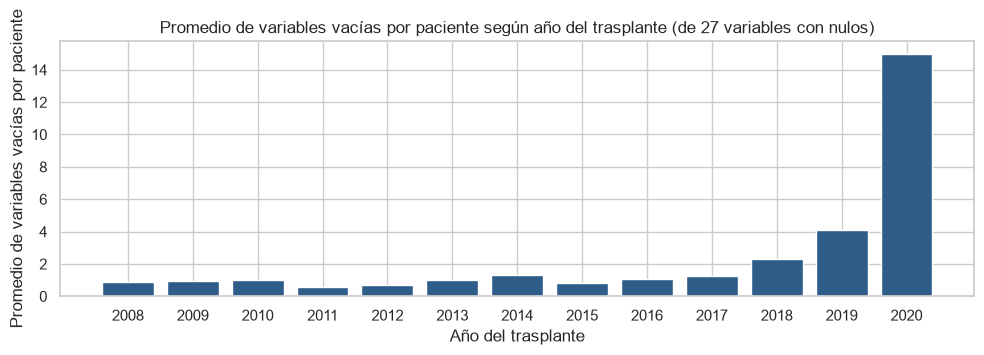

In [17]:
# Variables vacías por paciente según año y grupo de edad
COLUMNAS_CON_NULOS = [c for c in COLUMNAS_ENTRADA if df_train[c].isna().any()]
df_eda = df_train.copy()
df_eda["n_vacias"] = df_eda[COLUMNAS_CON_NULOS].isna().sum(axis=1)
df_eda["sin_intensidad"] = df_eda["intensidad_acondicionamiento"].isna()
df_eda["grupo_edad"] = np.where(df_eda["es_pediatrico"] == 1, "Pediátrico", "Adulto")
por_anio = df_eda.groupby("anio_trasplante")["n_vacias"].mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(por_anio.index.astype(str), por_anio.values, color=AZUL)
ax.set_xlabel("Año del trasplante")
ax.set_ylabel("Promedio de variables vacías por paciente")
ax.set_title(f"Promedio de variables vacías por paciente según año del trasplante (de {len(COLUMNAS_CON_NULOS)} variables con nulos)")
plt.tight_layout()
guardar_figura("nulos_anio", RUN_DATOS)
df_eda.groupby("grupo_edad").agg(pacientes=("id", "size"), variables_vacias_promedio=("n_vacias", "mean"),
                                 pct_sin_intensidad=("sin_intensidad", "mean")).assign(pct_sin_intensidad=lambda d: (d["pct_sin_intensidad"] * 100).round(1)).round(2)

Análisis: entre 2008 y 2017 cada paciente tiene en promedio alrededor de una variable vacía, de las 27 que todavía pueden tener nulos. A partir de 2018 el número sube: 2.3 en 2018 y 4.1 en 2019. La barra de 2020 llega a 15, pero ese año solo tiene 2 pacientes en df_train (sección 5.5), así que no se puede leer como tendencia. Los vacíos se concentran en los registros más recientes, lo que apunta a formularios que todavía no se habían completado cuando se armó el registro. La tabla muestra además que a los pacientes pediátricos les falta la intensidad del acondicionamiento en el 47.9% de los casos, frente a 7.4% en los adultos.

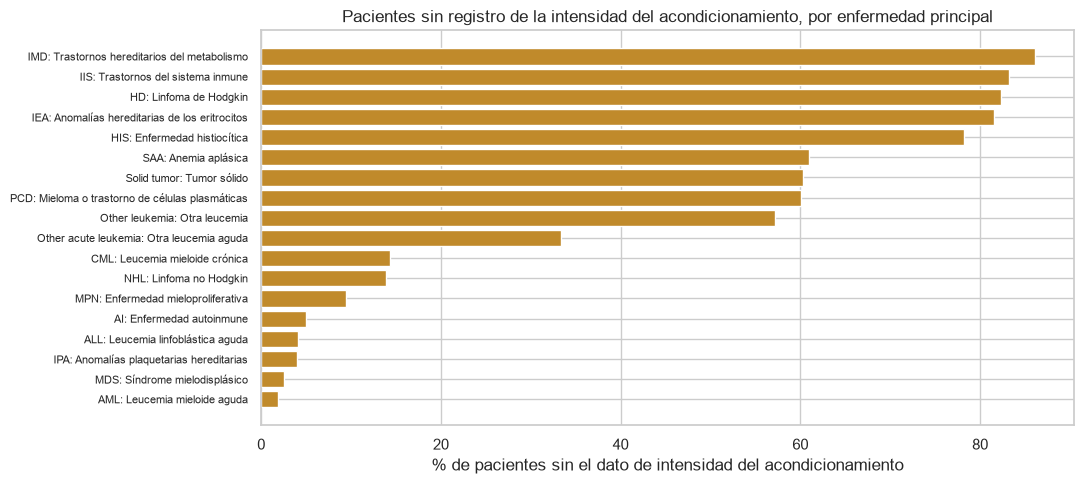

In [18]:
# Porcentaje sin dato de intensidad del acondicionamiento por enfermedad
por_enf = df_eda.groupby("enfermedad_principal")["sin_intensidad"].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh([etiqueta_enfermedad(c) for c in por_enf.index], por_enf.values, color=OCRE)
ax.set_xlabel("% de pacientes sin el dato de intensidad del acondicionamiento")
ax.set_title("Pacientes sin registro de la intensidad del acondicionamiento, por enfermedad principal")
ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
guardar_figura("nulos_enfermedad", RUN_DATOS)

Análisis: la falta del dato de intensidad no es aleatoria, depende de la enfermedad. Les falta al 78% o más de los pacientes con enfermedades hereditarias o no malignas (trastornos del metabolismo, del sistema inmune, de los eritrocitos y la enfermedad histiocítica) y también al 82% de los pocos casos de linfoma de Hodgkin. En cambio, en las leucemias agudas y el síndrome mielodisplásico casi siempre está (menos de 5% sin dato). Estas son, además, las enfermedades de menor riesgo en la sección 5.2.

## 5.5 Datos vacíos y seguimiento en el tiempo

In [19]:
# Seguimiento de los pacientes sin evento según variables vacías
# y porcentaje con evento con y sin dato de intensidad
df_censurados = df_eda[df_eda["evento"] == 0]
seguimiento = df_censurados.groupby(pd.cut(df_censurados["n_vacias"], [-1, 0, 2, 5, 60], labels=["0", "1 a 2", "3 a 5", "6 o más"]),
                                    observed=True)["meses_hasta_evento"].agg(["size", "median"]).rename(
    columns={"size": "pacientes sin evento", "median": "mediana de meses de seguimiento"})
display(seguimiento.round(1))
tabla_intensidad = df_eda.groupby(["grupo_edad", "sin_intensidad"])["evento_12m"].agg(["size", "mean"])
tabla_intensidad.columns = ["pacientes", "% con evento en 12 meses"]
tabla_intensidad["% con evento en 12 meses"] = (tabla_intensidad["% con evento en 12 meses"] * 100).round(1)
tabla_intensidad

,pacientes sin evento,mediana de meses de seguimiento
n_vacias,,
0,4337,39.5
1 a 2,3189,37.8
3 a 5,931,35.9
6 o más,658,27.3


pacientes  % con evento en 12 meses
grupo_edad sin_intensidad                                     
Adulto     False               14198                      61.0
           True                 1131                      23.6
Pediátrico False                2428                      48.4
           True                 2235                      18.9

Análisis: los vacíos no vienen de pacientes que dejan de asistir. Los pacientes sin evento tienen un seguimiento de 36 a 40 meses en mediana, tengan 0 o 5 variables vacías. El grupo con 6 o más vacías tiene menos seguimiento (27.3 meses), lo que coincide con la gráfica anterior: los trasplantes de 2019 y 2020 son los que más vacíos tienen y también los que llevan menos tiempo de observación.

El efecto sobre el riesgo es grande: en los adultos, el 61.0% de quienes tienen el dato de intensidad tuvo un evento, frente a 23.6% de quienes no lo tienen. En los niños, 48.4% frente a 18.9%. El vacío funciona como una señal de que el paciente pertenece a un grupo de bajo riesgo, no como un dato clínico.

Riesgo por año del trasplante. La sección 5.4 mostró que los registros más recientes tienen más datos vacíos. Aquí se revisa si el porcentaje de pacientes con evento también cambia con el año.

,pacientes,% con evento en 12 meses,variables_vacias_promedio
anio_trasplante,,,
2008,1761,59.3,0.9
2009,359,68.0,0.9
2010,271,63.8,1.0
2011,426,62.2,0.6
2012,1105,55.6,0.7
2013,1303,50.1,1.0
2014,785,46.1,1.3
2015,1566,57.8,0.8
2016,3534,51.4,1.1


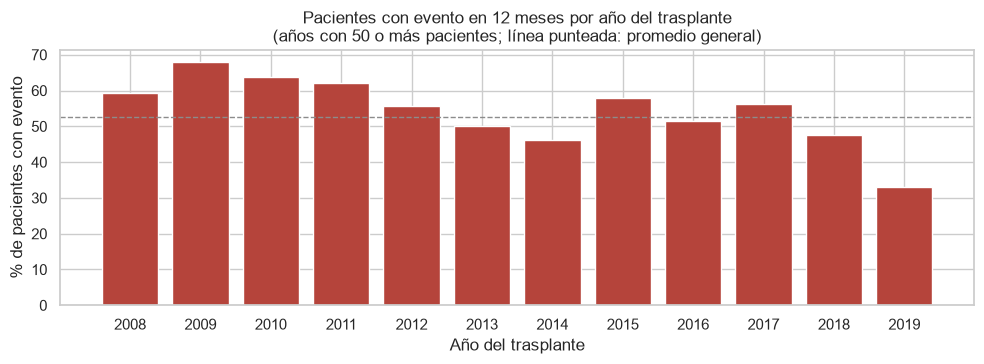

In [20]:
# Porcentaje con evento y variables vacías por año del trasplante
riesgo_anio = df_eda.groupby("anio_trasplante").agg(pacientes=("id", "size"), pct_evento=("evento_12m", "mean"),
                                                    variables_vacias_promedio=("n_vacias", "mean"))
riesgo_anio["pct_evento"] = riesgo_anio["pct_evento"] * 100
grafica_anio = riesgo_anio[riesgo_anio["pacientes"] >= 50]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(grafica_anio.index.astype(str), grafica_anio["pct_evento"], color=ROJO)
ax.axhline(y_train.mean() * 100, color=GRIS, linestyle="--", linewidth=1)
ax.set_xlabel("Año del trasplante")
ax.set_ylabel("% de pacientes con evento")
ax.set_title("Pacientes con evento en 12 meses por año del trasplante\n(años con 50 o más pacientes; línea punteada: promedio general)")
plt.tight_layout()
guardar_figura("riesgo_anio", RUN_DATOS)
riesgo_anio.rename(columns={"pct_evento": "% con evento en 12 meses"}).round(1)

Análisis: hasta 2017 el porcentaje con evento sube y baja entre 46% y 68% sin una tendencia clara (59.3% en 2008, 46.1% en 2014 y 56.1% en 2017). En 2018 baja a 47.5% y en 2019 a 33.0%, los mismos años en que más crecen los datos vacíos (2.3 y 4.1 variables por paciente). 2020 queda fuera de la gráfica porque solo tiene 2 pacientes. Con estos datos no se puede saber si la caída de los últimos años se debe a mejores tratamientos o a registros todavía incompletos. Por eso el año del trasplante no se usa como predictor: el modelo aprendería que un trasplante reciente tiene menos riesgo, cuando buena parte de esa diferencia puede venir de formularios incompletos, y con pacientes nuevos esa señal no tendría sentido.

## 5.6 Conclusiones del análisis exploratorio

- El riesgo depende sobre todo de la edad, la comorbilidad (Sorror), el estado funcional (Karnofsky), el tipo de injerto, la intensidad del acondicionamiento y la enfermedad.
- Sorror y el número de comorbilidades ordenan el riesgo valor a valor; Karnofsky no sigue un orden, pero sus grupos clínicos sí. La sección 6 decide con el modelo si conviene agruparlos.
- Las 17 variables HLA son muy redundantes. Sus niveles de compatibilidad separan poco el riesgo por sí solos, y el -1 (prueba no hecha) es una falta de dato y no un nivel de compatibilidad.
- Los datos vacíos tienen un patrón claro: se concentran en pacientes pediátricos, en varias enfermedades hereditarias o no malignas (no en todas: a las anomalías plaquetarias hereditarias casi nunca les falta la intensidad del acondicionamiento) y en los trasplantes de 2018 y 2019. No se deben a pacientes que abandonan el seguimiento.
- Un vacío se asocia a mucho menos riesgo. Si el modelo aprende eso, le bajaría el riesgo a cualquier paciente con el formulario incompleto. La sección 6 compara dos formas de imputar para evitarlo.
- El porcentaje con evento baja en 2018 y 2019, los años con más datos vacíos. Por eso el año del trasplante queda fuera del modelo y solo se usa para revisar el desempeño por periodo.

# 6. Preparación de datos: Pipeline, representación de las variables, imputación y reducción de dimensión

Todo el preprocesamiento se arma con clases estándar de scikit-learn dentro de un Pipeline. Cada tipo de variable recibe solo el tratamiento que necesita:

| Tipo | Variables | Si falta el dato | Transformación |
|---|---|---|---|
| Continuas y escalas numéricas | edades, diferencia de edad, Sorror, Karnofsky, número de comorbilidades | mediana | StandardScaler |
| Binarias (0 o 1) | es_pediatrico, recibio_irradiacion | valor más frecuente | ninguna |
| Categóricas | las 31 de texto | valor más frecuente | OneHotEncoder, agrupando categorías con menos de 20 pacientes |
| HLA | las 17 de compatibilidad | ya vienen con -1 | según el experimento de esta sección: número escalado o niveles con OneHotEncoder |

Por qué se escala y qué se escala: las variables numéricas están en escalas muy distintas (la edad va de 0 a 73, Karnofsky de 40 a 100 y Sorror de 0 a 10). La regresión logística penaliza los coeficientes y KNN y PCA miden distancias, así que sin escalar las variables de números grandes pesarían más solo por su unidad. StandardScaler deja cada una con media 0 y desviación 1. Las binarias ya están en 0 y 1 y se dejan así, igual que las columnas que crea OneHotEncoder. A los modelos de árboles el escalado no les cambia nada, porque solo comparan valores.

Por qué todo va dentro del Pipeline: cada uno de estos pasos aprende algo de los datos (la mediana, la media y la desviación del escalado, las categorías y los componentes del PCA). Si se ajustaran una sola vez con todos los pacientes antes de la validación cruzada, esos valores incluirían a los pacientes con los que después se mide el modelo, y el resultado saldría mejor de lo real (fuga de información). Dentro del Pipeline, en cada pliegue y en cada ajuste los pasos aprenden solo de los datos de entrenamiento y después se aplican tal cual a los de validación. Agrupar una escala o un nivel HLA no aprende nada de los datos: usa cortes fijos, así que puede aplicarse antes del Pipeline sin fuga.

In [21]:
COLUMNAS_BINARIAS = ["es_pediatrico", "recibio_irradiacion"]


def agrupar_variables(df, variables):
    # Cambia cada variable indicada por su grupo con cortes fijos
    df = df.copy()
    for c in variables:
        if c in COLUMNAS_HLA:
            df[c] = nivel_hla(df[c], MAXIMO_HLA[c])
        else:
            cortes, etiquetas = GRUPOS_ESCALAS[c]
            df[c] = pd.cut(df[c].astype(float), cortes, labels=etiquetas).astype(object)
    return df


def tipos_de_columnas(X):
    # Reparte las columnas según el tratamiento que reciben
    hla = [c for c in X.columns if c in COLUMNAS_HLA]
    binarias = [c for c in X.columns if c in COLUMNAS_BINARIAS]
    categoricas = [c for c in X.columns if c not in hla + binarias and not pd.api.types.is_numeric_dtype(X[c])]
    continuas = [c for c in X.columns if c not in hla + binarias + categoricas]
    return hla, continuas, binarias, categoricas


def crear_pipeline(estimador, X, imputacion_categorica="most_frequent", pca_hla=False, pca_global=None):
    hla, continuas, binarias, categoricas = tipos_de_columnas(X)
    if pd.api.types.is_numeric_dtype(X[hla[0]]):
        pasos_hla = [("standardScaler", StandardScaler())]
    else:
        pasos_hla = [("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))]
    if pca_hla:
        pasos_hla.append(("pca", PCA(n_components=0.95, svd_solver="full", random_state=SEMILLA)))
    columnTransformer = ColumnTransformer([
        ("hla", Pipeline(pasos_hla), hla),
        ("continuas", Pipeline([("simpleImputer", SimpleImputer(strategy="median")), ("standardScaler", StandardScaler())]), continuas),
        ("binarias", SimpleImputer(strategy="most_frequent"), binarias),
        ("categoricas", Pipeline([("simpleImputer", SimpleImputer(strategy=imputacion_categorica, fill_value="No informado")),
                                  ("oneHotEncoder", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))]),
         categoricas),
    ])
    pasos = [("columnTransformer", columnTransformer)]
    if pca_global is not None:
        pasos.append(("pca", PCA(n_components=pca_global, svd_solver="full", random_state=SEMILLA)))
    pasos.append(("modelo", estimador))
    return Pipeline(pasos)


# Configuraciones de partida para los experimentos de las secciones 6 y 7
def lr_partida():
    return LogisticRegression(max_iter=3000, C=0.1)


def xgb_partida():
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, n_jobs=HILOS_POR_MODELO, random_state=SEMILLA)


hla, continuas, binarias, categoricas = tipos_de_columnas(X_train)
print(f"Predictores: {len(hla)} HLA, {len(continuas)} continuas, {len(binarias)} binarias y {len(categoricas)} categóricas")
print("Continuas que se escalan:", continuas)
print("Binarias sin escalar:", binarias)

Predictores: 17 HLA, 6 continuas, 2 binarias y 31 categóricas
Continuas que se escalan: ['edad_donante', 'edad_paciente', 'indice_comorbilidad_sorror', 'escala_karnofsky', 'dif_edad_donante', 'n_comorbilidades']
Binarias sin escalar: ['es_pediatrico', 'recibio_irradiacion']


Experimento de representación: ¿número o grupos? Se comparan cuatro cambios frente a dejar todas las variables como número: la compatibilidad HLA por niveles (sección 5.3) y cada una de las tres escalas por grupos clínicos (sección 5.2). Cada variante se evalúa con LogisticRegression y XGBClassifier en sus configuraciones de partida, con validación cruzada estratificada de 5 pliegues sobre df_train. Se usa validación cruzada y no df_val porque las diferencias esperadas son pequeñas y 5 pliegues muestran si una mejora se repite o es casualidad.

Regla de decisión: se agrupa una variable si el cambio promedio de AUC de los dos modelos es positivo y ninguno de los dos pierde más de 0.001. Así no se agrupa por una mejora en un solo modelo que el otro pague.

In [22]:
# AUC con validación cruzada de cada representación en los dos modelos
stratifiedKFold5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
candidatas = {"Todas como número (referencia)": [], "HLA por niveles": COLUMNAS_HLA,
              "Sorror agrupado": ["indice_comorbilidad_sorror"], "Karnofsky agrupado": ["escala_karnofsky"],
              "Comorbilidades agrupadas": ["n_comorbilidades"]}
modelos_partida = {"LogisticRegression": lr_partida, "XGBClassifier": xgb_partida}
auc_representacion = {}
with iniciar_run("experimento_representacion") as run:
    for variante, variables in candidatas.items():
        X_variante = agrupar_variables(X_train, variables)
        for nombre_modelo, crear_estimador in modelos_partida.items():
            auc = cross_validate(crear_pipeline(crear_estimador(), X_variante), X_variante, y_train, cv=stratifiedKFold5,
                                 scoring="roc_auc", n_jobs=-1)["test_score"]
            auc_representacion[variante, nombre_modelo] = auc
            registrar_variante(f"{nombre_modelo} | {variante}", {"modelo": nombre_modelo, "variante": variante},
                               {"auc_cv_media": auc.mean(), "auc_cv_desv": auc.std()})
    filas = []
    for variante in candidatas:
        fila = {"variante": variante}
        for nombre_modelo in modelos_partida:
            diferencia = auc_representacion[variante, nombre_modelo] - auc_representacion["Todas como número (referencia)", nombre_modelo]
            fila |= {f"AUC {nombre_modelo}": auc_representacion[variante, nombre_modelo].mean(),
                     f"cambio {nombre_modelo}": diferencia.mean(), f"pliegues que mejora {nombre_modelo}": int((diferencia > 0).sum())}
        filas.append(fila)
    tabla_representacion = pd.DataFrame(filas).set_index("variante")
    cambios = tabla_representacion[[f"cambio {m}" for m in modelos_partida]]
    tabla_representacion["se agrupa"] = np.where((cambios.mean(axis=1) > 0) & (cambios.min(axis=1) > -0.001), "Sí", "No")
    tabla_representacion.loc["Todas como número (referencia)", "se agrupa"] = "-"
    registrar_tabla(run.info.run_id, tabla_representacion, "experimento_representacion")
tabla_representacion.round(4)

,AUC LogisticRegression,cambio LogisticRegression,pliegues que mejora LogisticRegression,AUC XGBClassifier,cambio XGBClassifier,pliegues que mejora XGBClassifier,se agrupa
variante,,,,,,,
Todas como número (referencia),0.7283,0.0000,0,0.7287,0.0000,0,-
HLA por niveles,0.7299,0.0017,4,0.7285,-0.0002,2,Sí
Sorror agrupado,0.7278,-0.0005,2,0.7283,-0.0004,1,No
Karnofsky agrupado,0.7287,0.0005,3,0.7260,-0.0026,0,No
Comorbilidades agrupadas,0.7281,-0.0002,0,0.7282,-0.0005,2,No


Análisis: agrupar la compatibilidad HLA por niveles mejora a LogisticRegression en 0.0017 de AUC (en 4 de los 5 pliegues) y deja a XGBClassifier prácticamente igual (-0.0002). La regresión logística es la que más gana porque con el número trataría el -1 como "menos coincidencias que 0", mientras que con los niveles el Sin dato es una categoría aparte; los árboles de XGBoost ya separaban el -1 por su cuenta. Se agrupa HLA.

Las tres escalas se dejan como número. Agrupar Sorror empeora a los dos modelos (-0.0005 y -0.0004) y lo mismo pasa con el número de comorbilidades (-0.0002 y -0.0005): sus valores ya suben en orden y agruparlos borra diferencias, como se vio en la sección 5.2. Karnofsky es el caso que más llama la atención: aunque sus grupos clínicos se ven más ordenados que sus valores, agruparla mejora poco a la regresión logística (+0.0005) y empeora a XGBClassifier en los 5 pliegues (-0.0026). XGBoost aprovecha diferencias entre valores individuales (por ejemplo, 70 frente a 80) que la agrupación junta, así que los grupos se ven más claros pero separan peor a los pacientes.

In [23]:
# Representación final de las variables de entrada
VARIABLES_AGRUPADAS = [c for v in tabla_representacion.index[tabla_representacion["se agrupa"] == "Sí"] for c in candidatas[v]]


def preparar_X(df):
    return agrupar_variables(df[COLUMNAS_ENTRADA], VARIABLES_AGRUPADAS)


X_train, X_val, X_test = preparar_X(df_train), preparar_X(df_val), preparar_X(df_test)
hla, continuas, binarias, categoricas = tipos_de_columnas(X_train)
columnas_modelo = crear_pipeline(LogisticRegression(), X_train)[:-1].fit(X_train, y_train).named_steps["columnTransformer"]
columnas_por_bloque = pd.Series([n.split("__")[0] for n in columnas_modelo.get_feature_names_out()]).value_counts()
print("Variables agrupadas:", VARIABLES_AGRUPADAS if VARIABLES_AGRUPADAS else "ninguna")
pd.DataFrame({
    "variables": [len(hla), len(continuas), len(binarias), len(categoricas)],
    "si falta el dato": ["-1 como categoría Sin dato" if not pd.api.types.is_numeric_dtype(X_train[hla[0]]) else "-1",
                         "mediana", "valor más frecuente", "valor más frecuente"],
    "transformación": ["OneHotEncoder por nivel" if not pd.api.types.is_numeric_dtype(X_train[hla[0]]) else "StandardScaler",
                       "StandardScaler", "ninguna", "OneHotEncoder"],
    "columnas que recibe el modelo": [columnas_por_bloque.get(b, 0) for b in ["hla", "continuas", "binarias", "categoricas"]],
    "nombres": [", ".join(hla[:3]) + " y otras", ", ".join(continuas), ", ".join(binarias), ", ".join(categoricas[:3]) + " y otras"],
}, index=["HLA", "continuas y escalas", "binarias", "categóricas"])

Variables agrupadas: ['hla_a_alta_res', 'hla_a_baja_res', 'hla_alta_res_10', 'hla_alta_res_6', 'hla_alta_res_8', 'hla_b_alta_res', 'hla_b_baja_res', 'hla_baja_res_10', 'hla_baja_res_6', 'hla_baja_res_8', 'hla_c_alta_res', 'hla_c_baja_res', 'hla_dqb1_alta_res', 'hla_dqb1_baja_res', 'hla_drb1_alta_res', 'hla_drb1_baja_res', 'hla_nmdp_6']


,variables,si falta el dato,transformación,columnas que recibe el modelo,nombres
HLA,17,-1 como categoría Sin dato,OneHotEncoder por nivel,65,"hla_c_alta_res, hla_alta_res_8, hla_baja_res_6 y otras"
continuas y escalas,6,mediana,StandardScaler,6,"edad_donante, edad_paciente, indice_comorbilidad_sorror, escala_karnofsky, d..."
binarias,2,valor más frecuente,ninguna,2,"es_pediatrico, recibio_irradiacion"
categóricas,31,valor más frecuente,OneHotEncoder,144,"trastorno_psiquiatrico, puntaje_citogenetico, diabetes y otras"


Análisis: el modelo recibe 56 variables que se convierten en 217 columnas. Las 17 HLA pasan a 65 columnas, una por nivel de cada variable (los niveles Baja con menos de 20 pacientes se juntan como poco frecuentes). Las 6 continuas y escalas (edades, diferencia de edad, Sorror, Karnofsky y número de comorbilidades) se imputan con la mediana y se escalan, cada una en una columna. Las 2 binarias pasan tal cual, sin escalar. Las 31 categóricas se convierten en 144 columnas con OneHotEncoder.

Experimento de imputación. En el análisis exploratorio se vio que un dato vacío se asocia a mucho menos riesgo. Si el modelo aprende eso, le bajaría el riesgo a cualquier paciente con el formulario incompleto. Se comparan dos estrategias de SimpleImputer para las categóricas: constant, que crea la categoría No informado, y most_frequent, que pone el valor más común.

In [24]:
# Cambio de riesgo cuando a pacientes completos de df_val se les borran tres datos
X_val_completos = X_val[X_val[["intensidad_acondicionamiento", "escala_karnofsky", "indice_comorbilidad_sorror"]].notna().all(axis=1)]
X_val_borrados = X_val_completos.copy()
X_val_borrados["intensidad_acondicionamiento"] = pd.Series(np.nan, index=X_val_borrados.index, dtype=object)
for c in ["escala_karnofsky", "indice_comorbilidad_sorror"]:
    X_val_borrados[c] = pd.Series(pd.NA, index=X_val_borrados.index, dtype="Int64")
filas = []
with iniciar_run("experimento_imputacion") as run:
    for nombre_modelo, crear_estimador in modelos_partida.items():
        for estrategia in ["constant", "most_frequent"]:
            pipeline = crear_pipeline(crear_estimador(), X_train, imputacion_categorica=estrategia).fit(X_train, y_train)
            auc = roc_auc_score(y_val, pipeline.predict_proba(X_val)[:, 1])
            cambio = pipeline.predict_proba(X_val_borrados)[:, 1].mean() - pipeline.predict_proba(X_val_completos)[:, 1].mean()
            registrar_variante(f"{nombre_modelo} | {estrategia}", {"modelo": nombre_modelo, "imputacion_categorica": estrategia},
                               {"auc_val": auc, "cambio_riesgo_vacios_puntos": cambio * 100})
            filas.append({"modelo": nombre_modelo, "SimpleImputer": estrategia, "AUC en df_val": auc,
                          "cambio de riesgo con vacíos (puntos %)": cambio * 100})
    tabla_imputacion = pd.DataFrame(filas).set_index(["modelo", "SimpleImputer"]).round(4)
    registrar_tabla(run.info.run_id, tabla_imputacion, "experimento_imputacion")
print(f"Pacientes completos de df_val usados para medir el cambio: {len(X_val_completos):,}")
tabla_imputacion

Pacientes completos de df_val usados para medir el cambio: 3,447


AUC en df_val  \
modelo             SimpleImputer                  
LogisticRegression constant              0.7377   
                   most_frequent         0.7343   
XGBClassifier      constant              0.7380   
                   most_frequent         0.7354   

                                  cambio de riesgo con vacíos (puntos %)  
modelo             SimpleImputer                                          
LogisticRegression constant                                     -21.9032  
                   most_frequent                                 -5.2650  
XGBClassifier      constant                                     -31.5790  
                   most_frequent                                 -7.0710

Análisis: con la categoría No informado (constant) el modelo aprende que el vacío significa bajo riesgo: al borrarles los tres datos a los pacientes completos, su riesgo promedio cae 21.9 puntos con LogisticRegression y 31.6 con XGBClassifier. Con most_frequent la caída se reduce a 5.3 y 7.1 puntos, y el AUC baja 0.003 en los dos modelos (de 0.7377 a 0.7343 y de 0.7380 a 0.7354).

Se elige most_frequent: cuesta muy poco en AUC y reduce mucho el premio a los formularios incompletos, aunque no lo elimina del todo. Parte de la caída que queda se explica porque el valor más común no siempre es el que tenía el paciente: la intensidad más común es MAC, que en la sección 5.2 tiene menos eventos que RIC.

Experimento de reducción de dimensión: con la representación elegida se compara no usar PCA, usarlo solo en el bloque HLA y usarlo sobre todas las columnas, con los dos modelos de partida en df_val.

In [25]:
# AUC en df_val sin PCA con PCA solo en HLA y con PCA sobre todas las columnas
filas = []
with iniciar_run("experimento_pca") as run:
    for variante, kw in [("Sin PCA", dict(pca_hla=False)), ("PCA solo en HLA (95% de varianza)", dict(pca_hla=True)),
                         ("PCA sobre todas las columnas (95% de varianza)", dict(pca_global=0.95))]:
        fila = {"variante": variante}
        for nombre_modelo, crear_estimador in modelos_partida.items():
            pipeline = crear_pipeline(crear_estimador(), X_train, **kw).fit(X_train, y_train)
            fila["columnas que recibe el modelo"] = pipeline[:-1].transform(X_val.head(1)).shape[1]
            fila[f"AUC {nombre_modelo}"] = roc_auc_score(y_val, pipeline.predict_proba(X_val)[:, 1])
            registrar_variante(f"{nombre_modelo} | {variante}", {"variante": variante, "modelo": nombre_modelo},
                               {"auc_val": fila[f"AUC {nombre_modelo}"], "columnas_modelo": fila["columnas que recibe el modelo"]})
        filas.append(fila)
    tabla_pca = pd.DataFrame(filas).set_index("variante").round(4)
    registrar_tabla(run.info.run_id, tabla_pca, "experimento_pca")
tabla_pca

,columnas que recibe el modelo,AUC LogisticRegression,AUC XGBClassifier
variante,,,
Sin PCA,217,0.7343,0.7354
PCA solo en HLA (95% de varianza),170,0.7325,0.7336
PCA sobre todas las columnas (95% de varianza),73,0.7283,0.7164


Análisis: con la compatibilidad HLA ya agrupada, PCA no ayuda. Aplicarlo solo al bloque HLA lo reduce de 65 a 18 columnas (217 a 170 en total), pero el AUC baja en los dos modelos (de 0.7343 a 0.7325 en LogisticRegression y de 0.7354 a 0.7336 en XGBClassifier). Aplicarlo sobre todas las columnas las baja a 73, y el AUC cae más (0.7283 y 0.7164), porque mezcla variables clínicas que aportan información distinta. Agrupar HLA ya resumió el bloque: cada variable pasó de un número a tres o cuatro niveles. No se usa PCA en el modelo final; solo KNN lleva un PCA propio en la comparación de la sección 8.

# 7. Balanceo de clases: prueba con SMOTE

Las clases están casi balanceadas (52.6% con evento y 47.4% sin evento). Se hace una sola prueba con SMOTE, que crea pacientes sintéticos de la clase minoritaria a partir de sus vecinos más cercanos hasta igualar las dos clases, para ver si mejora o empeora el resultado frente a no balancear. SMOTE va dentro del Pipeline, después del preprocesamiento, así que solo actúa al entrenar y nunca sobre df_val.

In [26]:
# SMOTE va entre el preprocesamiento y el modelo y solo actúa al entrenar
print(f"Proporción en df_train: {y_train.mean():.1%} con evento y {1 - y_train.mean():.1%} sin evento")
filas = []
with iniciar_run("experimento_smote") as run:
    for nombre_modelo, crear_estimador in modelos_partida.items():
        variantes = {
            "sin SMOTE": crear_pipeline(crear_estimador(), X_train),
            "con SMOTE": PipelineImblearn([("columnTransformer", crear_pipeline(crear_estimador(), X_train).named_steps["columnTransformer"]),
                                           ("smote", SMOTE(random_state=SEMILLA)), ("modelo", crear_estimador())]),
        }
        for estrategia, pipeline in variantes.items():
            prob = pipeline.fit(X_train, y_train).predict_proba(X_val)[:, 1]
            fila = {"modelo": nombre_modelo, "estrategia": estrategia, "AUC": roc_auc_score(y_val, prob),
                    "F1 macro": f1_score(y_val, prob >= 0.5, average="macro"),
                    "balanced accuracy": balanced_accuracy_score(y_val, prob >= 0.5), "recall del evento": recall_score(y_val, prob >= 0.5)}
            registrar_variante(f"{nombre_modelo} | {estrategia}", {"modelo": nombre_modelo, "estrategia": estrategia},
                               {"auc_val": fila["AUC"], "f1_macro_val": fila["F1 macro"],
                                "balanced_accuracy_val": fila["balanced accuracy"], "recall_val": fila["recall del evento"]})
            filas.append(fila)
    tabla_smote = pd.DataFrame(filas).set_index(["modelo", "estrategia"]).round(4)
    registrar_tabla(run.info.run_id, tabla_smote, "experimento_smote")
diferencia_smote = tabla_smote.xs("con SMOTE", level="estrategia") - tabla_smote.xs("sin SMOTE", level="estrategia")
print("Cambio con SMOTE frente a no balancear (positivo: mejora):")
display(diferencia_smote.round(4))
tabla_smote

Proporción en df_train: 52.6% con evento y 47.4% sin evento


Cambio con SMOTE frente a no balancear (positivo: mejora):


,AUC,F1 macro,balanced accuracy,recall del evento
modelo,,,,
LogisticRegression,0.0000,0.0092,0.0089,-0.0404
XGBClassifier,-0.0007,0.0023,0.0019,-0.0089


AUC  F1 macro  balanced accuracy  \
modelo             estrategia                                        
LogisticRegression sin SMOTE   0.7343    0.6704             0.6705   
                   con SMOTE   0.7343    0.6796             0.6794   
XGBClassifier      sin SMOTE   0.7354    0.6646             0.6651   
                   con SMOTE   0.7347    0.6669             0.6670   

                               recall del evento  
modelo             estrategia                     
LogisticRegression sin SMOTE              0.7496  
                   con SMOTE              0.7092  
XGBClassifier      sin SMOTE              0.7540  
                   con SMOTE              0.7451

Análisis: con 52.6% y 47.4% las clases están casi balanceadas, y SMOTE prácticamente no cambia el AUC: queda igual en LogisticRegression y baja 0.0007 en XGBClassifier. Con el umbral de 0.5 el F1 macro y el balanced accuracy suben un poco (menos de 0.01), pero se detectan menos eventos: el recall baja de 0.750 a 0.709 en LogisticRegression y de 0.754 a 0.745 en XGBClassifier. La mejora es tan pequeña que no compensa agregar pacientes sintéticos al entrenamiento, así que no se usa SMOTE. El equilibrio entre eventos detectados y falsas alarmas se ajusta después con el umbral (sección 9).

# 8. Comparación de modelos

Seis modelos con el mismo Pipeline de preprocesamiento: LogisticRegression, KNeighborsClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier (la implementación de Gradient Boosting de scikit-learn) y XGBClassifier. Para KNN se agrega un PCA global porque las distancias pierden sentido con más de 200 columnas.

Por qué esta validación cruzada:

- Estratificada (StratifiedKFold): cada pliegue conserva la proporción de 52.6% con evento y 47.4% sin evento. Las clases están casi balanceadas, así que lo que aporta es que todos los pliegues sean comparables entre sí.
- 10 pliegues: con unos 20,000 pacientes en df_train, cada pliegue de validación tiene unos 2,000, suficientes para un AUC estable. Además da 10 valores de AUC por modelo para compararlos con la prueba de Wilcoxon. Todos los modelos usan los mismos pliegues.
- Sin partición por fechas: el objetivo no es pronosticar años futuros sino estimar el riesgo de pacientes como los del registro. Además, la sección 5.5 mostró que los años más recientes tienen pocos pacientes y registros incompletos, así que no darían un periodo de validación confiable. Queda como limitación: el resultado no garantiza el desempeño con pacientes de años futuros.

Para cada métrica se reporta la media y la desviación entre pliegues, porque la desviación muestra qué tan estable es el resultado. Se elige el modelo con mayor AUC medio y la prueba de Wilcoxon comprueba si su ventaja sobre los demás es real o puede deberse a cómo se repartieron los pacientes en los pliegues.

In [27]:
# Seis modelos con el mismo preprocesamiento y StratifiedKFold de 10 pliegues
modelos = {
    "LogisticRegression": (LogisticRegression(max_iter=3000, C=0.1), None),
    "KNeighborsClassifier": (KNeighborsClassifier(n_neighbors=75, weights="distance"), 0.90),
    "RandomForestClassifier": (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=HILOS_POR_MODELO, random_state=SEMILLA), None),
    "AdaBoostClassifier": (AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEMILLA), None),
    "HistGradientBoostingClassifier": (HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=SEMILLA), None),
    "XGBClassifier": (XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.9, colsample_bytree=0.8,
                                    n_jobs=HILOS_POR_MODELO, random_state=SEMILLA), None),
}
stratifiedKFold10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
metricas = {"auc": "roc_auc", "ap": "average_precision", "f1": "f1_macro", "bal": "balanced_accuracy", "logloss": "neg_log_loss"}
nombres_metricas = {"auc": "AUC", "ap": "average precision", "f1": "F1 macro", "bal": "balanced accuracy", "logloss": "log-loss"}


def parametros_simples(estimador):
    # Hiperparámetros simples que se pueden registrar en MLflow
    return {k: v for k, v in estimador.get_params(deep=False).items() if v is not None and not hasattr(v, "fit")}


resultados_cv = {}
with iniciar_run("comparacion_modelos") as run:
    RUN_COMPARACION = run.info.run_id
    mlflow.log_params({"pliegues": 10, "metrica_principal": "roc_auc"})
    for nombre, (estimador, pca) in modelos.items():
        resultado = cross_validate(crear_pipeline(clone(estimador), X_train, pca_global=pca), X_train, y_train, cv=stratifiedKFold10,
                                   scoring=metricas, n_jobs=-1)
        resultado["test_logloss"] = -resultado["test_logloss"]
        resultados_cv[nombre] = resultado
        registrar_variante(f"cv10 | {nombre}", {"modelo": nombre, **parametros_simples(estimador)},
                           {f"{m}_media": resultado[f"test_{m}"].mean() for m in metricas}
                           | {f"{m}_desv": resultado[f"test_{m}"].std() for m in metricas})
orden = sorted(resultados_cv, key=lambda n: resultados_cv[n]["test_auc"].mean(), reverse=True)
tabla_cv = pd.DataFrame({n: {nombres_metricas[m]: f"{resultados_cv[n][f'test_{m}'].mean():.4f} ± {resultados_cv[n][f'test_{m}'].std():.4f}"
                             for m in metricas} | {"segundos por ajuste": round(resultados_cv[n]["fit_time"].mean(), 1)}
                         for n in orden}).T
registrar_tabla(RUN_COMPARACION, tabla_cv, "comparacion_cv10")
tabla_cv

,AUC,average precision,F1 macro,balanced accuracy,log-loss,segundos por ajuste
XGBClassifier,0.7309 ± 0.0075,0.7370 ± 0.0091,0.6670 ± 0.0045,0.6673 ± 0.0044,0.6046 ± 0.0060,4.5
LogisticRegression,0.7295 ± 0.0085,0.7354 ± 0.0094,0.6650 ± 0.0069,0.6650 ± 0.0068,0.6062 ± 0.0068,2.2
HistGradientBoostingClassifier,0.7244 ± 0.0075,0.7300 ± 0.0090,0.6581 ± 0.0063,0.6583 ± 0.0060,0.6096 ± 0.0060,14.7
AdaBoostClassifier,0.7188 ± 0.0094,0.7270 ± 0.0115,0.6536 ± 0.0120,0.6546 ± 0.0116,0.6360 ± 0.0036,30.3
RandomForestClassifier,0.7171 ± 0.0106,0.7247 ± 0.0118,0.6538 ± 0.0091,0.6549 ± 0.0087,0.6178 ± 0.0063,17.0
KNeighborsClassifier,0.6930 ± 0.0113,0.6962 ± 0.0144,0.6374 ± 0.0112,0.6381 ± 0.0110,0.6329 ± 0.0074,2.5


Análisis: XGBClassifier obtiene el mejor AUC promedio (0.7309 ± 0.0075), seguido muy de cerca por LogisticRegression (0.7295 ± 0.0085). HistGradientBoosting (0.7244) queda algo más abajo, AdaBoost (0.7188) y RandomForest (0.7171) pierden más capacidad y KNN es el más débil (0.6930), algo esperable con tantas columnas categóricas. XGBClassifier también es el mejor en average precision (0.7370), F1 macro (0.6670), balanced accuracy (0.6673) y log-loss (0.6046, el más bajo), y su desviación es de las más bajas. Todos los modelos bajan entre 0.002 y 0.008 de AUC frente a la versión con el año del trasplante, la variable que se sacó del modelo. Con un hilo por modelo y los pliegues en paralelo, XGBClassifier tarda unos 4.5 segundos por ajuste y LogisticRegression 2.2.

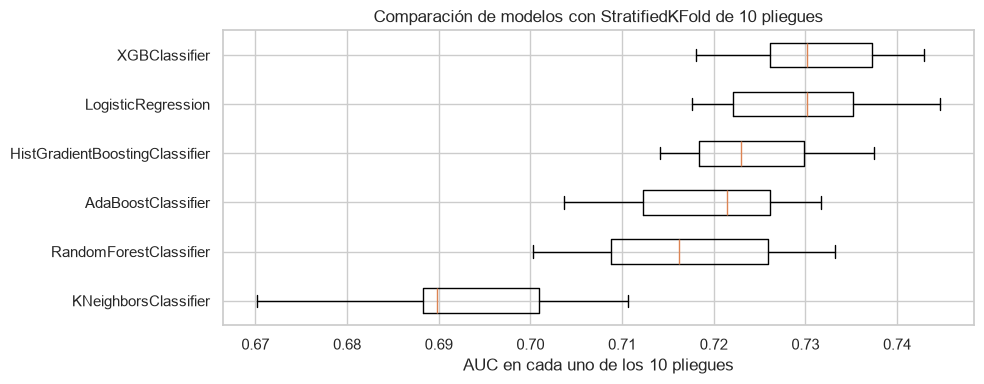

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([resultados_cv[n]["test_auc"] for n in orden[::-1]], vert=False, tick_labels=list(orden[::-1]), widths=0.5)
ax.set_xlabel("AUC en cada uno de los 10 pliegues")
ax.set_title("Comparación de modelos con StratifiedKFold de 10 pliegues")
plt.tight_layout()
guardar_figura("comparacion_modelos", RUN_COMPARACION)

Análisis: las cajas de XGBClassifier y LogisticRegression tienen la misma mediana (cerca de 0.730) y se cruzan casi por completo; la de XGBClassifier es un poco más angosta y está algo más a la derecha (sus 10 AUC van de 0.718 a 0.743). HistGradientBoosting queda un escalón abajo, AdaBoost y RandomForest otro más, y KNeighborsClassifier claramente por debajo del resto. Como las dos primeras cajas se cruzan tanto, la diferencia entre ellas se revisa con la prueba de Wilcoxon.

Prueba de Wilcoxon. Se comprueba si la diferencia de AUC entre el mejor modelo y cada uno de los otros es real o puede deberse a cómo cayeron los pliegues. La prueba compara pliegue por pliegue (es pareada, porque los 10 pliegues son los mismos para todos los modelos) y no supone que los AUC sigan una distribución normal. Un p-valor menor que 0.05 indica que la diferencia es significativa.

In [29]:
# Wilcoxon pareado del mejor modelo frente a cada uno de los otros
mejor_nombre, segundo = orden[0], orden[1]
auc_mejor = resultados_cv[mejor_nombre]["test_auc"]
filas = []
for nombre in orden[1:]:
    auc_otro = resultados_cv[nombre]["test_auc"]
    filas.append({"modelo comparado": nombre, "diferencia media de AUC": np.mean(auc_mejor - auc_otro),
                  "pliegues en que gana el mejor": f"{int((auc_mejor > auc_otro).sum())} de {len(auc_mejor)}",
                  "p-valor": stats.wilcoxon(auc_mejor, auc_otro).pvalue})
tabla_wilcoxon = pd.DataFrame(filas).set_index("modelo comparado")
tabla_wilcoxon["diferencia significativa (p < 0.05)"] = np.where(tabla_wilcoxon["p-valor"] < 0.05, "Sí", "No")
p_segundo = tabla_wilcoxon.loc[segundo, "p-valor"]
motivo = (f"tiene el mayor AUC medio en la validación cruzada y su ventaja sobre {segundo} es significativa (p = {p_segundo:.3f})"
          if p_segundo < 0.05 else
          f"tiene el mayor AUC medio en la validación cruzada, aunque su ventaja sobre {segundo} no es significativa (p = {p_segundo:.3f})")
registrar_tabla(RUN_COMPARACION, tabla_wilcoxon, "wilcoxon")
cliente_mlflow.set_tag(RUN_COMPARACION, "modelo_elegido", mejor_nombre)
print(f"Modelo elegido: {mejor_nombre}, porque {motivo}.")
tabla_wilcoxon.round(4)

Modelo elegido: XGBClassifier, porque tiene el mayor AUC medio en la validación cruzada, aunque su ventaja sobre LogisticRegression no es significativa (p = 0.322).


,diferencia media de AUC,pliegues en que gana el mejor,p-valor,diferencia significativa (p < 0.05)
modelo comparado,,,,
LogisticRegression,0.0014,7 de 10,0.3223,No
HistGradientBoostingClassifier,0.0065,10 de 10,0.0020,Sí
AdaBoostClassifier,0.0121,10 de 10,0.0020,Sí
RandomForestClassifier,0.0137,9 de 10,0.0039,Sí
KNeighborsClassifier,0.0379,10 de 10,0.0020,Sí


Análisis: XGBClassifier le gana a LogisticRegression en 7 de los 10 pliegues, pero con una diferencia media de solo 0.0014 de AUC, y la prueba de Wilcoxon indica que esa diferencia no es significativa (p = 0.322): con estos datos los dos modelos ordenan el riesgo prácticamente igual. Frente a los otros cuatro la ventaja sí es significativa: gana en 10 de 10 pliegues a HistGradientBoosting, AdaBoost y KNN (p = 0.002, el valor más bajo posible con 10 pliegues) y en 9 de 10 a RandomForest (p = 0.004).

Se elige XGBClassifier porque tiene el mayor AUC medio, la menor log-loss y la menor variación entre pliegues, pero sin una ventaja demostrada sobre la regresión logística. Por eso LogisticRegression queda como una alternativa real: más simple de explicar y con un desempeño equivalente.

# 9. Ajuste de hiperparámetros con GridSearchCV

El mejor modelo de la sección 8 se ajusta con GridSearchCV, que prueba todas las combinaciones de una grilla de valores con validación cruzada sobre df_train.

Por qué GridSearchCV:

- Se ajusta un solo modelo y cuatro hiperparámetros con pocos valores cada uno, así que probar todas las combinaciones es viable: 120 combinaciones.
- Es exhaustivo y reproducible: con la misma grilla y los mismos pliegues siempre da el mismo resultado, y permite ver cómo cambia el AUC con cada hiperparámetro (mapa de calor más abajo).
- Una búsqueda aleatoria o bayesiana conviene cuando hay muchos hiperparámetros o rangos muy amplios; aquí la grilla cubre el espacio de forma ordenada a un costo bajo.

Validación de la búsqueda: StratifiedKFold de 5 pliegues sobre df_train, con la misma semilla para todas las combinaciones. Cada pliegue de validación tiene unos 4,000 pacientes, y 5 pliegues en lugar de 10 reducen a la mitad el número de ajustes (600 en lugar de 1,200). La métrica es el AUC, la principal del proyecto.

Grilla de búsqueda para XGBClassifier. Se ajustan los cuatro hiperparámetros que más controlan cuánto aprende el modelo y cuánto se sobreajusta:

| Hiperparámetro | Valores | Escala | Por qué |
|---|---|---|---|
| max_depth | 1, 2, 3, 4, 5 | lineal | Profundidad de cada árbol: cuántas variables puede combinar una regla. Con 1, cada árbol mira una sola variable; cada nivel más duplica las hojas posibles, así que basta con valores consecutivos. Árboles más profundos captan más interacciones, pero se sobreajustan con más facilidad |
| learning_rate | 0.03, 0.06, 0.12 | logarítmica (cada valor duplica al anterior) | Cuánto aporta cada árbol. Su efecto es relativo: pasar de 0.03 a 0.06 pesa tanto como pasar de 0.06 a 0.12 |
| n_estimators | 200, 400, 800, 1,600 | logarítmica (cada valor duplica al anterior) | Número de árboles. Va de la mano con learning_rate: con una tasa baja hacen falta más árboles |
| min_child_weight | 1, 10 | logarítmica | Peso mínimo de pacientes en cada hoja. 1 es el valor por defecto de XGBoost y deja que el árbol separe grupos pequeños; 10 obliga a reglas que apliquen a más pacientes, lo que reduce el sobreajuste |

subsample (0.9) y colsample_bytree (0.8) quedan fijos en los valores de la configuración de partida: cada árbol ve el 90% de los pacientes y el 80% de las columnas, una aleatoriedad moderada que ya ayuda a no sobreajustar. Dejarlos fijos mantiene la grilla en 120 combinaciones.

Los valores extienden la configuración de partida (max_depth 4, learning_rate 0.05, 300 árboles) hacia los dos lados, para que el mejor valor no quede en un borde de la grilla. La tabla de resultados indica si alguno quedó en el valor mínimo o máximo probado. Los demás modelos también tienen su grilla definida en el código, por si en otra ejecución ganara otro.

In [30]:
# GridSearchCV sobre el mejor modelo con 5 pliegues
parametrosGridSearch = {
    "XGBClassifier": {"modelo__max_depth": [1, 2, 3, 4, 5], "modelo__learning_rate": [0.03, 0.06, 0.12],
                      "modelo__n_estimators": [200, 400, 800, 1600], "modelo__min_child_weight": [1, 10]},
    "HistGradientBoostingClassifier": {"modelo__learning_rate": [0.03, 0.06, 0.12], "modelo__max_leaf_nodes": [15, 31, 63],
                                       "modelo__min_samples_leaf": [20, 100], "modelo__max_iter": [200, 400]},
    "LogisticRegression": {"modelo__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], "modelo__class_weight": [None, "balanced"]},
    "RandomForestClassifier": {"modelo__min_samples_leaf": [2, 5, 15], "modelo__max_features": ["sqrt", 0.3]},
    "AdaBoostClassifier": {"modelo__n_estimators": [100, 200, 400], "modelo__learning_rate": [0.3, 0.6, 1.0]},
    "KNeighborsClassifier": {"modelo__n_neighbors": [35, 75, 150], "modelo__weights": ["uniform", "distance"]},
}
estimador_mejor, pca_mejor = modelos[mejor_nombre]
grilla = parametrosGridSearch[mejor_nombre]
inicio = time.time()
busquedaGridSearch = GridSearchCV(crear_pipeline(clone(estimador_mejor), X_train, pca_global=pca_mejor), grilla, scoring="roc_auc",
                                  cv=stratifiedKFold5, n_jobs=-1,
                                  return_train_score=True).fit(X_train, y_train)
minutos = (time.time() - inicio) / 60
resultados_grid = pd.DataFrame(busquedaGridSearch.cv_results_)
mejores_parametros = {k.replace("modelo__", ""): v for k, v in busquedaGridSearch.best_params_.items()}

# Un run anidado por combinación
with iniciar_run(f"gridsearch | {mejor_nombre}") as run:
    RUN_BUSQUEDA = run.info.run_id
    mlflow.log_params({"modelo": mejor_nombre, "metodo": "GridSearchCV", "combinaciones": len(resultados_grid), "pliegues": 5,
                       "metrica": "roc_auc", **{f"mejor_{k}": v for k, v in mejores_parametros.items()}})
    mlflow.log_metrics({"auc_cv_mejor": busquedaGridSearch.best_score_, "minutos": minutos,
                        "auc_entrenamiento_mejor": resultados_grid.loc[busquedaGridSearch.best_index_, "mean_train_score"]})
    for _, fila in resultados_grid.iterrows():
        registrar_variante(" | ".join(f"{k.replace('modelo__', '')}={v}" for k, v in fila["params"].items()),
                           {k.replace("modelo__", ""): v for k, v in fila["params"].items()},
                           {"auc_cv_media": fila["mean_test_score"], "auc_cv_desv": fila["std_test_score"],
                            "auc_entrenamiento": fila["mean_train_score"]})

# Valores elegidos que quedan en el mínimo o el máximo de la grilla
bordes = [f"{k}={v}" for k, v in mejores_parametros.items()
          if isinstance(v, (int, float)) and len(grilla[f"modelo__{k}"]) > 1 and v in (min(grilla[f"modelo__{k}"]), max(grilla[f"modelo__{k}"]))]
print(f"Combinaciones evaluadas: {len(resultados_grid)} en {minutos:.1f} min | mejor AUC: {busquedaGridSearch.best_score_:.4f} | "
      f"rango: {resultados_grid['mean_test_score'].min():.4f} a {resultados_grid['mean_test_score'].max():.4f}")
print("Mejores hiperparámetros:", mejores_parametros)
print("Mejores valores en un borde de la grilla:", ", ".join(bordes) if bordes else "ninguno")
print(f"AUC en entrenamiento del mejor candidato: {resultados_grid.loc[busquedaGridSearch.best_index_, 'mean_train_score']:.4f}")
columnas_param = [c for c in resultados_grid.columns if c.startswith("param_")]
registrar_tabla(RUN_BUSQUEDA, resultados_grid[columnas_param + ["mean_test_score", "std_test_score", "mean_train_score"]], "resultados_gridsearch")
resultados_grid[columnas_param + ["mean_test_score", "std_test_score", "mean_train_score"]].sort_values(
    "mean_test_score", ascending=False).head(8).rename(columns=lambda c: c.replace("param_modelo__", "")).round(4)

Combinaciones evaluadas: 120 en 3.6 min | mejor AUC: 0.7345 | rango: 0.6904 a 0.7345
Mejores hiperparámetros: {'learning_rate': 0.06, 'max_depth': 2, 'min_child_weight': 10, 'n_estimators': 800}
Mejores valores en un borde de la grilla: min_child_weight=10
AUC en entrenamiento del mejor candidato: 0.7651


,learning_rate,max_depth,min_child_weight,n_estimators,mean_test_score,std_test_score,mean_train_score
54,0.06,2,10,800,0.7345,0.0071,0.7651
11,0.03,2,1,1600,0.7344,0.0068,0.7673
50,0.06,2,1,800,0.7342,0.0066,0.7670
15,0.03,2,10,1600,0.7342,0.0067,0.7651
93,0.12,2,10,400,0.7340,0.0071,0.7643
51,0.06,2,1,1600,0.7338,0.0062,0.7853
89,0.12,2,1,400,0.7336,0.0064,0.7665
58,0.06,3,1,800,0.7333,0.0059,0.8096


Análisis: de las 120 combinaciones, la mejor usa árboles de profundidad 2, tasa de aprendizaje 0.06, peso mínimo por hoja de 10 y 800 árboles, con un AUC de 0.7345. El rango completo va de 0.6904 a 0.7345, pero las ocho mejores combinaciones quedan entre 0.7333 y 0.7345, así que cerca del óptimo el modelo es poco sensible a los hiperparámetros.

- learning_rate y n_estimators quedaron dentro de la grilla y se compensan entre sí: las combinaciones con el mismo producto entre tasa y número de árboles dan casi el mismo AUC (0.03 con 1,600 árboles: 0.7344; 0.06 con 800: 0.7345; 0.12 con 400: 0.7340).
- max_depth = 2 también quedó dentro: las siete mejores combinaciones usan profundidad 2 y la mejor con profundidad 3 llega a 0.7333.
- min_child_weight = 10 es el único valor en un borde de la grilla, pero no hace falta seguir buscando: con 1, la misma combinación da 0.7342, una diferencia de 0.0003, muy por debajo de la variación entre pliegues (desviación de 0.007).

El AUC de entrenamiento del mejor candidato (0.7651) es mayor que el de validación cruzada, una diferencia moderada de sobreajuste que los árboles poco profundos y el peso mínimo de 10 pacientes por hoja ayudan a contener.

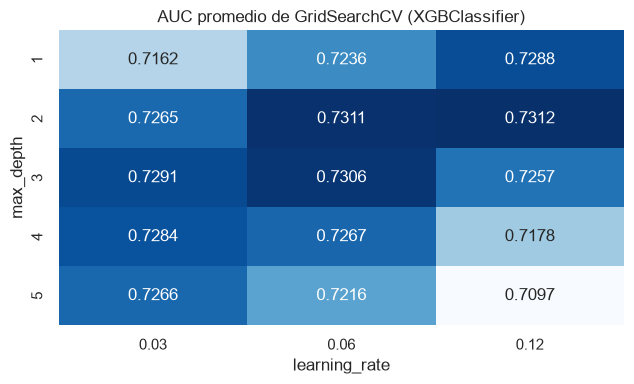

In [31]:
# Mapa de calor del AUC según los dos primeros hiperparámetros
param_fila, param_col = list(grilla)[:2]
mapa_grid = resultados_grid.assign(**{c: resultados_grid[c].astype(str) for c in columnas_param}).pivot_table(
    index=f"param_{param_fila}", columns=f"param_{param_col}", values="mean_test_score", aggfunc="mean")
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(mapa_grid, annot=True, fmt=".4f", cmap="Blues", ax=ax, cbar=False)
ax.set_ylabel(param_fila.replace("modelo__", ""))
ax.set_xlabel(param_col.replace("modelo__", ""))
ax.set_title(f"AUC promedio de GridSearchCV ({mejor_nombre})")
plt.tight_layout()
guardar_figura("gridsearch", RUN_BUSQUEDA)

Análisis: el mapa promedia el resto de hiperparámetros (número de árboles y peso mínimo por hoja). Con árboles poco profundos conviene una tasa de aprendizaje más alta, y con árboles profundos una más baja: con profundidad 1 el mejor promedio es con 0.12 (0.7288) y con profundidad 5, con 0.03 (0.7266). Las mejores celdas son las de profundidad 2 con 0.06 y 0.12 (0.7311 y 0.7312). Los árboles profundos con tasa alta son la peor combinación (0.7097 con profundidad 5 y 0.12), porque se ajustan demasiado rápido a los datos de entrenamiento.

In [32]:
# Modelo ajustado frente al de partida en df_val
def formato_parametros(parametros):
    return ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in parametros.items())


pipelineFinal = busquedaGridSearch.best_estimator_
prob_val = pipelineFinal.predict_proba(X_val)[:, 1].astype(float)
pipelineSinAjuste = crear_pipeline(clone(estimador_mejor), X_train, pca_global=pca_mejor).fit(X_train, y_train)
auc_val, auc_val_sin = roc_auc_score(y_val, prob_val), roc_auc_score(y_val, pipelineSinAjuste.predict_proba(X_val)[:, 1])

# Umbral que maximiza el índice de Youden en df_val
fpr, tpr, umbrales = roc_curve(y_val, prob_val)
UMBRAL = float(umbrales[np.argmax(tpr - fpr)])
pred_val = (prob_val >= UMBRAL).astype(int)
print(f"{mejor_nombre} | hiperparámetros ajustados: {formato_parametros(mejores_parametros)}")
print(f"AUC en df_val: ajustado {auc_val:.4f} | sin ajustar {auc_val_sin:.4f} | diferencia frente a GridSearchCV {busquedaGridSearch.best_score_ - auc_val:+.4f}")
print(f"Umbral de alerta: {UMBRAL:.3f} | recall {recall_score(y_val, pred_val):.3f} | precision {precision_score(y_val, pred_val):.3f}")

with iniciar_run(f"modelo_final | {mejor_nombre}") as run:
    RUN_FINAL = run.info.run_id
    mlflow.log_params({"modelo": mejor_nombre, **mejores_parametros, "umbral": round(UMBRAL, 4),
                       "pacientes_entrenamiento": len(X_train), "motivo_seleccion": motivo})
    mlflow.log_metrics({"auc_cv_gridsearch": busquedaGridSearch.best_score_, "auc_val": auc_val, "auc_val_sin_ajustar": auc_val_sin,
                        "recall_val": recall_score(y_val, pred_val), "precision_val": precision_score(y_val, pred_val)})
    mlflow.sklearn.log_model(pipelineFinal, name="modelo", serialization_format="cloudpickle", input_example=X_train.dropna().head(5))

XGBClassifier | hiperparámetros ajustados: learning_rate=0.06, max_depth=2, min_child_weight=10, n_estimators=800
AUC en df_val: ajustado 0.7420 | sin ajustar 0.7370 | diferencia frente a GridSearchCV -0.0075
Umbral de alerta: 0.548 | recall 0.671 | precision 0.707


Análisis: en df_val el modelo ajustado alcanza 0.7420 de AUC, frente a 0.7370 sin ajustar: el ajuste mejora 0.0050, poco, como anticipaba la grilla. Queda 0.0075 por encima del valor de GridSearchCV (0.7345), así que no hay señal de que la búsqueda haya sobreestimado el resultado. El umbral de alerta que mejor equilibra eventos detectados y falsas alarmas es 0.548: con él se detecta el 67.1% de los eventos y el 70.7% de las alertas son correctas. Es un umbral más exigente que alertar desde 50%, así que cambia algunos eventos detectados por menos falsas alarmas; si el equipo médico prefiere detectar más, puede bajarlo. El umbral se fija aquí, antes de ver df_test.

# 10. Evaluación final en df_test

df_test se usa una sola vez, con el modelo y el umbral ya decididos.

In [33]:
# Evaluación única en df_test
prob_test = pipelineFinal.predict_proba(X_test)[:, 1].astype(float)
pred_test = (prob_test >= UMBRAL).astype(int)
resumen_test = pd.Series({
    "AUC-ROC": roc_auc_score(y_test, prob_test), "average precision": average_precision_score(y_test, prob_test),
    "F1 macro": f1_score(y_test, pred_test, average="macro"), "balanced accuracy": balanced_accuracy_score(y_test, pred_test),
    "recall del evento": recall_score(y_test, pred_test), "precision del evento": precision_score(y_test, pred_test),
    "Brier score": brier_score_loss(y_test, prob_test), "log-loss": log_loss(y_test, prob_test)}, name=mejor_nombre)
CLAVES_METRICAS = {"AUC-ROC": "auc", "average precision": "average_precision", "F1 macro": "f1_macro",
                   "balanced accuracy": "balanced_accuracy", "recall del evento": "recall", "precision del evento": "precision",
                   "Brier score": "brier", "log-loss": "log_loss"}
registrar_metricas(RUN_FINAL, {f"test_{CLAVES_METRICAS[k]}": v for k, v in resumen_test.items()})
print(classification_report(y_test, pred_test, target_names=["Sin evento", "Evento en 12 meses"], digits=3))
resumen_test.round(4).to_frame()

                    precision    recall  f1-score   support

        Sin evento      0.639     0.667     0.653      2029
Evento en 12 meses      0.689     0.661     0.675      2256

          accuracy                          0.664      4285
         macro avg      0.664     0.664     0.664      4285
      weighted avg      0.665     0.664     0.664      4285



,XGBClassifier
AUC-ROC,0.7376
average precision,0.7366
F1 macro,0.6638
balanced accuracy,0.6643
recall del evento,0.6613
precision del evento,0.6885
Brier score,0.2057
log-loss,0.5970


Análisis: en los 4,285 pacientes de df_test el AUC es 0.7376, en línea con la validación cruzada (0.7345 en GridSearchCV) y con df_val (0.7420), lo que confirma que el resultado es estable. Con el umbral de 0.548 el modelo detecta el 66.1% de los eventos (recall) y el 68.9% de sus alertas son correctas (precision). El Brier score de 0.2057 está por debajo de 0.25 y el log-loss de 0.597 por debajo de 0.693, que son los valores que daría predecir siempre 50%.

Intervalo de confianza. Las métricas de df_test salen de una sola muestra de 4,285 pacientes. Con bootstrap (remuestrear df_test con reemplazo 1,000 veces) se estima entre qué valores podrían estar con otra muestra de pacientes parecida.

In [34]:
# Intervalo de confianza del 95% con 1000 remuestreos de df_test
rng = np.random.default_rng(SEMILLA)
y_test_arr = y_test.to_numpy()
muestras = []
for _ in range(1000):
    i = rng.integers(0, len(y_test_arr), len(y_test_arr))
    muestras.append({"AUC-ROC": roc_auc_score(y_test_arr[i], prob_test[i]),
                     "recall del evento": recall_score(y_test_arr[i], pred_test[i]),
                     "precision del evento": precision_score(y_test_arr[i], pred_test[i])})
muestras = pd.DataFrame(muestras)
tabla_ic = pd.DataFrame({"valor en df_test": resumen_test[muestras.columns], "IC 95% inferior": muestras.quantile(0.025),
                         "IC 95% superior": muestras.quantile(0.975)}).round(4)
registrar_metricas(RUN_FINAL, {f"test_{CLAVES_METRICAS[k]}_ic_inferior": v for k, v in tabla_ic["IC 95% inferior"].items()}
                   | {f"test_{CLAVES_METRICAS[k]}_ic_superior": v for k, v in tabla_ic["IC 95% superior"].items()})
tabla_ic

,valor en df_test,IC 95% inferior,IC 95% superior
AUC-ROC,0.7376,0.7214,0.7523
recall del evento,0.6613,0.6422,0.6810
precision del evento,0.6885,0.6684,0.7083


Análisis: con otra muestra de pacientes parecida, el AUC estaría con 95% de confianza entre 0.721 y 0.752; el recall, entre 64.2% y 68.1%, y la precision, entre 66.8% y 70.8%. Es decir, el AUC del modelo está alrededor de 0.74 con un margen de unos 0.015 hacia cada lado. Todo el intervalo queda muy por encima de 0.5 (el azar) y de los índices clínicos de la siguiente celda.

Punto de referencia. Para saber cuánto aporta el modelo, se compara su AUC con el de tres índices que el equipo médico ya usa, cada uno por sí solo: el índice de comorbilidad de Sorror, el grupo de riesgo de la enfermedad y la escala de Karnofsky.

In [35]:
# AUC en df_test de tres índices clínicos usados solos con la tasa de evento de df_train
def auc_indice(col):
    valor = lambda df: df[col].astype(object).where(df[col].notna(), "Sin dato").astype(str)
    tasa = y_train.groupby(valor(df_train).values).mean()
    return roc_auc_score(y_test, valor(df_test).map(tasa).fillna(y_train.mean()))


referencia = pd.Series({"Índice de comorbilidad de Sorror": auc_indice("indice_comorbilidad_sorror"),
                        "Grupo de riesgo de la enfermedad": auc_indice("grupo_riesgo_enfermedad"),
                        "Escala de Karnofsky": auc_indice("escala_karnofsky"),
                        f"{mejor_nombre} (modelo final)": roc_auc_score(y_test, prob_test)}, name="AUC en df_test")
registrar_tabla(RUN_FINAL, referencia.to_frame(), "referencia_indices_clinicos")
referencia.round(4).to_frame()

,AUC en df_test
Índice de comorbilidad de Sorror,0.5692
Grupo de riesgo de la enfermedad,0.6119
Escala de Karnofsky,0.5654
XGBClassifier (modelo final),0.7376


Análisis: usados por sí solos, los índices que el equipo médico ya conoce ordenan el riesgo mucho peor que el modelo: el índice de Sorror logra un AUC de 0.569, la escala de Karnofsky 0.565 y el grupo de riesgo de la enfermedad 0.612, frente a 0.738 del modelo. Cada índice mira una sola dimensión del paciente; el modelo combina las 56 variables.

## 10.1 Matriz de confusión y curvas

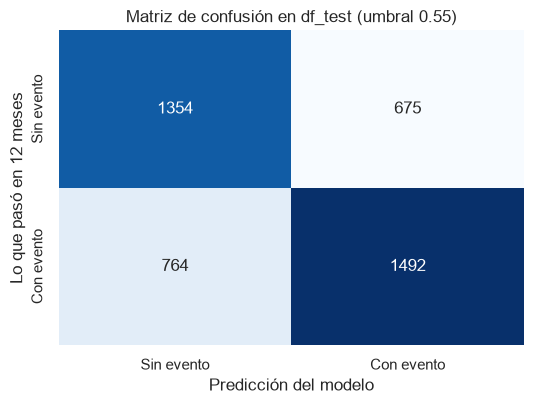

In [36]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(confusion_matrix(y_test, pred_test), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Sin evento", "Con evento"], yticklabels=["Sin evento", "Con evento"])
ax.set_xlabel("Predicción del modelo")
ax.set_ylabel("Lo que pasó en 12 meses")
ax.set_title(f"Matriz de confusión en df_test (umbral {UMBRAL:.2f})")
plt.tight_layout()
guardar_figura("matriz_confusion", RUN_FINAL)

Análisis: de los 2,256 pacientes que sí tuvieron un evento, el modelo alertó a 1,492 y no detectó a 764. De los 2,029 sin evento, 1,354 quedaron bien clasificados y 675 recibieron una alerta de más. En la práctica, un falso negativo es un paciente de alto riesgo con seguimiento habitual y un falso positivo es un control adicional; si el equipo prefiere detectar más eventos, puede bajar el umbral a cambio de más alertas.

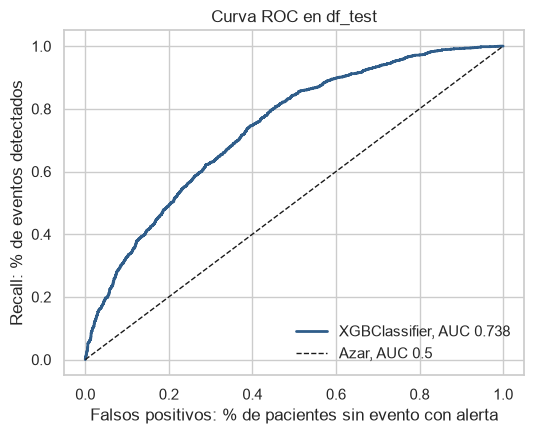

In [37]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
f, t, _ = roc_curve(y_test, prob_test)
ax.plot(f, t, color=AZUL, linewidth=2, label=f"{mejor_nombre}, AUC {roc_auc_score(y_test, prob_test):.3f}")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Azar, AUC 0.5")
ax.set_xlabel("Falsos positivos: % de pacientes sin evento con alerta")
ax.set_ylabel("Recall: % de eventos detectados")
ax.set_title("Curva ROC en df_test")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
guardar_figura("curva_roc", RUN_FINAL)

Análisis: la curva queda muy por encima de la diagonal del azar en todo su recorrido. Cada punto es un umbral posible: por ejemplo, para detectar cerca del 80% de los eventos hay que aceptar que cerca del 45% de los pacientes sin evento reciba una alerta. El AUC de 0.738 resume esa capacidad de ordenar a los pacientes por riesgo.

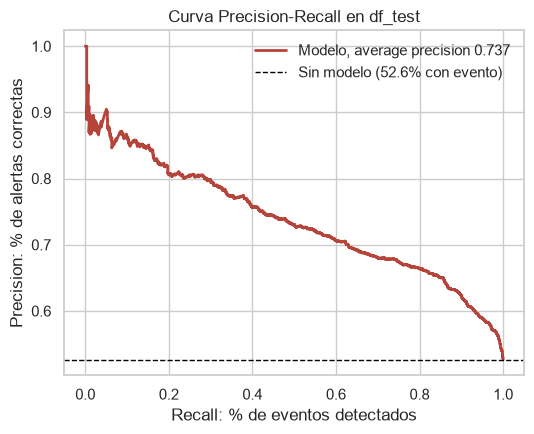

In [38]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
pr, rc, _ = precision_recall_curve(y_test, prob_test)
ax.plot(rc, pr, color=ROJO, linewidth=2, label=f"Modelo, average precision {average_precision_score(y_test, prob_test):.3f}")
ax.axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label=f"Sin modelo ({y_test.mean():.1%} con evento)")
ax.set_xlabel("Recall: % de eventos detectados")
ax.set_ylabel("Precision: % de alertas correctas")
ax.set_title("Curva Precision-Recall en df_test")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("curva_pr", RUN_FINAL)

Análisis: sin modelo, alertar a todos daría una precision de 52.6%, la proporción de pacientes con evento. El modelo mantiene una precision de 80% o más mientras detecta hasta cerca del 25% de los eventos, que son los pacientes de mayor riesgo, y todavía de 70% cuando detecta el 60%. El average precision de 0.737 está muy por encima de esa línea base.

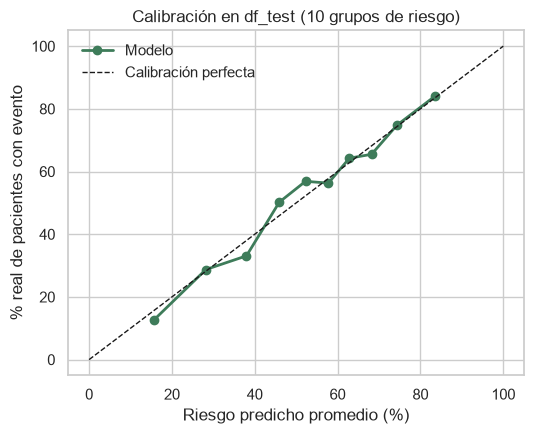

In [39]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
frac_real, prob_media = calibration_curve(y_test, prob_test, n_bins=10, strategy="quantile")
ax.plot(prob_media * 100, frac_real * 100, marker="o", color=VERDE, linewidth=2, label="Modelo")
ax.plot([0, 100], [0, 100], "k--", linewidth=1, label="Calibración perfecta")
ax.set_xlabel("Riesgo predicho promedio (%)")
ax.set_ylabel("% real de pacientes con evento")
ax.set_title("Calibración en df_test (10 grupos de riesgo)")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("calibracion", RUN_FINAL)

Análisis: los puntos siguen de cerca la diagonal en casi todo el rango, de 16% a 84% de riesgo predicho. Los desvíos son pequeños: en el grupo de menor riesgo el modelo predice 16% y ocurre 13%, en el tercero predice 38% y ocurre 33%, y en el cuarto predice 46% y ocurre 50%. Las probabilidades se pueden leer casi de forma literal: entre los pacientes a los que el modelo les asigna cerca de 75% de riesgo, alrededor de 3 de cada 4 tienen un evento.

## 10.2 Riesgo por deciles

Decil de menor riesgo: 12.6% | decil de mayor riesgo: 84.1% | 6.7 veces más


,pacientes,riesgo_medio_predicho,tasa_real_de_evento
decil,,,
D1,429,0.156,0.126
D2,428,0.282,0.287
D3,429,0.380,0.331
D4,428,0.459,0.502
D5,429,0.523,0.569
D6,428,0.578,0.563
D7,428,0.628,0.643
D8,429,0.682,0.655
D9,428,0.743,0.748


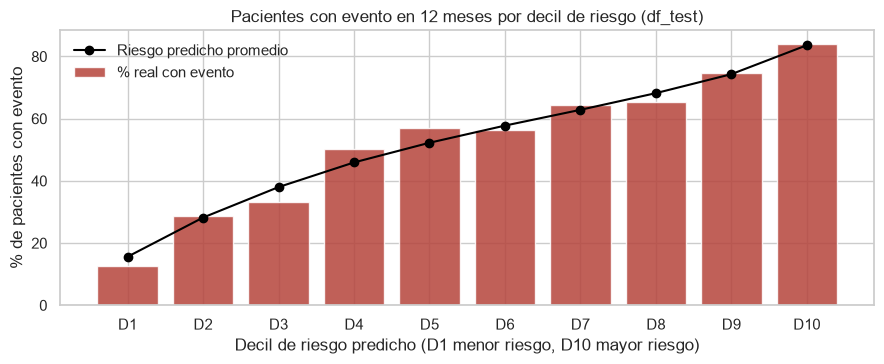

In [40]:
# Porcentaje real con evento por decil de riesgo predicho
tabla_deciles = pd.DataFrame({"riesgo": prob_test, "evento": y_test.values,
                              "decil": pd.qcut(prob_test, 10, labels=[f"D{i}" for i in range(1, 11)])}).groupby(
    "decil", observed=True).agg(pacientes=("evento", "size"), riesgo_medio_predicho=("riesgo", "mean"), tasa_real_de_evento=("evento", "mean"))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(tabla_deciles.index.astype(str), tabla_deciles["tasa_real_de_evento"] * 100, color=ROJO, alpha=0.85, label="% real con evento")
ax.plot(tabla_deciles.index.astype(str), tabla_deciles["riesgo_medio_predicho"] * 100, color="black", marker="o", label="Riesgo predicho promedio")
ax.set_xlabel("Decil de riesgo predicho (D1 menor riesgo, D10 mayor riesgo)")
ax.set_ylabel("% de pacientes con evento")
ax.set_title("Pacientes con evento en 12 meses por decil de riesgo (df_test)")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("deciles", RUN_FINAL)
bajo, alto = tabla_deciles["tasa_real_de_evento"].iloc[0], tabla_deciles["tasa_real_de_evento"].iloc[-1]
print(f"Decil de menor riesgo: {bajo:.1%} | decil de mayor riesgo: {alto:.1%} | {alto / bajo:.1f} veces más")
registrar_tabla(RUN_FINAL, tabla_deciles, "deciles_df_test")
tabla_deciles.round(3)

Análisis: es la lectura más útil para el equipo clínico. En el 10% de pacientes de menor riesgo solo el 12.6% tuvo un evento en el primer año; en el 10% de mayor riesgo, el 84.1%, es decir, 6.7 veces más. La tasa real sube decil a decil, salvo el decil 6, que queda apenas por debajo del 5 (56.3% frente a 56.9%), y coincide con el riesgo predicho. Esto permite definir tres niveles: bajo (deciles 1 a 3, de 13% a 33%), intermedio y alto (deciles 8 a 10, de 66% a 84%).

## 10.3 Desempeño por subgrupo

Se revisa el desempeño por grupo de edad, tipo de injerto, periodo del trasplante (los registros de 2018 a 2020 son los más incompletos, sección 5.4) y número de variables vacías, para saber dónde el modelo es más o menos confiable.

In [41]:
# Desempeño por grupo de edad y tipo de injerto
df_resultados = df_test.assign(prob=prob_test, pred=pred_test)
df_resultados["grupo_edad"] = pd.cut(df_resultados["edad_paciente"].astype(float), [-1, 17, 40, 60, 100],
                                     labels=["Menor de 18", "18 a 40", "41 a 60", "Mayor de 60"]).astype(str)
def resumen_por(col):
    filas = [{col: v, "pacientes": len(g), "% con evento": g["evento_12m"].mean() * 100, "AUC": roc_auc_score(g["evento_12m"], g["prob"]),
              "recall del evento": recall_score(g["evento_12m"], g["pred"])}
             for v, g in df_resultados.groupby(col) if len(g) >= 80]
    return pd.DataFrame(filas).set_index(col).round(3)
display(resumen_por("grupo_edad"))
resumen_por("tipo_injerto")

,pacientes,% con evento,AUC,recall del evento
grupo_edad,,,,
18 a 40,1121,53.791,0.688,0.619
41 a 60,1330,58.797,0.704,0.742
Mayor de 60,792,64.646,0.699,0.820
Menor de 18,1042,34.453,0.748,0.331


,pacientes,% con evento,AUC,recall del evento
tipo_injerto,,,,
Bone marrow,1236,35.113,0.733,0.283
Peripheral blood,3049,59.757,0.703,0.751


Análisis: el modelo ordena bien el riesgo en todos los grupos de edad (AUC de 0.688 a 0.748), y mejor aún en los menores de 18. El punto débil es el umbral: en los niños, que tienen un riesgo base mucho menor (34.5% con evento), el umbral general solo detecta el 33.1% de sus eventos. Lo mismo pasa con el injerto de médula ósea (recall de 0.283), un grupo que también tiene un riesgo base bajo (35.1% con evento). Para pacientes pediátricos conviene un umbral propio más bajo.

In [42]:
# Desempeño por periodo del trasplante y por número de variables vacías
df_resultados["periodo_trasplante"] = pd.cut(df_resultados["anio_trasplante"], [2007, 2012, 2017, 2020],
                                             labels=["2008 a 2012", "2013 a 2017", "2018 a 2020"]).astype(str)
df_resultados["variables_vacias"] = pd.cut(df_resultados[COLUMNAS_CON_NULOS].isna().sum(axis=1), [-1, 0, 2, 60],
                                           labels=["0", "1 a 2", "3 o más"]).astype(str)
display(resumen_por("periodo_trasplante"))
resumen_por("variables_vacias")

,pacientes,% con evento,AUC,recall del evento
periodo_trasplante,,,,
2008 a 2012,833,62.305,0.751,0.694
2013 a 2017,2234,53.939,0.736,0.667
2018 a 2020,1218,43.678,0.725,0.617


,pacientes,% con evento,AUC,recall del evento
variables_vacias,,,,
0,2532,60.940,0.687,0.708
1 a 2,1132,39.841,0.760,0.532
3 o más,621,42.190,0.763,0.607


Análisis: por periodo, el AUC baja poco con los años: 0.751 entre 2008 y 2012, 0.736 entre 2013 y 2017 y 0.725 entre 2018 y 2020. En el último periodo hay menos eventos (43.7%) y el recall baja a 61.7%, frente a 69.4% en el primero. Con los datos vacíos pasa algo parecido: los pacientes sin vacíos tienen más eventos (60.9%) y el modelo detecta el 70.8%; los que tienen uno o más vacíos tienen menos eventos (40% a 42%) y el recall baja a entre 53% y 61%, aunque el modelo los ordena mejor (AUC de 0.76 frente a 0.69). El modelo no pierde capacidad de ordenar cuando faltan datos o en los años recientes; lo que cambia es el riesgo base de esos grupos.

## 10.4 Errores del modelo

Con el umbral elegido, cada paciente de df_test cae en uno de cuatro grupos: evento detectado, evento no detectado (falso negativo), falsa alarma (falso positivo) o sin evento y sin alerta. Se compara el perfil de los cuatro grupos para ver qué tienen en común los casos en que el modelo se equivoca.

In [43]:
# Perfil de aciertos y errores con el umbral elegido
df_errores = df_resultados.copy()
df_errores["resultado"] = np.select(
    [(df_errores["pred"] == 1) & (df_errores["evento_12m"] == 1), (df_errores["pred"] == 0) & (df_errores["evento_12m"] == 1),
     (df_errores["pred"] == 1) & (df_errores["evento_12m"] == 0)],
    ["Evento detectado", "Evento no detectado", "Falsa alarma"], "Sin evento y sin alerta")
df_errores["cerca_del_umbral"] = (df_errores["prob"] - UMBRAL).abs() <= 0.10
perfil_errores = df_errores.groupby("resultado").agg(
    pacientes=("id", "size"), riesgo_predicho_medio=("prob", "mean"), pct_a_menos_de_10_puntos_del_umbral=("cerca_del_umbral", "mean"),
    edad_mediana=("edad_paciente", "median"), pct_menores_de_18=("es_pediatrico", "mean"),
    pct_medula_osea=("tipo_injerto", lambda s: (s == "Bone marrow").mean()),
    sorror_mediano=("indice_comorbilidad_sorror", "median"),
    pct_con_datos_vacios=("variables_vacias", lambda s: (s != "0").mean()),
    pct_trasplante_2018_o_despues=("anio_trasplante", lambda s: (s >= 2018).mean()))
columnas_pct = [c for c in perfil_errores.columns if c.startswith("pct_") or c == "riesgo_predicho_medio"]
perfil_errores[columnas_pct] = perfil_errores[columnas_pct] * 100
perfil_errores = perfil_errores.loc[["Evento detectado", "Evento no detectado", "Falsa alarma", "Sin evento y sin alerta"]]
registrar_tabla(RUN_FINAL, perfil_errores, "perfil_errores")
perfil_errores.round(1)

,pacientes,riesgo_predicho_medio,pct_a_menos_de_10_puntos_del_umbral,edad_mediana,pct_menores_de_18,pct_medula_osea,sorror_mediano,pct_con_datos_vacios,pct_trasplante_2018_o_despues
resultado,,,,,,,,,
Evento detectado,1492,70.5,33.3,51.0,8.0,8.2,2.0,26.7,22.0
Evento no detectado,764,41.6,50.4,34.5,31.4,40.7,1.0,41.1,26.7
Falsa alarma,675,66.3,49.5,50.0,8.1,11.4,2.0,32.3,32.4
Sin evento y sin alerta,1354,32.5,23.2,22.0,46.4,53.5,1.0,60.7,34.5


Análisis: los dos tipos de error tienen perfiles distintos. Los eventos no detectados (764) se parecen a los pacientes de bajo riesgo: edad mediana de 34.5 años, 31% son menores de 18, 41% recibió médula ósea, Sorror mediano de 1 y 41% tiene algún dato vacío, frente a 8%, 8% y 27% en los eventos que sí se detectan. Las falsas alarmas (675) se parecen a los pacientes con evento: edad mediana de 50 años, pocos niños (8%) y Sorror mediano de 2; además, un tercio son trasplantes de 2018 o después (32%). La mitad de los errores (50% de los eventos no detectados y 50% de las falsas alarmas) tienen un riesgo predicho a menos de 10 puntos del umbral, es decir, son casos dudosos.

Errores: 1,439 de 4,285 pacientes (33.6%) | a menos de 10 puntos del umbral: 50.0%
Eventos no detectados con riesgo predicho menor a 30%: 129 | falsas alarmas con riesgo mayor a 70%: 198


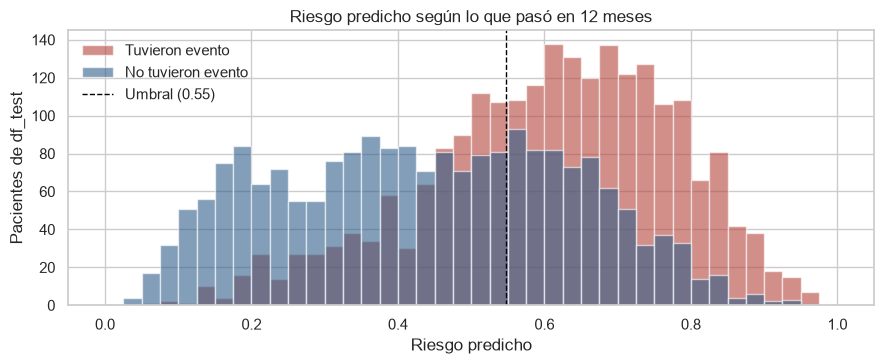

In [44]:
# Riesgo predicho según lo que pasó en 12 meses
fig, ax = plt.subplots(figsize=(9, 3.8))
bordes = np.linspace(0, 1, 41)
ax.hist(prob_test[y_test_arr == 1], bins=bordes, alpha=0.6, color=ROJO, label="Tuvieron evento")
ax.hist(prob_test[y_test_arr == 0], bins=bordes, alpha=0.6, color=AZUL, label="No tuvieron evento")
ax.axvline(UMBRAL, color="black", linestyle="--", linewidth=1, label=f"Umbral ({UMBRAL:.2f})")
ax.set_xlabel("Riesgo predicho")
ax.set_ylabel("Pacientes de df_test")
ax.set_title("Riesgo predicho según lo que pasó en 12 meses")
ax.legend(frameon=False)
plt.tight_layout()
guardar_figura("errores", RUN_FINAL)
es_error = df_errores["resultado"].isin(["Evento no detectado", "Falsa alarma"])
print(f"Errores: {es_error.sum():,} de {len(df_errores):,} pacientes ({es_error.mean():.1%}) | "
      f"a menos de 10 puntos del umbral: {df_errores.loc[es_error, 'cerca_del_umbral'].mean():.1%}")
print(f"Eventos no detectados con riesgo predicho menor a 30%: {((df_errores['resultado'] == 'Evento no detectado') & (df_errores['prob'] < 0.30)).sum()} | "
      f"falsas alarmas con riesgo mayor a 70%: {((df_errores['resultado'] == 'Falsa alarma') & (df_errores['prob'] > 0.70)).sum()}")

Análisis: los pacientes con evento (rojo) se concentran a la derecha y los que no lo tuvieron (azul) a la izquierda, pero las dos distribuciones se cruzan en la zona media, entre 40% y 70% de riesgo. Ahí se acumulan muchos de los errores: de los 1,439 (33.6% de df_test), el 50.0% tiene un riesgo a menos de 10 puntos del umbral. Los errores con mucha seguridad son menos: 129 eventos no detectados tenían un riesgo menor a 30% y 198 falsas alarmas un riesgo mayor a 70%. Esos casos, con un perfil que el modelo no logra distinguir, son los que más conviene revisar con el equipo clínico.

# 11. Análisis a 6, 12 y 18 meses

Para revisar si el horizonte de 12 meses fue una buena elección, se repite el entrenamiento con el evento a 6 y a 18 meses.

In [45]:
# El pipeline final entrenado para el evento a 6 12 y 18 meses sin los pacientes de df_test
df_sin_test = df_clean[~df_clean["id"].isin(df_test["id"])]
filas = []
for h in (6, 12, 18):
    df_h = construir_objetivo(df_sin_test, h)
    auc = cross_validate(clone(pipelineFinal), preparar_X(df_h), df_h["evento_12m"], cv=stratifiedKFold5, scoring="roc_auc", n_jobs=-1)["test_score"]
    filas.append({"horizonte (meses)": h, "pacientes": len(df_h),
                  "% excluidos por censura": ((df_clean["evento"] == 0) & (df_clean["meses_hasta_evento"] < h)).mean() * 100,
                  "% con evento en el horizonte": df_h["evento_12m"].mean() * 100, "AUC (media)": auc.mean(), "AUC (desv.)": auc.std()})
tabla_horizontes = pd.DataFrame(filas).set_index("horizonte (meses)")
registrar_metricas(RUN_FINAL, {f"auc_horizonte_{h}_meses": tabla_horizontes.loc[h, "AUC (media)"] for h in tabla_horizontes.index})
tabla_horizontes.round(3)

,pacientes,% excluidos por censura,% con evento en el horizonte,AUC (media),AUC (desv.)
horizonte (meses),,,,,
6,24496,0.066,29.066,0.725,0.006
12,24277,0.826,52.626,0.735,0.006
18,23589,3.764,55.602,0.739,0.008


Análisis: el modelo rinde parecido en los tres horizontes (AUC de 0.725, 0.735 y 0.739), así que la elección se basa en el problema y no en la métrica. A 6 meses solo el 29.1% de los pacientes tiene evento, porque se pierde casi la mitad de los que ocurren en el primer año. A 18 meses la proporción casi no sube (55.6% frente a 52.6%), pero se excluye el 3.8% de los pacientes por censura, cuatro veces y media más que a 12 meses. El horizonte de 12 meses captura casi todos los eventos con la menor pérdida de pacientes.

# 12. Explicabilidad

Tres preguntas: cómo se leen las contribuciones del modelo, de qué variables depende más y por qué le asigna a un paciente concreto su riesgo. Se responden con la escala de log-odds (12.1), la importancia por permutación (12.2) y SHAP (12.3 y 12.4).

## 12.1 Cómo leer las contribuciones: log-odds y probabilidad

Los modelos de este tipo no suman probabilidades sino log-odds, una escala en la que los efectos de las variables sí se pueden sumar. Se pasa de una a otra con la fórmula probabilidad = 1 / (1 + e^(−log-odds)): un log-odds de 0 equivale a 50% de riesgo, los valores positivos suben el riesgo y los negativos lo bajan.

Lo importante para leer las gráficas de SHAP es que una misma contribución no siempre mueve el riesgo lo mismo: lo mueve más cuando el paciente está cerca del 50% que cuando ya está muy alto o muy bajo. La tabla muestra el riesgo que resulta de sumar varias contribuciones a distintos riesgos de partida.

In [46]:
# Riesgo final al sumar una contribución en log odds a distintos riesgos de partida
a_probabilidad = lambda z: 1 / (1 + np.exp(-z))
a_log_odds = lambda p: np.log(p / (1 - p))
riesgos_partida = [0.10, 0.30, 0.50, 0.70, 0.90]
tabla_escala = pd.DataFrame({f"{c:+.1f} log-odds": [a_probabilidad(a_log_odds(p) + c) * 100 for p in riesgos_partida]
                             for c in [-1.0, -0.5, -0.2, 0.2, 0.5, 1.0]},
                            index=[f"riesgo de partida {p:.0%}" for p in riesgos_partida]).round(1)
tabla_escala

,-1.0 log-odds,-0.5 log-odds,-0.2 log-odds,+0.2 log-odds,+0.5 log-odds,+1.0 log-odds
riesgo de partida 10%,3.9,6.3,8.3,11.9,15.5,23.2
riesgo de partida 30%,13.6,20.6,26.0,34.4,41.4,53.8
riesgo de partida 50%,26.9,37.8,45.0,55.0,62.2,73.1
riesgo de partida 70%,46.2,58.6,65.6,74.0,79.4,86.4
riesgo de partida 90%,76.8,84.5,88.1,91.7,93.7,96.1


Análisis: la tabla muestra por qué SHAP se lee en log-odds. Una contribución de +0.5 lleva a un paciente de 50% a 62.2% (12 puntos más), pero a uno de 90% solo lo lleva a 93.7% (4 puntos) y a uno de 10% a 15.5% (5 puntos). Los log-odds se suman igual sin importar dónde esté el paciente; los puntos de probabilidad no. Por eso las gráficas de SHAP están en log-odds y, para leerlas en lenguaje clínico, el notebook también traduce las contribuciones a puntos de riesgo.

## 12.2 Importancia por permutación: cuánto empeora el modelo sin cada variable

Se desordena una variable en df_val (se mezclan sus valores entre pacientes, así pierde su relación con el resultado) y se mide cuánto empeoran dos métricas:

- El log-loss, que castiga las probabilidades equivocadas, y más aún las equivocadas con mucha seguridad (decir 90% de riesgo a alguien que no tuvo el evento). Más bajo es mejor. Si al desordenar una variable el log-loss sube mucho, el modelo depende de ella.
- El AUC, que mide si el modelo sigue ordenando bien a los pacientes por riesgo.

Se repite 5 veces por variable y las 17 variables HLA se desordenan juntas, como un solo factor. A diferencia de SHAP, esta medida no depende de cómo funciona el modelo por dentro: solo compara sus resultados con y sin la variable.

Modelo con los datos originales en df_val: log-loss 0.5978 | AUC 0.7420


,aumento del log-loss,desv. del aumento,caída del AUC
variable,,,
intensidad_acondicionamiento,0.0123,0.0020,0.0167
sexo_donante_receptor,0.0102,0.0011,0.0140
enfermedad_principal,0.0099,0.0016,0.0124
compatibilidad_hla,0.0090,0.0009,0.0124
serologia_cmv,0.0080,0.0004,0.0109
indice_comorbilidad_sorror,0.0064,0.0012,0.0079
escala_karnofsky,0.0062,0.0010,0.0082
edad_paciente,0.0045,0.0003,0.0065
profilaxis_injerto_huesped,0.0043,0.0009,0.0056


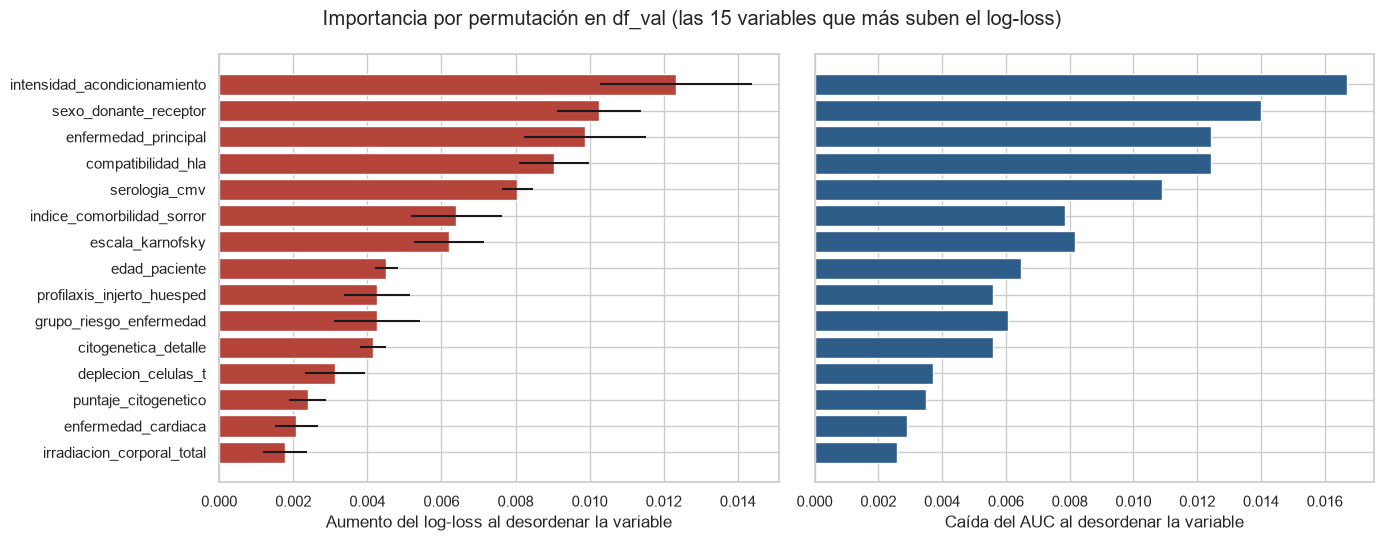

In [47]:
# Cambio del log loss y del AUC en df_val al desordenar cada variable
rng = np.random.default_rng(SEMILLA)
prob_val_base = pipelineFinal.predict_proba(X_val)[:, 1]
logloss_base, auc_base = log_loss(y_val, prob_val_base), roc_auc_score(y_val, prob_val_base)
grupos_permutacion = {"compatibilidad_hla": COLUMNAS_HLA} | {c: [c] for c in COLUMNAS_ENTRADA if c not in COLUMNAS_HLA}
filas = []
for variable, columnas in grupos_permutacion.items():
    cambios_logloss, cambios_auc = [], []
    for _ in range(5):
        orden_filas = rng.permutation(len(X_val))
        X_permutado = X_val.copy()
        for c in columnas:
            X_permutado[c] = X_val[c].iloc[orden_filas].array
        prob = pipelineFinal.predict_proba(X_permutado)[:, 1]
        cambios_logloss.append(log_loss(y_val, prob) - logloss_base)
        cambios_auc.append(auc_base - roc_auc_score(y_val, prob))
    filas.append({"variable": variable, "aumento del log-loss": np.mean(cambios_logloss),
                  "desv. del aumento": np.std(cambios_logloss), "caída del AUC": np.mean(cambios_auc)})
importancia_permutacion = pd.DataFrame(filas).set_index("variable").sort_values("aumento del log-loss", ascending=False)
registrar_tabla(RUN_FINAL, importancia_permutacion, "importancia_permutacion")

top = importancia_permutacion.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
axes[0].barh(top.index, top["aumento del log-loss"], xerr=top["desv. del aumento"], color=ROJO)
axes[0].set_xlabel("Aumento del log-loss al desordenar la variable")
axes[1].barh(top.index, top["caída del AUC"], color=AZUL)
axes[1].set_xlabel("Caída del AUC al desordenar la variable")
plt.suptitle("Importancia por permutación en df_val (las 15 variables que más suben el log-loss)")
plt.tight_layout()
guardar_figura("importancia_permutacion", RUN_FINAL)
print(f"Modelo con los datos originales en df_val: log-loss {logloss_base:.4f} | AUC {auc_base:.4f}")
importancia_permutacion.head(15).round(4)

Análisis: con los datos originales el modelo tiene en df_val un log-loss de 0.598 y un AUC de 0.742. La variable que más empeora el modelo al desordenarla es la intensidad del acondicionamiento (el log-loss sube 0.012 y el AUC baja 0.017), seguida de la combinación de sexos de donante y receptor, la enfermedad principal, la compatibilidad HLA y la serología de CMV. Las dos medidas dan casi el mismo orden. Los efectos son pequeños porque cada variable aporta solo una parte del riesgo. Algunas variables comparten información (por ejemplo, la edad del paciente con es_pediatrico y con la diferencia de edad con el donante, o Sorror con el número de comorbilidades), así que al desordenar una el modelo puede apoyarse en las otras y su importancia aparece más baja.

## 12.3 SHAP: efecto de cada variable

SHAP reparte la predicción de cada paciente entre sus variables: cuánto sube o baja el riesgo cada una frente al riesgo promedio. Las contribuciones de un paciente, sumadas al valor base, dan exactamente su predicción. Se calcula sobre 2,000 pacientes de df_val con el modelo final, y los valores de las columnas que ve el modelo (las de OneHotEncoder de las categorías y de los niveles HLA) se suman por variable original.

In [48]:
# SHAP en las columnas del modelo sumado por variable original
columnTransformer = pipelineFinal.named_steps["columnTransformer"]
estimador_final = pipelineFinal.named_steps["modelo"]
nombres_columnas = columnTransformer.get_feature_names_out()
if isinstance(estimador_final, LogisticRegression):
    fondo = columnTransformer.transform(X_train.sample(500, random_state=SEMILLA))
    explicadorShap = shap.LinearExplainer(estimador_final, shap.maskers.Independent(fondo, max_samples=len(fondo)))
    ESCALA_SHAP, n_shap = "log-odds", 2000
elif isinstance(estimador_final, (XGBClassifier, HistGradientBoostingClassifier)):
    explicadorShap = shap.TreeExplainer(estimador_final)
    ESCALA_SHAP, n_shap = "log-odds", 2000
elif isinstance(estimador_final, RandomForestClassifier):
    explicadorShap = shap.TreeExplainer(estimador_final)
    ESCALA_SHAP, n_shap = "probabilidad", 2000
else:
    fondo = shap.sample(columnTransformer.transform(X_train), 100, random_state=SEMILLA)
    explicadorShap = shap.Explainer(lambda x: estimador_final.predict_proba(x)[:, 1], fondo, seed=SEMILLA)
    ESCALA_SHAP, n_shap = "probabilidad", 300
X_shap = X_val.sample(n_shap, random_state=SEMILLA)
valores_shap = explicadorShap(columnTransformer.transform(X_shap))
if valores_shap.values.ndim == 3:
    valores_shap = valores_shap[:, :, 1]


def variable_original(nombre):
    bloque, resto = nombre.split("__", 1)
    if bloque == "hla":
        return "compatibilidad_hla"
    if bloque in ("continuas", "binarias"):
        return resto
    return next(c for c in sorted(categoricas, key=len, reverse=True) if resto.startswith(c + "_"))


df_shap = pd.DataFrame(valores_shap.values, columns=[variable_original(n) for n in nombres_columnas]).T.groupby(level=0).sum().T
valor_base = float(np.atleast_1d(valores_shap.base_values)[0])
a_riesgo = a_probabilidad if ESCALA_SHAP == "log-odds" else (lambda z: z)
riesgo_base = a_riesgo(valor_base)
print(f"Pacientes explicados: {len(X_shap)} | columnas del modelo: {len(nombres_columnas)} | variables originales: {df_shap.shape[1]}")
print(f"Escala de SHAP: {ESCALA_SHAP} | valor base: {valor_base:.3f}, que equivale a un riesgo de {riesgo_base:.1%}")

Pacientes explicados: 2000 | columnas del modelo: 217 | variables originales: 40
Escala de SHAP: log-odds | valor base: 0.105, que equivale a un riesgo de 52.6%


Análisis: SHAP calcula una contribución para cada una de las 217 columnas del modelo y esas contribuciones se suman en las 40 variables originales; las 17 HLA quedan juntas como compatibilidad_hla. El punto de partida (valor base) es 0.105 en log-odds, que equivale al 52.6% de riesgo promedio. Cada paciente parte de ahí y sus variables lo suben o lo bajan.

,SHAP medio absoluto (log-odds),puntos de riesgo en promedio
sexo_donante_receptor,0.199,4.114
intensidad_acondicionamiento,0.179,3.756
profilaxis_injerto_huesped,0.158,3.318
grupo_riesgo_enfermedad,0.132,2.702
enfermedad_principal,0.122,2.394
indice_comorbilidad_sorror,0.117,2.347
compatibilidad_hla,0.116,2.409
serologia_cmv,0.111,2.298
deplecion_celulas_t,0.109,2.253
puntaje_citogenetico,0.109,2.270


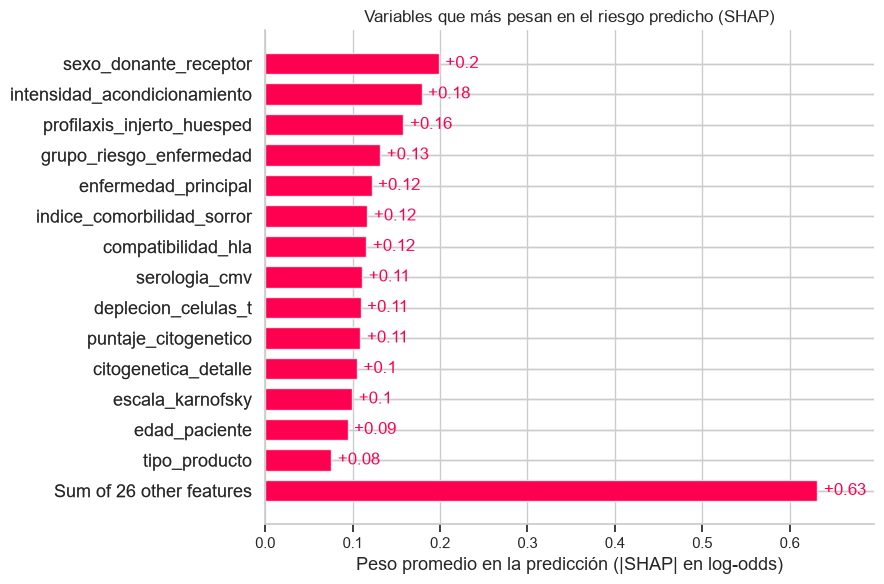

In [49]:
# Importancia global con el promedio del valor absoluto de SHAP
importancia_shap = df_shap.abs().mean().sort_values(ascending=False)
hla8_numerico = df_val.loc[X_shap.index, "hla_alta_res_8"].replace(-1, np.nan)
datos_color = X_shap.assign(compatibilidad_hla=hla8_numerico)[importancia_shap.index]
datos_color = datos_color.apply(lambda s: pd.to_numeric(s, errors="coerce")).astype(float)
explicacion = shap.Explanation(values=df_shap[importancia_shap.index].values, base_values=np.full(len(df_shap), valor_base),
                               data=datos_color.values, feature_names=list(importancia_shap.index))
shap.plots.bar(explicacion, max_display=15, show=False)
plt.gcf().set_size_inches(9, 6)
plt.xlabel(f"Peso promedio en la predicción (|SHAP| en {ESCALA_SHAP})")
plt.title("Variables que más pesan en el riesgo predicho (SHAP)")
plt.tight_layout()
guardar_figura("shap_importancia", RUN_FINAL)

# La misma importancia en puntos de riesgo
total_shap = valor_base + df_shap.sum(axis=1)
puntos_riesgo = pd.DataFrame({c: (a_riesgo(total_shap) - a_riesgo(total_shap - df_shap[c])).abs() * 100 for c in df_shap.columns}).mean()
tabla_importancia_shap = pd.DataFrame({f"SHAP medio absoluto ({ESCALA_SHAP})": importancia_shap,
                                       "puntos de riesgo en promedio": puntos_riesgo[importancia_shap.index]})
registrar_tabla(RUN_FINAL, tabla_importancia_shap, "importancia_shap")
tabla_importancia_shap.head(15).round(3)

Análisis: las variables que más pesan son la combinación de sexos de donante y receptor (4.1 puntos de riesgo en promedio), la intensidad del acondicionamiento (3.8), profilaxis_injerto_huesped, los medicamentos para evitar que las células del donante ataquen al paciente (3.3), el grupo de riesgo de la enfermedad (2.7) y la enfermedad principal (2.4). Les siguen la compatibilidad HLA, el índice de Sorror, serologia_cmv, puntaje_citogenetico (el resultado de un examen genético de la enfermedad), deplecion_celulas_t, citogenetica_detalle, Karnofsky y la edad, todas entre 1.9 y 2.4 puntos. Sin el año del trasplante, su peso se repartió sobre todo entre la enfermedad y su grupo de riesgo. El orden coincide en buena parte con la importancia por permutación: intensidad del acondicionamiento, sexo de donante y receptor y enfermedad principal están entre las cinco primeras en las dos medidas.

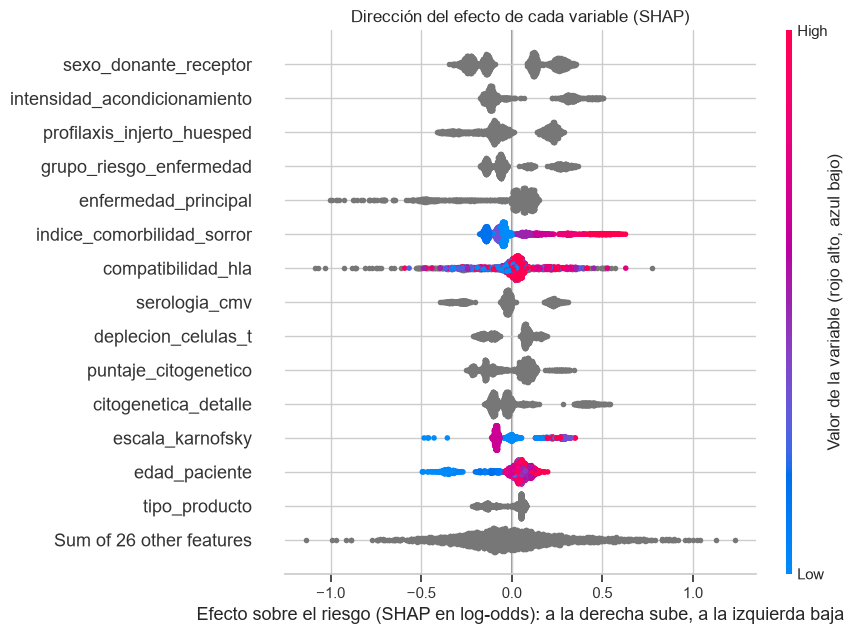

In [50]:
# Beeswarm con un punto por paciente
shap.plots.beeswarm(explicacion, max_display=15, show=False)
figura = plt.gcf()
figura.set_size_inches(9, 6.5)
figura.axes[0].set_xlabel(f"Efecto sobre el riesgo (SHAP en {ESCALA_SHAP}): a la derecha sube, a la izquierda baja")
if len(figura.axes) > 1:
    figura.axes[-1].set_ylabel("Valor de la variable (rojo alto, azul bajo)")
plt.title("Dirección del efecto de cada variable (SHAP)")
plt.tight_layout()
guardar_figura("shap_beeswarm", RUN_FINAL)

Análisis: en las variables numéricas, el color indica la dirección del efecto. Un índice de Sorror alto (rojo) sube el riesgo y uno bajo (azul) lo baja, y lo mismo pasa con el número de comorbilidades. En la edad, los pacientes más jóvenes (azul) tienen las contribuciones más negativas, hasta cerca de -0.5. En la escala de Karnofsky los colores se mezclan: valores altos (rojo) aparecen a los dos lados del cero, una señal de que su efecto no sigue un orden claro. En compatibilidad_hla el color es el número de coincidencias sobre 8 y también se mezcla, con una cola de pacientes a la izquierda que el modelo separa por su nivel o por el Sin dato. Las variables categóricas aparecen en gris y se detallan en la siguiente gráfica.

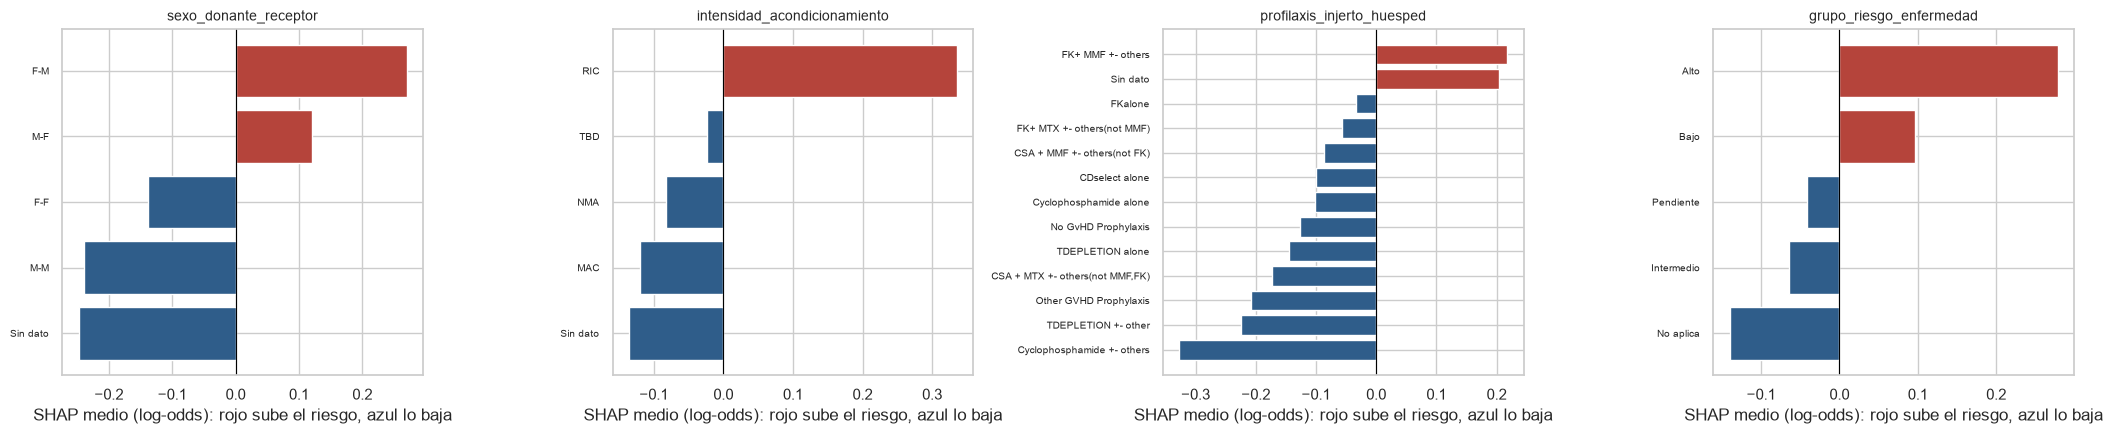

In [51]:
# SHAP medio por categoría en las cuatro variables categóricas más importantes
top_categoricas = [c for c in importancia_shap.index if c in categoricas][:4]
fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, col in zip(axes, top_categoricas):
    media = df_shap[col].groupby(X_shap[col].fillna("Sin dato").values).agg(["mean", "size"])
    media = media[media["size"] >= 15].sort_values("mean")
    ax.barh(media.index.astype(str), media["mean"], color=[ROJO if v > 0 else AZUL for v in media["mean"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(f"SHAP medio ({ESCALA_SHAP}): rojo sube el riesgo, azul lo baja")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
guardar_figura("shap_categorias", RUN_FINAL)

Análisis: en sexo_donante_receptor, donante mujer con receptor hombre (F-M) es la combinación que más sube el riesgo, seguida de donante hombre con receptor mujer (M-F); donante y receptor hombres (M-M), los pocos pacientes sin dato y donante y receptor mujeres (F-F) lo bajan. El acondicionamiento de intensidad reducida (RIC) sube el riesgo y el intenso (MAC) lo baja; los pacientes sin dato reciben el valor más frecuente (MAC) y por eso se comportan de forma parecida. En profilaxis_injerto_huesped, el esquema FK + MMF y los pacientes sin dato (que reciben ese mismo valor, el más frecuente) suben el riesgo, y casi todos los demás esquemas lo bajan, sobre todo Cyclophosphamide +- others. En el grupo de riesgo de la enfermedad, Alto sube el riesgo y No aplica (enfermedades no malignas y pacientes pediátricos) lo baja más que Intermedio; Bajo también aparece subiéndolo un poco, algo que no tiene una explicación clínica evidente y conviene revisar con el equipo médico.

In [52]:
# Valor que más sube y que más baja el riesgo en las 8 variables con más peso
def grupos_shap(col):
    serie = X_shap["hla_alta_res_8"] if col == "compatibilidad_hla" else X_shap[col]
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() > 12:
        return pd.qcut(serie.astype(float), 5, duplicates="drop").astype(object).map(
            lambda iv: f"{np.floor(iv.left) + 1:.0f} a {iv.right:.0f}" if isinstance(iv, pd.Interval) else "Sin dato")
    return serie.astype(object).where(serie.notna(), "Sin dato").astype(str)


filas = []
for col in importancia_shap.index[:8]:
    media = df_shap[col].groupby(grupos_shap(col).values).agg(["mean", "size"])
    media = media[media["size"] >= 50]
    for direccion, valor in (("sube", media["mean"].idxmax()), ("baja", media["mean"].idxmin())):
        filas.append({"variable": col, "efecto": direccion, "valor": valor, "pacientes": int(media.loc[valor, "size"]),
                      f"SHAP medio ({ESCALA_SHAP})": media.loc[valor, "mean"],
                      "puntos de riesgo sobre un paciente promedio": (a_riesgo(valor_base + media.loc[valor, "mean"]) - riesgo_base) * 100})
efectos_tipicos = pd.DataFrame(filas).set_index(["variable", "efecto"])
registrar_tabla(RUN_FINAL, efectos_tipicos, "efectos_tipicos")
print(f"Paciente promedio: riesgo de {riesgo_base:.1%}")
efectos_tipicos.round(3)

Paciente promedio: riesgo de 52.6%


valor  pacientes  \
variable                     efecto                                          
sexo_donante_receptor        sube                           F-M        541   
                             baja                           M-M        549   
intensidad_acondicionamiento sube                           RIC        575   
                             baja                      Sin dato        331   
profilaxis_injerto_huesped   sube             FK+ MMF +- others        740   
                             baja    Cyclophosphamide +- others        159   
grupo_riesgo_enfermedad      sube                          Alto        446   
                             baja                     No aplica        514   
enfermedad_principal         sube                           ALL        563   
                             baja                           IIS         67   
indice_comorbilidad_sorror   sube                             6         50   
                             baja                             1        357   
compatibilidad_hla           sube                          Alta       1148   
                             baja                      Sin dato        393   
serologia_cmv                sube                           -/+        485   
                             baja                           +/-        278   

                                     SHAP medio (log-odds)  \
variable                     efecto                          
sexo_donante_receptor        sube                    0.270   
                             baja                   -0.240   
intensidad_acondicionamiento sube                    0.336   
                             baja                   -0.136   
profilaxis_injerto_huesped   sube                    0.218   
                             baja                   -0.327   
grupo_riesgo_enfermedad      sube                    0.278   
                             baja                   -0.140   
enfermedad_principal         sube                    0.112   
                             baja                   -0.483   
indice_comorbilidad_sorror   sube                    0.480   
                             baja                   -0.140   
compatibilidad_hla           sube                    0.049   
                             baja                   -0.123   
serologia_cmv                sube                    0.230   
                             baja                   -0.290   

                                     puntos de riesgo sobre un paciente promedio  
variable                     efecto                                               
sexo_donante_receptor        sube                                          6.638  
                             baja                                         -5.987  
intensidad_acondicionamiento sube                                          8.217  
                             baja                                         -3.391  
profilaxis_injerto_huesped   sube                                          5.374  
                             baja                                         -8.150  
grupo_riesgo_enfermedad      sube                                          6.846  
                             baja                                         -3.502  
enfermedad_principal         sube                                          2.787  
                             baja                                        -11.971  
indice_comorbilidad_sorror   sube                                         11.603  
                             baja                                         -3.504  
compatibilidad_hla           sube                                          1.212  
                             baja                                         -3.077  
serologia_cmv                sube                                          5.671  
                             baja                                         -7.247

Análisis: la tabla traduce SHAP a puntos de riesgo sobre un paciente promedio (52.6%). El valor que más sube el riesgo es un índice de Sorror de 6 (11.6 puntos más, aunque solo 50 pacientes de la muestra lo tienen), seguido de la intensidad reducida del acondicionamiento (RIC, 8.2 puntos), el grupo de riesgo Alto (6.8) y la combinación F-M (6.6). Los que más lo bajan son la enfermedad principal IIS, trastornos del sistema inmune (12.0 puntos menos, en 67 pacientes), la profilaxis Cyclophosphamide +- others (8.2), la serología de CMV +/- (7.2) y la combinación M-M (6.0). En compatibilidad HLA el efecto es pequeño: el nivel Alta sube 1.2 puntos y el Sin dato baja 3.1. Esta tabla explica por qué la importancia global y el efecto de un valor concreto no siempre coinciden: el sexo de donante y receptor mueve unos 6 puntos a casi todos los pacientes, mientras que un Sorror de 6 mueve casi 12, pero a pocos.

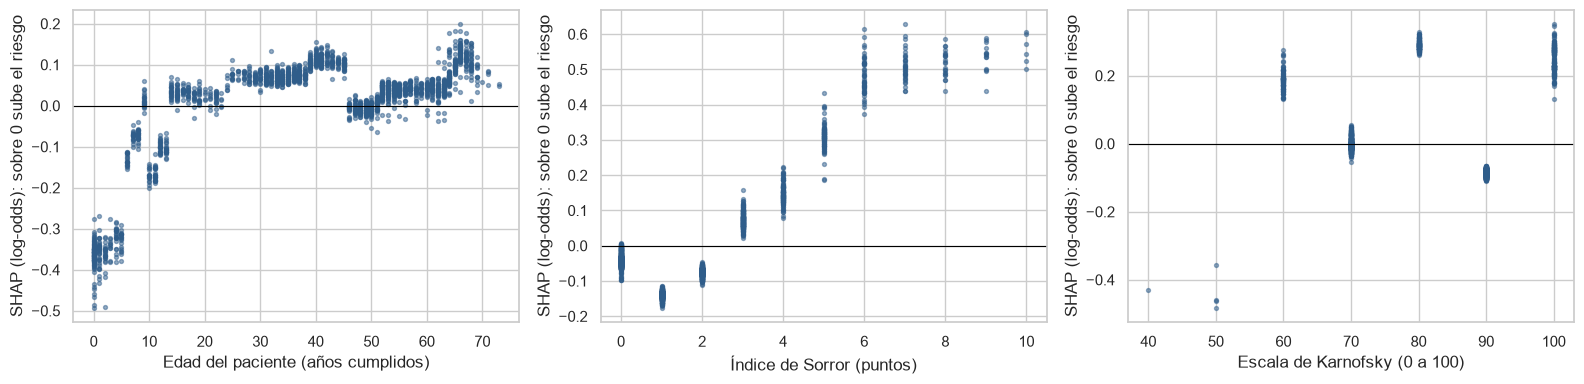

In [53]:
# Contribución de tres variables numéricas según su valor
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, titulo) in zip(axes, {"edad_paciente": "Edad del paciente (años cumplidos)", "indice_comorbilidad_sorror": "Índice de Sorror (puntos)",
                                     "escala_karnofsky": "Escala de Karnofsky (0 a 100)"}.items()):
    ax.scatter(X_shap[col].astype(float), df_shap[col], s=8, alpha=0.5, color=AZUL)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(titulo)
    ax.set_ylabel(f"SHAP ({ESCALA_SHAP}): sobre 0 sube el riesgo")
plt.tight_layout()
guardar_figura("shap_dependencia", RUN_FINAL)

Análisis: en la edad, los niños pequeños tienen la contribución más negativa (alrededor de -0.4 y hasta -0.5), el efecto cruza el cero cerca de los 13 años, se mantiene positivo en los adultos y vuelve a subir después de los 65. En el índice de Sorror el patrón es casi una escalera: de 0 a 2 puntos baja el riesgo, desde 3 lo sube y desde 6 se estabiliza en el valor más alto (cerca de +0.5). La escala de Karnofsky no muestra un patrón ordenado: 60, 80 y 100 suben el riesgo, 70 queda en cero, 90 lo baja y los pocos pacientes con 40 o 50 lo bajan aún más. Que una escala de 100 (el mejor estado funcional) suba el riesgo no tiene sentido clínico; es el mismo patrón desordenado de la sección 5.2 que el modelo aprovecha, y la razón por la que agrupar Karnofsky le restaba capacidad. Su efecto no debe leerse por sí solo.

## 12.4 Explicación de pacientes individuales

El gráfico de cascada parte del valor base (el riesgo promedio) y suma, una por una, las contribuciones de las variables de ese paciente hasta llegar a su predicción. Las barras rojas suben el riesgo y las azules lo bajan. Debajo de cada gráfico, una tabla traduce las contribuciones más grandes a puntos de riesgo: cuánto cambiaría la probabilidad del paciente si se quitara solo esa contribución.

,valor del paciente,contribución (log-odds),puntos de riesgo
indice_comorbilidad_sorror,7,0.472,1.869
citogenetica_detalle,Poor,0.391,1.486
enfermedad_cardiaca,Yes,0.369,1.389
enfermedad_pulmonar_severa,Yes,0.367,1.379
escala_karnofsky,80,0.323,1.190
intensidad_acondicionamiento,RIC,0.311,1.137
profilaxis_injerto_huesped,FK+ MMF +- others,0.229,0.806
compatibilidad_hla,8 de 8 (Alta),0.214,0.747


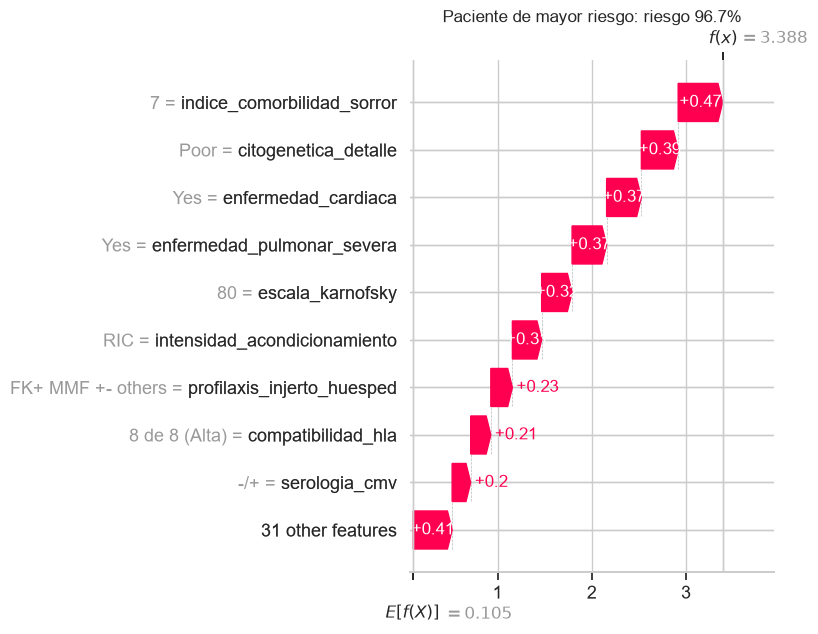

In [54]:
# Explicación del paciente con mayor riesgo de la muestra
prob_shap = pipelineFinal.predict_proba(X_shap)[:, 1]


def explicar_paciente(posicion, titulo, nombre_figura):
    fila = df_shap.iloc[posicion]
    hla8 = df_val.loc[X_shap.index[posicion], "hla_alta_res_8"]
    texto_hla = "Sin dato" if hla8 < 0 else f"{hla8} de 8 ({X_shap.iloc[posicion]['hla_alta_res_8']})"
    valores = [texto_hla if c == "compatibilidad_hla" else X_shap.iloc[posicion].get(c, "") for c in fila.index]
    valores = ["Sin dato" if not isinstance(v, str) and pd.isna(v) else v for v in valores]
    plt.figure(figsize=(9, 5))
    shap.plots.waterfall(shap.Explanation(values=fila.values, base_values=valor_base, data=np.array(valores, dtype=object),
                                          feature_names=list(fila.index)), max_display=10, show=False)
    plt.title(f"{titulo}: riesgo {prob_shap[posicion]:.1%}")
    plt.tight_layout()
    guardar_figura(nombre_figura, RUN_FINAL)
    # Puntos de riesgo que se perderían al quitar cada contribución
    total = valor_base + fila.sum()
    principales = fila.reindex(fila.abs().sort_values(ascending=False).index[:8])
    return pd.DataFrame({"valor del paciente": [valores[list(fila.index).index(c)] for c in principales.index],
                         f"contribución ({ESCALA_SHAP})": principales.values,
                         "puntos de riesgo": [(a_riesgo(total) - a_riesgo(total - v)) * 100 for v in principales.values]},
                        index=principales.index).round(3)


explicar_paciente(int(np.argmax(prob_shap)), "Paciente de mayor riesgo", "shap_paciente_alto")

Análisis: este paciente tiene un riesgo de 96.7%. Parte del 52.6% promedio y lo que más lo empuja hacia arriba es un índice de Sorror de 7, citogenetica_detalle en Poor (un resultado genético de mal pronóstico), enfermedad cardíaca, enfermedad pulmonar severa, una escala de Karnofsky de 80, acondicionamiento de intensidad reducida, la profilaxis FK + MMF, una compatibilidad HLA de 8 de 8 y serologia_cmv en -/+ (el donante no ha tenido contacto con el citomegalovirus y el paciente sí). Ninguna de las variables que se muestran le baja el riesgo. La tabla muestra que, como ya está cerca del 100%, quitar cualquiera de esas contribuciones le bajaría el riesgo solo entre 0.7 y 1.9 puntos: en riesgos extremos cada factor mueve poco la probabilidad, como mostró la sección 12.1.

In [55]:
# Explicación del paciente con menor riesgo de la muestra
explicar_paciente(int(np.argmin(prob_shap)), "Paciente de menor riesgo", "shap_paciente_bajo")

,valor del paciente,contribución (log-odds),puntos de riesgo
enfermedad_principal,IIS,-0.461,-2.696
edad_paciente,3,-0.341,-1.887
sexo_donante_receptor,M-M,-0.332,-1.832
serologia_cmv,+/-,-0.309,-1.687
enfermedad_hepatica_severa,Not done,-0.265,-1.416
profilaxis_injerto_huesped,TDEPLETION +- other,-0.257,-1.368
ulcera_peptica,Not done,-0.233,-1.228
deplecion_celulas_t,Yes,-0.164,-0.838


Análisis: este paciente tiene un riesgo de 5.0%. Es un niño de 3 años con un trastorno del sistema inmune (IIS), una de las enfermedades con menos eventos en la sección 5.2, con donante y receptor hombres, serología de CMV +/-, profilaxis con depleción de células T y sin dato de intensidad del acondicionamiento. La contribución más grande viene de la enfermedad principal (-0.46 en log-odds, 2.7 puntos de riesgo); la siguen la edad, la combinación M-M y la serología de CMV. También le bajan el riesgo dos comorbilidades marcadas como Not done (enfermedad hepática severa y úlcera péptica), es decir, no evaluadas: igual que los datos vacíos, no evaluar algo se asocia en estos datos a pacientes de menos riesgo y no debe leerse como un efecto clínico. Son muchos factores pequeños que suman en la misma dirección: además de los nueve que se muestran, las otras 31 variables restan 0.54 en log-odds.

# 13. Exportación del modelo y registro en MLflow

El pipeline elegido se reentrena con todo df_model (df_train, df_val y df_test) con los mismos hiperparámetros, para aprovechar todos los pacientes en la aplicación. Las métricas reportadas siguen siendo las del modelo entrenado solo con df_train, porque el modelo reentrenado ya no tiene pacientes nuevos con qué medirse.

Archivos que se guardan en despliegue/artefactos/ y que usa la aplicación:

- modelo_hct.joblib: el Pipeline completo (preprocesamiento y modelo).
- metadatos.json: umbral, métricas, intervalos, comparación de modelos, resultado del ajuste, deciles, importancias, reglas de limpieza, opciones válidas y rangos del formulario.
- fondo_shapley.csv: 200 pacientes de referencia para las explicaciones de la aplicación.
- pacientes_ejemplo.csv: 5 pacientes para probar la aplicación.
- requirements_modelo.txt: versiones de las librerías con que se entrenó.

En MLflow el modelo de despliegue queda registrado con el nombre riesgo_post_trasplante, junto con una copia de estos archivos.

In [56]:
# Pipeline de despliegue entrenado con todo df_model
pipelineDespliegue = clone(pipelineFinal).fit(preparar_X(df_model), df_model["evento_12m"])
joblib.dump(pipelineDespliegue, CARPETA_ARTEFACTOS / "modelo_hct.joblib")

# Pacientes de referencia y de ejemplo sin las columnas de resultado
df_raw.drop(columns=["efs", "efs_time"]).sample(200, random_state=SEMILLA).to_csv(CARPETA_ARTEFACTOS / "fondo_shapley.csv", index=False)
df_raw.drop(columns=["efs", "efs_time"]).sample(5, random_state=7).to_csv(CARPETA_ARTEFACTOS / "pacientes_ejemplo.csv", index=False)

# Variables del formulario de la aplicación antes de la limpieza
df_formulario = df_raw.rename(columns=NOMBRES).drop(columns=COLUMNAS_ELIMINADAS + [c for c in COLUMNAS_NO_PREDICTORAS if c != "evento_12m"])
df_formulario[["edad_paciente", "edad_donante"]] = np.floor(df_formulario[["edad_paciente", "edad_donante"]])
a_python = lambda v: float(v) if isinstance(v, (np.floating, float)) else int(v) if isinstance(v, (np.integer, int)) else v

metadatos = {
    "modelo": mejor_nombre,
    "hiperparametros": {k: a_python(v) for k, v in mejores_parametros.items()},
    "seleccion": f"{mejor_nombre}, porque {motivo}",
    "umbral": UMBRAL,
    "nombres_originales": NOMBRES,
    "columnas_eliminadas": COLUMNAS_ELIMINADAS,
    "variables_geneticas": VARIABLES_GENETICAS,
    "columnas_hla": COLUMNAS_HLA,
    "variables_agrupadas": VARIABLES_AGRUPADAS,
    "columnas_entrada": COLUMNAS_ENTRADA,
    "tratamiento_columnas": {"hla": hla, "continuas_escaladas": continuas, "binarias_sin_escalar": binarias, "categoricas": categoricas},
    "descripciones": {NOMBRES[k]: v for k, v in descripcion_oficial.items() if k in NOMBRES and isinstance(v, str)},
    "fuente_diccionario": "https://www.kaggle.com/competitions/equity-post-HCT-survival-predictions/data",
    "variables_formulario": list(df_formulario.columns),
    "opciones": {c: sorted(df_formulario[c].dropna().astype(str).unique().tolist()) for c in df_formulario.select_dtypes(exclude="number").columns},
    "rangos": {c: [a_python(df_formulario[c].min()), a_python(df_formulario[c].median()), a_python(df_formulario[c].max())]
               for c in df_formulario.select_dtypes("number").columns},
    "metricas_prueba": {k: float(v) for k, v in resumen_test.items()},
    "intervalos_prueba": {k: [float(tabla_ic.loc[k, "IC 95% inferior"]), float(tabla_ic.loc[k, "IC 95% superior"])] for k in tabla_ic.index},
    "comparacion_modelos": {n: {"auc_cv_media": float(resultados_cv[n]["test_auc"].mean()), "auc_cv_desv": float(resultados_cv[n]["test_auc"].std())}
                            for n in orden},
    "ajuste": {"metodo": "GridSearchCV", "combinaciones": int(len(resultados_grid)), "auc_cv_gridsearch": float(busquedaGridSearch.best_score_),
               "auc_val_ajustado": float(auc_val), "auc_val_sin_ajustar": float(auc_val_sin)},
    "deciles_prueba": tabla_deciles.reset_index().astype({"decil": str}).round(4).to_dict(orient="records"),
    "importancia_shap": importancia_shap.round(5).astype(float).to_dict(),
    "escala_shap": ESCALA_SHAP,
    "importancia_shap_puntos": puntos_riesgo[importancia_shap.index].round(4).astype(float).to_dict(),
    "importancia_permutacion": importancia_permutacion["aumento del log-loss"].round(5).astype(float).to_dict(),
    "tasa_base": float(df_model["evento_12m"].mean()),
    "pacientes_despliegue": int(len(df_model)),
    "semilla": SEMILLA,
    "versiones": VERSIONES,
}
(CARPETA_ARTEFACTOS / "metadatos.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding="utf-8")
(CARPETA_ARTEFACTOS / "requirements_modelo.txt").write_text(
    "\n".join(f"{k}=={VERSIONES[k]}" for k in ["scikit-learn", "pandas", "numpy", "joblib", "xgboost"]) + "\n", encoding="utf-8")

# Registro del modelo de despliegue en MLflow con una copia de los artefactos
with iniciar_run(f"modelo_despliegue | {mejor_nombre}") as run:
    mlflow.log_params({"modelo": mejor_nombre, **mejores_parametros, "umbral": round(UMBRAL, 4), "pacientes_entrenamiento": len(df_model)})
    mlflow.log_metrics({f"test_{CLAVES_METRICAS[k]}": v for k, v in resumen_test.items()})
    info_modelo = mlflow.sklearn.log_model(pipelineDespliegue, name="modelo", serialization_format="cloudpickle",
                                           input_example=X_train.dropna().head(5), registered_model_name="riesgo_post_trasplante")
    mlflow.log_artifacts(str(CARPETA_ARTEFACTOS), "artefactos_despliegue")
print("Archivos exportados:", sorted(p.name for p in CARPETA_ARTEFACTOS.iterdir()))
print("Versión registrada en MLflow del modelo riesgo_post_trasplante:", info_modelo.registered_model_version)

Archivos exportados: ['fondo_shapley.csv', 'metadatos.json', 'modelo_hct.joblib', 'pacientes_ejemplo.csv', 'requirements_modelo.txt']
Versión registrada en MLflow del modelo riesgo_post_trasplante: 2


Registered model 'riesgo_post_trasplante' already exists. Creating a new version of this model...
Created version '2' of model 'riesgo_post_trasplante'.


Análisis: la exportación deja en despliegue/artefactos/ los cinco archivos que usa la aplicación. El modelo de despliegue se reentrenó con los 28,562 pacientes de df_model y quedó registrado en MLflow como la versión 2 del modelo riesgo_post_trasplante, junto con una copia de estos archivos. metadatos.json guarda también qué variables se agrupan y el tratamiento de cada tipo de columna, para que la aplicación aplique exactamente la misma preparación.

# 14. Conclusiones, condiciones de validez y próximos pasos

## Resultados

- El problema de supervivencia se convirtió en una clasificación a 12 meses porque la decisión clínica es binaria, el 96.8% de los eventos ocurre en el primer año y la censura solo obliga a excluir al 0.8% de los pacientes. Los horizontes de 6 y 18 meses dan un AUC parecido, pero pierden eventos o pacientes.
- Las variables quedan como en la práctica: edades en años cumplidos, diferencia de edad entera y sin signo, escalas como enteros y las 17 HLA con -1 cuando la prueba no se hizo. El año del trasplante no se usa como predictor, porque su efecto coincide con los años de registros incompletos.
- Cada variable recibe solo el tratamiento que necesita: las 6 continuas y escalas se imputan con la mediana y se escalan, las 2 binarias se dejan en 0 y 1, las 31 categóricas pasan por OneHotEncoder y la compatibilidad HLA se agrupa en cuatro niveles (Sin dato, Baja, Media y Alta). Agrupar HLA mejoró a la regresión logística sin costarle a XGBoost; agrupar Sorror, Karnofsky o el número de comorbilidades no mejoró a ningún modelo, así que quedan como número.
- La imputación con el valor más frecuente redujo de 31.6 a 7.1 puntos la caída del riesgo al borrarle datos a un paciente, aunque no la elimina del todo. Con HLA agrupada, PCA ya no ayuda y no se usa; las clases están casi balanceadas y SMOTE no mejoró el resultado.
- XGBClassifier tuvo el mejor AUC de seis modelos en validación cruzada (0.7309 ± 0.0075), pero su ventaja sobre LogisticRegression (0.7295) no es significativa según la prueba de Wilcoxon (p = 0.322): los dos ordenan el riesgo casi igual. Ajustado con GridSearchCV (120 combinaciones) usa 800 árboles de profundidad 2, tasa de aprendizaje 0.06 y al menos 10 pacientes por hoja.
- En df_test, que no se usó para ninguna decisión, logra un AUC de 0.738 (con 95% de confianza, entre 0.721 y 0.752), detecta el 66.1% de los eventos y el 68.9% de sus alertas son correctas, con probabilidades bien calibradas. Sacar el año del trasplante costó unos 0.006 de AUC frente a la versión anterior, a cambio de un modelo que no depende de la fecha. Los índices clínicos usados por separado (Sorror, Karnofsky y grupo de riesgo de la enfermedad) no pasan de 0.612.
- El modelo separa con claridad a los pacientes: 12.6% de eventos en el decil de menor riesgo y 84.1% en el de mayor riesgo.
- Se equivoca sobre todo en casos dudosos cerca del umbral y en eventos de pacientes con perfil de bajo riesgo: niños, injertos de médula ósea y formularios incompletos. En los niños el umbral general solo detecta el 33.1% de los eventos.
- Según SHAP y la importancia por permutación, el riesgo depende sobre todo de la intensidad del acondicionamiento, la combinación de sexos de donante y receptor, la profilaxis, la enfermedad y su grupo de riesgo, la compatibilidad HLA y la fragilidad del paciente (Sorror y edad).

## Condiciones de validez

- A qué datos aplica: pacientes de trasplante alogénico como los del registro del CIBMTR entre 2008 y 2020, con la información disponible antes del trasplante. Los datos de la competencia son sintéticos: reproducen los patrones del registro real, pero no son pacientes reales.
- Qué garantiza: en pacientes de esa misma población, un AUC de alrededor de 0.74 (entre 0.721 y 0.752 con 95% de confianza) y probabilidades que se pueden leer de forma casi literal.
- Qué no garantiza: el desempeño en otros países, centros o años futuros, porque la validación no separó por fechas y los años recientes tienen registros incompletos; que el patrón de los datos vacíos se repita en otros registros; ni una lectura causal de los factores. Algunos efectos no tienen sentido clínico (una escala de Karnofsky de 100 sube el riesgo, el grupo de riesgo Bajo lo sube un poco y la compatibilidad HLA completa no lo baja), así que el modelo sirve para ordenar pacientes por riesgo, no para explicar por qué ocurre el evento.

## Próximos pasos para llevarlo a producción

- Validarlo con pacientes reales de un centro, idealmente de años recientes, y medir de nuevo el AUC y la calibración.
- Comparar en esos datos XGBoost con la regresión logística, que aquí rinde casi igual y es más fácil de explicar.
- Recalibrarlo con datos locales y fijar un umbral propio para niños y para injertos de médula ósea.
- Revisar con el equipo médico los efectos que no tienen sentido clínico antes de usar las explicaciones con pacientes.
- Integrarlo con la historia clínica, vigilar en el tiempo los datos vacíos y el desempeño, y volver a entrenarlo cuando cambie la población.